<!-- repo-header -->
# H2-1 submission, and the shadow-overlap calibration curve

Two distinct jobs live in this notebook.

**1. Hardware submission (needs a Quantinuum account).** Uploads the compiled
circuit to Quantinuum Nexus and runs the shadow-overlap protocol on the H2-1
emulator and on the physical device: 1000 shots, each picking a random qubit k and
measuring it in X, Y or Z while the other 12 are measured in Z. Results are
accumulated per basis `(k, p)` and written to `shadow_results_hardware.pkl` and
`shadow_results_emulator.pkl`.

**2. The classical calibration curve (runs anywhere, no account needed).** The
section "Classically Simulated Workflow" is the important one for reproducibility.
The shadow overlap E[omega] is a *witness*, not an estimator -- the worst-case bound
F >= 1 - tau(1 - omega) is far too loose to be useful (at tau = 17.49 and
omega = 0.967 it gives only F >= 0.42). So the relationship is calibrated
numerically instead: sample states of known fidelity

    |phi> = sqrt(beta) |psi~> + sqrt(1 - beta) |eta~>,   beta ~ U[0,1]

simulate the protocol on each, and record (omega, F). Inverting that scatter by
local linear regression is what converts the measured omega into the quoted
`F_hw ~ 0.91`.

Writes: `shadows_vs_fidelity.npy` (the calibration curve, thesis Figure 4.3),
`shadow_results_noiseless.npy`, `shadow_results_{hardware,emulator}.pkl`.

> **Credentials are not in this repository.** The auth cell reads `QNX_USER` and
> `QNX_PASS` from the environment. Nothing downstream of the analysis notebooks
> needs it -- they read the committed result files.


In [1]:
from qiskit import QuantumCircuit
from pytket.extensions.qiskit import qiskit_to_tk
from qnexus import QuantinuumConfig
import qnexus as qnx
from pytket import OpType
from qnexus.models.references import CircuitRef
import pickle


In [ ]:
# Quantinuum Nexus authentication.
#
# Credentials are deliberately NOT stored in this repository. Supply them at run
# time, e.g. from environment variables:
#
#     export QNX_USER="you@example.com"
#     export QNX_PASS="..."
#
# Everything downstream of this cell -- every job submission -- requires a
# Quantinuum account with H2-1 access. The analysis and plotting notebooks do
# NOT need this cell: they read the committed result files instead.
import os

qnx.client.auth.login_no_interaction(
    user=os.environ["QNX_USER"],
    pwd=os.environ["QNX_PASS"],
)

# Test with quantinium's documentation

In [26]:
import qnexus as qnx

project = qnx.projects.get_or_create(name="Nexus-Workflow-Demonstration")
qnx.context.set_active_project(project)

In [27]:
from pytket.circuit import Circuit

test_circuit = Circuit(10)
test_circuit.H(0)
for i, j in zip(test_circuit.qubits[:-1], test_circuit.qubits[1:]):
    test_circuit.CX(i, j)
test_circuit.measure_all();

In [28]:
ref = qnx.circuits.upload(circuit=test_circuit, name=f"GHZ-Circuit-{jobname_suffix}")

In [38]:
config = qnx.QuantinuumConfig(device_name="H2-1E")

In [39]:
ref_compile_job = qnx.start_compile_job(
    programs=[ref],
    backend_config=config,
    optimisation_level=2,
    name=f"compilation-job-{jobname_suffix}",
)

In [40]:
ref_compiled_circuit = qnx.jobs.results(ref_compile_job)[0].get_output()

In [41]:
compiled_circuit = ref_compiled_circuit.download_circuit()

In [42]:
from pytket.circuit.display import render_circuit_jupyter

render_circuit_jupyter(compiled_circuit)

In [43]:
print(compiled_circuit.n_1qb_gates())
print(compiled_circuit.n_2qb_gates())

19
9


okay cool so this has given us the correct numbers of these gates for the circuit! Awesome! I tried this with the emulator and the syntax checker so I guess they do the same?

In [44]:
qnx.client.circuits.cost(
    circuit_ref = ref_compiled_circuit,
    n_shots = 10,
    backend_config = config
)

JobError: Job errored with detail: <class 'pytket.extensions.quantinuum.backends.quantinuum.DeviceNotAvailable'>: H2-1ESC

okay this is the cost of the job in HQC I think? unsure what the syntax checker does? Can you "run" the syntax checker in the same way you can with the emulator and the hardware?

Just tried running this command when config was the emulator and it did not like it! Looks like the above command only works when config is set to the syntax checker.

In [45]:
ref_execute_job = qnx.start_execute_job(
    programs=[ref_compiled_circuit],
    n_shots=[10],
    backend_config=config,
    name=f"execution-job-{jobname_suffix}",
)

In [59]:
qnx.jobs.status(ref_execute_job)

JobStatus(status=<JobStatusEnum.COMPLETED: 'COMPLETED'>, message='The job is completed.', error_detail=None, completed_time=datetime.datetime(2026, 2, 23, 12, 18, 29, 445285, tzinfo=datetime.timezone.utc), queued_time=datetime.datetime(2026, 2, 23, 12, 16, 37, 718775, tzinfo=datetime.timezone.utc), submitted_time=datetime.datetime(2026, 2, 23, 12, 16, 37, 702796, tzinfo=datetime.timezone.utc), running_time=datetime.datetime(2026, 2, 23, 12, 18, 24, 277239, tzinfo=datetime.timezone.utc), cancelled_time=None, error_time=None, queue_position=None, cost=5.41)

In [ ]:
#This stores the referenc enumber for the job.,
with open('testing_H2-1E.pkl', 'wb') as file:
    pickle.dump([ref_execute_job], file)

In [69]:
with open('testing_H2-1E.pkl', 'rb') as file:
    job_refs = pickle.load(file)

In [71]:
results=qnx.client.jobs.results(job_refs[0])[0]
download_results=results.download_result()

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

In [72]:
print(job_refs)

[ExecuteJobRef(id=UUID('869bee34-e000-4c39-a65f-3bd275e9c382'), annotations=Annotations(name='execution-job-2026_02_23-19-31-51', description='', properties=OrderedDict(), created=datetime.datetime(2026, 2, 23, 12, 15, 58, 90665, tzinfo=TzInfo(0)), modified=datetime.datetime(2026, 2, 23, 12, 15, 58, 90665, tzinfo=TzInfo(0))), job_type=<JobType.EXECUTE: 'execute'>, last_status=<JobStatusEnum.SUBMITTED: 'SUBMITTED'>, last_message='', last_status_detail=None, project=ProjectRef(id=UUID('7bead4e4-e232-4ca9-a007-245f18d2fa9f'), annotations=Annotations(name='Nexus-Workflow-Demonstration', description=None, properties=OrderedDict(), created=datetime.datetime(2026, 2, 23, 11, 36, 39, 914038, tzinfo=TzInfo(0)), modified=datetime.datetime(2026, 2, 23, 11, 36, 39, 914038, tzinfo=TzInfo(0))), contents_modified=datetime.datetime(2026, 2, 23, 11, 36, 39, 918983, tzinfo=TzInfo(0)), archived=False, type='ProjectRef'), system=None, backend_config_store=QuantinuumConfig(type='QuantinuumConfig', device_n

In [65]:
ref_result = qnx.jobs.results(ref_execute_job)[0]
backend_result = ref_result.download_result()

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

# Run of acoustic circuit!

In [74]:
import qnexus as qnx

project = qnx.projects.get_or_create(name="State Preparation and Shadow Overlap")
qnx.context.set_active_project(project)

In [50]:
# Load in Accoustic Circuit
from pytket.circuit import Circuit, Unitary1qBox, Unitary2qBox
import numpy as np
def make_unitary(U):
    U = np.array(U)
    V, _, W = np.linalg.svd(U)
    return V @ W
def arch_apply_layer_tket(sorted_gates,qc,num_qubits):
    gate_count=0
    for idx in range(num_qubits-2,-1,-1):
        #qc.apply_gate_raw(sorted_gates[gate_count], (idx, idx+1), tags=['SU4'])
        u2 = sorted_gates[gate_count]
        u2=make_unitary(u2)
        u2box = Unitary2qBox(u2)
        qc.add_unitary2qbox(u2box, idx, idx+1)
        gate_count=gate_count+1
def arch_apply_tau_layer_tket(sorted_gates,qc,num_qubits):
    gate_count=0
    for idx in range(num_qubits):
        u1 = sorted_gates[gate_count]
        u1=make_unitary(u1)
        u1box = Unitary1qBox(u1)
        qc.add_unitary1qbox(u1box, idx)
        gate_count=gate_count+1
def arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,num_qubits,taued=True,basis_choice=False):
    '''Basis choice is (target_qubit,pauli), where tar starts from 0 and then the pauli is 0=X, 1=Y and 2=Z'''
    qc=Circuit(num_qubits)
    
    sorted_k_gates=[U.conj().T for U in sorted_k_gates]
    sorted_z_gates=[U.conj().T for U in sorted_z_gates]
    sorted_b_gates=[U.conj().T for U in sorted_b_gates]

    arch_apply_layer_tket(sorted_k_gates,qc,num_qubits)
    arch_apply_layer_tket(sorted_z_gates,qc,num_qubits)
    arch_apply_layer_tket(sorted_b_gates,qc,num_qubits)
    if taued:
      arch_apply_tau_layer_tket(tau_layer,qc,num_qubits)
    if basis_choice:
      target_qubit=basis_choice[0]
      unitary_id =basis_choice[1]
      print("Target Qubit is: ", target_qubit)
  
      #Apply pauli gate to qubit (nothing if Z)
      paulis = ['X', 'Y', 'Z']

      #if only comp basis selected then make sure we measure in Z.
      
      P = paulis[unitary_id]
      print("Will measure ",P, " at target qubit")
      if P == 'X':
        qc.H(target_qubit)            # H maps X->Z
      elif P == 'Y':
        qc.Sdg(target_qubit)          # Sdg (S dagger) then H maps Y->Z
        qc.H(target_qubit)
      # P == 'Z' → do nothing
    qc.measure_all()
    return qc
tau_layer=[np.array([[ 0.70756656+0.j        ,  0.70510361-0.04667407j],
        [-0.66757702+0.23171208j,  0.65166181-0.27565797j]]),
 np.array([[ 0.70646004+0.j        , -0.6039059 -0.36906893j],
        [ 0.2372931 +0.66678797j, -0.1449662 +0.69142649j]]),
 np.array([[ 0.76389571+0.j        , -0.63134767-0.13365428j],
        [ 0.64295216+0.05546051j,  0.73097187+0.22184855j]]),
 np.array([[ 0.74559257+0.j        ,  0.03857026-0.66528495j],
        [ 0.11278586+0.65678845j, -0.74090827+0.08344586j]]),
 np.array([[ 0.99917109+0.j        ,  0.01011472+0.03943119j],
        [-0.02436882+0.03260809j,  0.92388205+0.38050603j]]),
 np.array([[ 0.99961458+0.j        ,  0.02682634-0.00714454j],
        [-0.02579163+0.01027075j,  0.80223109-0.59636783j]]),
 np.array([[ 0.99981649+0.j        , -0.00387036+0.01876176j],
        [ 0.00883066+0.01700009j,  0.96207236-0.27212092j]]),
 np.array([[ 0.71461712+0.j        , -0.00869148+0.69946181j],
        [ 0.53887603+0.44602129j,  0.46245501-0.54480546j]]),
 np.array([[ 0.9999664 +0.j        ,  0.00811918-0.00113379j],
        [-0.00811019-0.00119639j,  0.99993664+0.00771393j]]),
 np.array([[ 0.99980298+0.j        , -0.01792838+0.0085195j ],
        [ 0.01134536-0.01628777j,  0.16402578-0.98625632j]]),
 np.array([[ 0.99991509+0.j        , -0.00534618-0.01188413j],
        [ 0.00643287+0.01133281j, -0.59053236+0.80690874j]]),
 np.array([[ 0.99999797+0.j        , -0.00169669-0.00108734j],
        [-0.00146146+0.00138752j, -0.9820911 +0.18839587j]]),
 np.array([[ 0.99994849+0.00000000e+00j, -0.01013957+4.48082824e-04j],
        [-0.00252882+9.82937960e-03j, -0.20614825+9.78468134e-01j]])]
sorted_k_gates=[np.array([[ 0.58202826+0.03064421j,  0.2211523 +0.66589927j,
         0.31456239+0.01467208j, -0.08062462-0.24961722j],
       [ 0.21442015-0.15826631j, -0.38193016-0.07747488j,
        -0.01207216-0.77562583j,  0.34533318-0.2368683j ],
       [ 0.08815743+0.32977098j,  0.09571298+0.29393884j,
        -0.29172782-0.37350674j, -0.06823435+0.74742894j],
       [-0.60646143+0.32398103j,  0.4414201 +0.25570314j,
         0.12592156-0.24212686j,  0.34689456-0.26867738j]]), np.array([[ 0.44552844+0.15794513j,  0.66797301+0.5592994j ,
        -0.11283244-0.02905615j,  0.03183672+0.05445167j],
       [-0.09733357+0.855663j  ,  0.23246245-0.40912809j,
         0.07423724-0.03686386j, -0.09281805-0.14648249j],
       [ 0.12614157-0.04675024j, -0.08832296+0.07383197j,
        -0.14336369+0.10399472j,  0.22148849-0.94245711j],
       [ 0.04027883-0.12330888j,  0.0781551 +0.01453717j,
         0.6354779 -0.73780368j,  0.019408  -0.16819601j]]), np.array([[ 0.64828808+0.5747724j , -0.12442896-0.41081484j,
        -0.06888901-0.10599752j,  0.00205952-0.22163585j],
       [ 0.0997587 +0.07837263j,  0.07700988+0.20810604j,
         0.64933299+0.57312201j, -0.12503056-0.41101397j],
       [-0.07949422-0.06547905j, -0.4600854 -0.42522884j,
         0.45789497+0.12939045j,  0.41654416+0.4438201j ],
       [ 0.45274918-0.13295315j,  0.56972027+0.22232999j,
         0.08476216-0.01795405j,  0.58351822+0.2352219j ]]), np.array([[ 0.52407372+0.461487j  , -0.40031671+0.38672605j,
        -0.20296601+0.21451742j,  0.2229162 +0.25624484j],
       [ 0.2432249 +0.16987124j,  0.21224962-0.2653005j ,
         0.35801352-0.5997838j ,  0.45552873+0.31801012j],
       [-0.03384098+0.35613347j, -0.14360225-0.30104796j,
         0.42340664+0.3572732j ,  0.32604748-0.58953199j],
       [-0.15906532-0.52065713j, -0.67983397-0.0364627j ,
         0.33589182+0.07163898j,  0.20981771+0.27952047j]]), np.array([[ 0.3195201 +0.28623376j, -0.39021268+0.67612951j,
         0.29130818+0.25674555j,  0.11327077-0.20724645j],
       [ 0.35619821-0.1541608j , -0.1448835 -0.18206131j,
        -0.13391825+0.40844378j, -0.77596986-0.09126936j],
       [-0.59401613+0.12715196j,  0.00234348-0.11431195j,
         0.6021543 +0.03509899j, -0.31027391-0.39725667j],
       [-0.45769029+0.29467142j,  0.35182842+0.44675435j,
        -0.43332058+0.33596486j, -0.20974368+0.18890249j]]), np.array([[ 0.50748849-0.38992088j,  0.26423653-0.37016937j,
        -0.27974655+0.22028492j,  0.29301619-0.41343532j],
       [ 0.21295812+0.2976991j , -0.40519303-0.29927838j,
         0.09443477-0.62699161j, -0.06438628-0.45397483j],
       [-0.52754712+0.32413781j, -0.00941132-0.37106295j,
        -0.67810661+0.08969459j,  0.08652006-0.05910172j],
       [ 0.253007  +0.09517038j,  0.26500474-0.57567434j,
         0.04397303-0.03704988j, -0.55460073+0.46304785j]]), np.array([[ 0.8465369 +0.1490747j ,  0.11381032+0.4065244j ,
         0.1188296 +0.03126009j, -0.06330886-0.25264888j],
       [ 0.12141814-0.0432531j , -0.19565552-0.17316475j,
         0.8616023 -0.00372001j,  0.18176981+0.37377409j],
       [-0.010625  +0.32042399j,  0.72045441+0.10184213j,
        -0.07680818-0.17377331j,  0.23720832+0.52480926j],
       [-0.02840682-0.37542968j, -0.14094034+0.45191532j,
        -0.15965058+0.42537632j,  0.63258819+0.16599045j]]), np.array([[ 0.6879807 -0.15085243j, -0.37283286-0.26820696j,
         0.33201212-0.07792622j,  0.38242064+0.17446116j],
       [ 0.22139692+0.47721791j, -0.23807596+0.7458153j ,
         0.12477684+0.20328617j,  0.10738893-0.2046923j ],
       [-0.02372256-0.38704301j,  0.04009478-0.0397363j ,
         0.08806785+0.90358429j,  0.06914538-0.13208626j],
       [-0.18861644+0.20305504j,  0.39338576-0.13491159j,
         0.01759658-0.04765265j,  0.81504929-0.28870959j]]), np.array([[ 0.20146529-0.40427636j,  0.57271501+0.66513107j,
        -0.09169325+0.12521773j, -0.0271526 -0.02731558j],
       [ 0.22493316+0.1184158j , -0.00507774+0.05414656j,
         0.80426111+0.39957849j, -0.09271839+0.342534j  ],
       [-0.82288616+0.19381148j, -0.06260719+0.46273796j,
         0.1224518 -0.08029448j,  0.02590225+0.21245428j],
       [-0.11617348-0.05616341j, -0.08175297+0.04371399j,
         0.21382396+0.3197681j ,  0.68024952-0.60335992j]]), np.array([[ 0.87066998+0.1150999j , -0.27420068-0.37600907j,
         0.09424396+0.02108211j, -0.03612314-0.03854494j],
       [ 0.372813  +0.19573726j,  0.21562763+0.7651584j ,
        -0.173029  -0.11540316j, -0.1221138 -0.36409618j],
       [ 0.19144084-0.0476141j ,  0.34638822+0.15401582j,
         0.38760483-0.29324391j,  0.65628003+0.38787196j],
       [-0.08856471-0.06799111j,  0.0876067 -0.00937547j,
         0.82228486+0.18717588j, -0.12840687-0.50209077j]]), np.array([[ 0.09265075-0.09016941j,  0.50203184+0.85223331j,
        -0.04579392-0.04069792j, -0.03215189-0.01267246j],
       [ 0.07778813+0.54951414j,  0.10262224+0.03513331j,
         0.20297511+0.08275016j,  0.7909637 +0.08091651j],
       [-0.41503278-0.58944628j, -0.04123336+0.03158399j,
         0.49248551-0.30923895j,  0.36718933-0.06785595j],
       [-0.1517764 +0.36405129j,  0.07315172+0.04298646j,
         0.75285865+0.20792608j, -0.44757153-0.16395699j]]), np.array([[ 0.94288573-0.27707098j, -0.07145321-0.02650028j,
        -0.15852259-0.05485833j,  0.00544126+0.01489628j],
       [-0.03329412-0.07890731j,  0.30523914-0.93573229j,
        -0.01239679-0.05010488j, -0.0441048 +0.138888j  ],
       [-0.04695647-0.08672901j,  0.0741091 -0.02479653j,
         0.04555413-0.6330607j ,  0.64230814-0.41081063j],
       [ 0.12257869+0.04594511j,  0.03183247-0.13529964j,
         0.38746771+0.6451548j ,  0.2426427 -0.58164661j]])]
sorted_z_gates=[np.array([[ 7.03134478e-01+0.64204651j,  1.32967243e-01-0.17099836j,
         1.35690170e-01+0.02980882j, -8.90878621e-02-0.13863772j],
       [ 1.54638248e-01-0.18665489j,  7.95244426e-01+0.5456483j ,
         9.06082570e-04+0.05827191j,  8.24846307e-02-0.03001751j],
       [-8.03907783e-02-0.11601588j, -8.88605746e-02+0.06222374j,
         9.07885923e-01+0.34394578j,  2.24949069e-02-0.15889641j],
       [ 1.18723479e-01-0.02464785j, -5.83552520e-02-0.08809188j,
         3.86060998e-02-0.18236555j,  9.65796737e-01-0.08136794j]]), np.array([[ 0.64571428+0.49596465j, -0.45380149-0.33907793j,
        -0.06694162-0.08015101j,  0.04724597+0.0549996j ],
       [ 0.4955781 +0.27439294j,  0.71747993+0.38491003j,
        -0.05431832-0.0482405j , -0.07904742-0.06820239j],
       [ 0.10117342+0.02561433j, -0.07058747-0.01696308j,
         0.72663724+0.36736893j, -0.50884918-0.24889436j],
       [ 0.07238447+0.00716485j,  0.10395368+0.00897127j,
         0.53788306+0.17758718j,  0.77647313+0.24506405j]]), np.array([[ 0.64636693+0.63721595j,  0.03666502+0.18464219j,
         0.15823873-0.3293842j ,  0.07512451-0.03938812j],
       [-0.19001252-0.03081503j,  0.64599194+0.63867178j,
         0.00114168+0.07497111j,  0.16872555-0.32194436j],
       [-0.08004571+0.3581736j , -0.06430601+0.04382427j,
        -0.90366332+0.09417753j, -0.15828807-0.0933628j ],
       [-0.0257416 -0.061262j  , -0.07977603+0.35628033j,
         0.14020559-0.12534022j, -0.90711751+0.063675j  ]]), np.array([[ 0.65471375+0.65571412j, -0.05704243-0.06013354j,
         0.05952997-0.33061483j,  0.14617432+0.01738101j],
       [ 0.00359358+0.04573564j, -0.15514195+0.95233419j,
         0.15024435+0.05351004j,  0.18091655-0.09337244j],
       [ 0.33468649-0.11782398j,  0.03022321-0.10588509j,
         0.75758999+0.51223815j, -0.15635953+0.03462008j],
       [ 0.1146089 -0.01585878j,  0.12341588+0.18645136j,
        -0.15557113+0.03435739j, -0.28460644+0.91117182j]]), np.array([[ 0.48765382+0.80428082j, -0.02004694+0.18623798j,
        -0.03871273+0.0552293j , -0.25148666+0.1115579j ],
       [-0.06720493-0.14190248j, -0.43673553+0.8552704j ,
         0.06123371-0.11849076j,  0.11466872+0.14894048j],
       [-0.15239092+0.10160871j,  0.12887923+0.00218074j,
         0.82542422+0.41149955j,  0.11428394+0.29346247j],
       [-0.19945933-0.13168887j,  0.15957604-0.02467874j,
         0.00596335-0.35632686j, -0.64857446+0.60757489j]]), np.array([[-0.20310121+0.72763244j, -0.46759073+0.24399318j,
         0.03902037+0.11005302j, -0.1356478 +0.34509794j],
       [-0.16104273+0.00789092j,  0.31571895+0.2222955j ,
         0.28464787-0.72117529j, -0.43495194+0.18603181j],
       [-0.12050757+0.51657895j,  0.68663345-0.21409732j,
         0.10194473+0.32851939j, -0.14218333-0.25057363j],
       [ 0.24528904+0.24851823j, -0.21644769+0.09262687j,
        -0.41749531-0.30434763j, -0.26301599-0.69752091j]]), np.array([[ 0.59960737+0.58699756j,  0.52863945-0.12070687j,
         0.01438597-0.00941078j, -0.01492176+0.03683578j],
       [-0.53496912-0.08351615j,  0.55447857-0.62927262j,
         0.04676391-0.00283672j, -0.03238546-0.01260359j],
       [-0.00557339+0.03069273j, -0.01801741-0.02413408j,
         0.31915752+0.77555265j,  0.53806246+0.07256144j],
       [-0.02189967+0.03585054j,  0.03675377-0.01678535j,
        -0.45849335-0.28974123j,  0.74068471-0.39220222j]]), np.array([[ 0.77662637+6.11188819e-01j,  0.0218406 -2.16353155e-02j,
        -0.14257091+3.71626137e-02j,  0.00501998+2.49375782e-02j],
       [-0.0162492 -2.11654570e-02j,  0.86502625-4.82211327e-01j,
         0.04885749-8.62237496e-04j,  0.02443493+1.24518837e-01j],
       [ 0.02361563+1.47090131e-01j, -0.04319908+1.77398753e-03j,
         0.87237333+4.63234941e-01j,  0.01623505-7.21592420e-03j],
       [ 0.00559072+1.90586560e-02j,  0.12775119+8.18806839e-03j,
        -0.01529697+6.98846046e-03j,  0.37240375-9.18831164e-01j]]), np.array([[-0.09681078+0.83362289j, -0.0966908 +0.06137852j,
        -0.11812443+0.40895191j, -0.31612943-0.03809521j],
       [-0.10657436-0.17385175j,  0.78609145-0.12908755j,
        -0.20798033+0.30186568j, -0.26471895+0.34548415j],
       [ 0.30293512-0.31677137j, -0.40939011-0.12625996j,
        -0.62107907+0.48588119j,  0.02822391+0.04156967j],
       [ 0.19994696-0.14840973j,  0.13676433-0.38734208j,
         0.20579641+0.14231776j, -0.37154238-0.75406045j]]), np.array([[ 0.41154583+0.30545641j, -0.57722946+0.14494536j,
        -0.61270542+0.05550446j, -0.02528286+0.06320997j],
       [-0.24068861+0.49135409j,  0.32555458+0.31687055j,
        -0.18830948+0.02954589j,  0.66026907-0.14818492j],
       [-0.12810287+0.12477796j, -0.64350872-0.05277341j,
         0.55380291+0.2822562j ,  0.28309016-0.29090436j],
       [ 0.52090793-0.36693543j, -0.02700549-0.14760238j,
         0.09897426-0.43475944j,  0.60774319+0.05774166j]]), np.array([[ 0.06857136+0.26545743j,  0.4617385 +0.74884729j,
         0.29742017+0.15911151j, -0.19018004+0.03019813j],
       [-0.42767494-0.824323j  ,  0.22178229+0.26306455j,
        -0.08670321-0.06482756j,  0.08332348+0.02307675j],
       [-0.00076721-0.09914634j, -0.03850987-0.13550184j,
         0.62820086+0.46576225j,  0.59005693-0.10289649j],
       [-0.17079222-0.15302122j, -0.2067164 -0.21227227j,
         0.4909668 +0.14793756j, -0.65673252+0.40668393j]]), np.array([[ 0.93679913+0.02594862j,  0.13991495-0.28770167j,
         0.10117862+0.0920605j , -0.01879686+0.01788962j],
       [ 0.30961345-0.04226362j, -0.28174109+0.8950109j ,
         0.04800702+0.06610847j,  0.05148477-0.11227224j],
       [-0.10830616+0.09081878j, -0.06490451+0.01058552j,
         0.90338618+0.10824496j, -0.31561365+0.2196851j ],
       [-0.04060171+0.04960425j,  0.02598153-0.11058619j,
         0.35881805-0.1343086j ,  0.44351932-0.79967993j]])]
sorted_b_gates=[np.array([[ 0.79470034+0.46651016j, -0.06183633-0.02563694j,
         0.0405321 +0.03077763j,  0.35519194-0.13261686j],
       [ 0.04163815+0.02565811j,  0.9876019 +0.07080013j,
        -0.01868977+0.10151397j,  0.01365924-0.07997988j],
       [-0.01215399+0.00795198j, -0.05136915+0.09569919j,
         0.77172121+0.6149146j , -0.11660769+0.02685125j],
       [-0.38320895-0.03697997j, -0.03971645-0.04212265j,
         0.11435339+0.00228377j,  0.63863364-0.65383242j]]), np.array([[ 0.73014302+0.67053803j,  0.06824339+0.09991291j,
        -0.00315423-0.03241934j, -0.02737492-0.02863255j],
       [-0.06832139-0.10241291j,  0.33838657+0.92840835j,
        -0.05289589-0.07098943j,  0.01243432-0.02010401j],
       [ 0.02130573+0.01828214j, -0.02244896+0.0892792j ,
        -0.01508716+0.98722821j, -0.01262397+0.12542161j],
       [-0.01502122+0.03316467j,  0.01569681+0.01384212j,
         0.03143621-0.12355636j, -0.33237175+0.93354758j]]), np.array([[ 0.73591107+0.55126318j,  0.16441159+0.31931058j,
        -0.0224752 -0.14543077j,  0.01021258-0.06159422j],
       [ 0.24565266-0.26200369j, -0.84558714+0.34376809j,
        -0.05742093+0.0471137j ,  0.17163718+0.05327793j],
       [ 0.019668  +0.14221932j,  0.01602544+0.0780073j ,
        -0.45545565+0.78281084j, -0.32364484+0.21924013j],
       [ 0.06944699-0.01079778j, -0.16376764-0.06821787j,
         0.33146163+0.20670853j, -0.49926612-0.74948323j]]), np.array([[ 7.17991637e-01+0.67342796j, -5.34383911e-03-0.05433924j,
         2.69559704e-02-0.16432942j, -1.35804577e-02+0.00928795j],
       [ 5.30820938e-02-0.01328688j,  8.67896360e-01+0.46394857j,
        -8.94403912e-03-0.01354531j, -1.84544123e-02-0.16706091j],
       [ 9.26703685e-02-0.13926986j, -3.23254858e-03-0.00330969j,
         9.84563062e-01-0.00185388j, -3.85591669e-02-0.03376444j],
       [ 6.17368744e-04-0.00206549j,  5.46872610e-02-0.15973173j,
         2.73890182e-02-0.04344799j,  9.48825067e-01-0.26188459j]]), np.array([[ 0.56507372+0.30746262j, -0.11876625-0.12696098j,
        -0.38800081+0.20779634j,  0.40301607+0.44697653j],
       [ 0.17050499-0.21191571j,  0.19827398+0.80737897j,
        -0.20270783-0.40095894j,  0.05497155+0.17310693j],
       [-0.53087812+0.34505451j, -0.03796253+0.20040768j,
         0.24217185-0.02061659j,  0.70283543+0.06671974j],
       [-0.07711519-0.32455703j, -0.25601526-0.41406994j,
        -0.3206664 -0.66522051j,  0.30681165-0.11063275j]]), np.array([[ 0.22004077+0.01409825j, -0.2863934 +0.24745917j,
        -0.0682152 -0.17868422j, -0.75287943+0.45245693j],
       [-0.12101337-0.00697645j, -0.10178502+0.91398206j,
         0.1196823 +0.08706739j,  0.07034555-0.33575381j],
       [ 0.24391325-0.13520864j, -0.04595563+0.00539721j,
         0.66366276-0.65539256j,  0.21681634+0.05556001j],
       [ 0.57950374-0.72325014j,  0.09281615-0.01623243j,
        -0.04747952+0.26319591j, -0.08247475-0.23211602j]]), np.array([[ 0.5544758 +0.56143093j,  0.47486683+0.36179487j,
         0.08106661+0.04452605j,  0.08334508+0.07387222j],
       [-0.58944759+0.13023794j,  0.7443091 -0.27420421j,
         0.03809042-0.06380702j, -0.0243691 +0.01701644j],
       [-0.04494578-0.08505727j, -0.01611423-0.10867334j,
         0.30125342+0.72871738j,  0.29054326+0.52199382j],
       [-0.05799434-0.01798102j,  0.01990613+0.04422852j,
        -0.59452457-0.10335045j,  0.79213566+0.04838633j]]), np.array([[ 0.36087993-0.01080293j,  0.91557851-0.03273781j,
         0.07859434+0.05716312j, -0.12966675+0.06352207j],
       [ 0.87235786+0.28739604j, -0.32927208-0.09928422j,
        -0.08720405-0.17208417j, -0.01103217+0.02790335j],
       [-0.02057557+0.08272297j, -0.09191175+0.04741377j,
        -0.08672642+0.38223717j, -0.17125989+0.89391333j],
       [-0.07868024-0.1121928j ,  0.01114537+0.17761397j,
         0.35322866-0.82154768j, -0.14878834+0.35735446j]]), np.array([[ 0.14617241+0.49153034j, -0.43146663-0.40556759j,
        -0.21456778-0.13877135j,  0.47072835+0.31543785j],
       [ 0.07798231-0.15998614j,  0.45634742+0.42076338j,
        -0.19969481-0.45344271j,  0.49354915+0.30651154j],
       [ 0.74266325-0.26688234j,  0.24376679-0.31700554j,
        -0.09025163+0.21777477j, -0.20886591+0.34367742j],
       [-0.25358341+0.13518623j,  0.05692467+0.31764998j,
        -0.26052666+0.75217652j,  0.08870556+0.41444647j]]), np.array([[ 0.51030462+5.61704849e-01j,  0.16617521-1.72770756e-01j,
        -0.11466276+3.50835031e-01j, -0.46919987+1.01151586e-01j],
       [ 0.06206008-4.92001405e-04j,  0.11666512+8.83591936e-01j,
         0.35285731+2.74771730e-02j, -0.26809279+6.83068673e-02j],
       [-0.17214592-1.90664016e-01j,  0.32007603+9.58411087e-02j,
        -0.13546116+8.38196024e-01j,  0.31779335-2.15387760e-02j],
       [-0.55769994-2.07867653e-01j, -0.0759138 -1.75480827e-01j,
        -0.00643185+1.32439756e-01j, -0.61850013+4.57254109e-01j]]), np.array([[ 0.36154847+0.51179882j, -0.50070492-0.09801636j,
         0.22954133+0.47852417j,  0.24568187+0.07069554j],
       [-0.26625981+0.35218558j,  0.08618814+0.72588701j,
        -0.25017231+0.26089812j, -0.04406011-0.37166568j],
       [ 0.19863699-0.47962333j, -0.04338617-0.2596613j ,
        -0.30682601+0.53710677j, -0.09528713-0.5191271j ],
       [ 0.36943096+0.08025755j, -0.34575688+0.12842452j,
        -0.41491508-0.18135872j, -0.68531738+0.21525194j]]), np.array([[ 8.76599706e-01+0.24382701j, -3.78902308e-01+0.16072861j,
        -1.28022078e-02+0.03250201j,  3.18294542e-02+0.02207508j],
       [-4.11956822e-01-0.0070284j , -7.18755732e-01+0.55739191j,
        -4.59355870e-02-0.01661756j,  2.29264857e-02+0.00589798j],
       [-2.86962958e-02-0.02468589j, -2.02857661e-02-0.04027613j,
        -3.01108954e-01+0.94357038j, -7.34377502e-02-0.10074071j],
       [ 7.03164803e-04-0.03049853j,  2.35426873e-02+0.02675575j,
        -1.19636329e-01+0.03299989j, -3.62256667e-01+0.92258738j]])]

In [51]:
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=(12,2))

Target Qubit is:  12
Will measure  Z  at target qubit


In [54]:
import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
ref = qnx.circuits.upload(circuit=tket_accoustic_circuit, name=f"Acoustic-Circuit-{jobname_suffix}")
config = qnx.QuantinuumConfig(device_name="H2-1SC")
ref_compile_job = qnx.start_compile_job(
    programs=[ref],
    backend_config=config,
    optimisation_level=2,
    name=f"compilation-job-{jobname_suffix}",
)

In [55]:
ref_compiled_circuit = qnx.jobs.results(ref_compile_job)[0].get_output()
compiled_circuit = ref_compiled_circuit.download_circuit()
from pytket.circuit.display import render_circuit_jupyter

render_circuit_jupyter(compiled_circuit)

In [56]:
print("1-qubit gates:",compiled_circuit.n_1qb_gates())
print("2-qubit gates:",compiled_circuit.n_2qb_gates())

1-qubit gates: 229
2-qubit gates: 108


In [57]:
qnx.client.circuits.cost(
    circuit_ref = ref_compiled_circuit,
    n_shots = 100,
    backend_config = config
)

33.78

This means cost per shot is 0.2878! Pretty good! Looks like we will be able to run lots of shots for shadow overlap this is awesome i think. especially if we can avoid this shot per triall thing!

In [ ]:
ref_execute_job = qnx.start_execute_job(
    programs=[ref_compiled_circuit],
    n_shots=[10],
    backend_config=config,
    name=f"execution-job-{jobname_suffix}",
)

# Qctrl method

In [76]:
project = qnx.projects.get_or_create(name="State Preparation and Shadow Overlap")
qnx.context.set_active_project(project)

In [94]:
def quntinuum_compilation(
    circuits: list[QuantumCircuit],
    backend: QuantinuumConfig,
    optimization_level: int = 0
) -> list[CircuitRef]: 
    #circuits = [qiskit_to_tk(circuit) for circuit in circuits]
    uploaded_circuits = [
        qnx.circuits.upload(
            circuit=circuit,
            name="dog"
        )
        for circuit in circuits
    ]
    compiled_circuits_ref = qnx.compile(
                        programs=uploaded_circuits,
                        backend_config=backend,
                        optimisation_level=optimization_level,
                        name="dog"
                    )
    
    return compiled_circuits_ref

In [8]:
# Load in Accoustic Circuit
from pytket.circuit import Circuit, Unitary1qBox, Unitary2qBox
import numpy as np
def make_unitary(U):
    U = np.array(U)
    V, _, W = np.linalg.svd(U)
    return V @ W
def arch_apply_layer_tket(sorted_gates,qc,num_qubits):
    gate_count=0
    for idx in range(num_qubits-2,-1,-1):
        #qc.apply_gate_raw(sorted_gates[gate_count], (idx, idx+1), tags=['SU4'])
        u2 = sorted_gates[gate_count]
        u2=make_unitary(u2)
        u2box = Unitary2qBox(u2)
        qc.add_unitary2qbox(u2box, idx, idx+1)
        gate_count=gate_count+1
def arch_apply_tau_layer_tket(sorted_gates,qc,num_qubits):
    gate_count=0
    for idx in range(num_qubits):
        u1 = sorted_gates[gate_count]
        u1=make_unitary(u1)
        u1box = Unitary1qBox(u1)
        qc.add_unitary1qbox(u1box, idx)
        gate_count=gate_count+1
def arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,num_qubits,taued=True,basis_choice=False):
    '''Basis choice is (target_qubit,pauli), where tar starts from 0 and then the pauli is 0=X, 1=Y and 2=Z'''
    qc=Circuit(num_qubits)
    
    sorted_k_gates=[U.conj().T for U in sorted_k_gates]
    sorted_z_gates=[U.conj().T for U in sorted_z_gates]
    sorted_b_gates=[U.conj().T for U in sorted_b_gates]

    arch_apply_layer_tket(sorted_k_gates,qc,num_qubits)
    arch_apply_layer_tket(sorted_z_gates,qc,num_qubits)
    arch_apply_layer_tket(sorted_b_gates,qc,num_qubits)
    if taued:
      arch_apply_tau_layer_tket(tau_layer,qc,num_qubits)
    if basis_choice:
      target_qubit=basis_choice[0]
      unitary_id =basis_choice[1]
      print("Target Qubit is: ", target_qubit)
  
      #Apply pauli gate to qubit (nothing if Z)
      paulis = ['X', 'Y', 'Z']

      #if only comp basis selected then make sure we measure in Z.
      
      P = paulis[unitary_id]
      print("Will measure ",P, " at target qubit")
      if P == 'X':
        qc.H(target_qubit)            # H maps X->Z
      elif P == 'Y':
        qc.Sdg(target_qubit)          # Sdg (S dagger) then H maps Y->Z
        qc.H(target_qubit)
      # P == 'Z' → do nothing
    qc.measure_all()
    return qc
tau_layer=[np.array([[ 0.70756656+0.j        ,  0.70510361-0.04667407j],
        [-0.66757702+0.23171208j,  0.65166181-0.27565797j]]),
 np.array([[ 0.70646004+0.j        , -0.6039059 -0.36906893j],
        [ 0.2372931 +0.66678797j, -0.1449662 +0.69142649j]]),
 np.array([[ 0.76389571+0.j        , -0.63134767-0.13365428j],
        [ 0.64295216+0.05546051j,  0.73097187+0.22184855j]]),
 np.array([[ 0.74559257+0.j        ,  0.03857026-0.66528495j],
        [ 0.11278586+0.65678845j, -0.74090827+0.08344586j]]),
 np.array([[ 0.99917109+0.j        ,  0.01011472+0.03943119j],
        [-0.02436882+0.03260809j,  0.92388205+0.38050603j]]),
 np.array([[ 0.99961458+0.j        ,  0.02682634-0.00714454j],
        [-0.02579163+0.01027075j,  0.80223109-0.59636783j]]),
 np.array([[ 0.99981649+0.j        , -0.00387036+0.01876176j],
        [ 0.00883066+0.01700009j,  0.96207236-0.27212092j]]),
 np.array([[ 0.71461712+0.j        , -0.00869148+0.69946181j],
        [ 0.53887603+0.44602129j,  0.46245501-0.54480546j]]),
 np.array([[ 0.9999664 +0.j        ,  0.00811918-0.00113379j],
        [-0.00811019-0.00119639j,  0.99993664+0.00771393j]]),
 np.array([[ 0.99980298+0.j        , -0.01792838+0.0085195j ],
        [ 0.01134536-0.01628777j,  0.16402578-0.98625632j]]),
 np.array([[ 0.99991509+0.j        , -0.00534618-0.01188413j],
        [ 0.00643287+0.01133281j, -0.59053236+0.80690874j]]),
 np.array([[ 0.99999797+0.j        , -0.00169669-0.00108734j],
        [-0.00146146+0.00138752j, -0.9820911 +0.18839587j]]),
 np.array([[ 0.99994849+0.00000000e+00j, -0.01013957+4.48082824e-04j],
        [-0.00252882+9.82937960e-03j, -0.20614825+9.78468134e-01j]])]
sorted_k_gates=[np.array([[ 0.58202826+0.03064421j,  0.2211523 +0.66589927j,
         0.31456239+0.01467208j, -0.08062462-0.24961722j],
       [ 0.21442015-0.15826631j, -0.38193016-0.07747488j,
        -0.01207216-0.77562583j,  0.34533318-0.2368683j ],
       [ 0.08815743+0.32977098j,  0.09571298+0.29393884j,
        -0.29172782-0.37350674j, -0.06823435+0.74742894j],
       [-0.60646143+0.32398103j,  0.4414201 +0.25570314j,
         0.12592156-0.24212686j,  0.34689456-0.26867738j]]), np.array([[ 0.44552844+0.15794513j,  0.66797301+0.5592994j ,
        -0.11283244-0.02905615j,  0.03183672+0.05445167j],
       [-0.09733357+0.855663j  ,  0.23246245-0.40912809j,
         0.07423724-0.03686386j, -0.09281805-0.14648249j],
       [ 0.12614157-0.04675024j, -0.08832296+0.07383197j,
        -0.14336369+0.10399472j,  0.22148849-0.94245711j],
       [ 0.04027883-0.12330888j,  0.0781551 +0.01453717j,
         0.6354779 -0.73780368j,  0.019408  -0.16819601j]]), np.array([[ 0.64828808+0.5747724j , -0.12442896-0.41081484j,
        -0.06888901-0.10599752j,  0.00205952-0.22163585j],
       [ 0.0997587 +0.07837263j,  0.07700988+0.20810604j,
         0.64933299+0.57312201j, -0.12503056-0.41101397j],
       [-0.07949422-0.06547905j, -0.4600854 -0.42522884j,
         0.45789497+0.12939045j,  0.41654416+0.4438201j ],
       [ 0.45274918-0.13295315j,  0.56972027+0.22232999j,
         0.08476216-0.01795405j,  0.58351822+0.2352219j ]]), np.array([[ 0.52407372+0.461487j  , -0.40031671+0.38672605j,
        -0.20296601+0.21451742j,  0.2229162 +0.25624484j],
       [ 0.2432249 +0.16987124j,  0.21224962-0.2653005j ,
         0.35801352-0.5997838j ,  0.45552873+0.31801012j],
       [-0.03384098+0.35613347j, -0.14360225-0.30104796j,
         0.42340664+0.3572732j ,  0.32604748-0.58953199j],
       [-0.15906532-0.52065713j, -0.67983397-0.0364627j ,
         0.33589182+0.07163898j,  0.20981771+0.27952047j]]), np.array([[ 0.3195201 +0.28623376j, -0.39021268+0.67612951j,
         0.29130818+0.25674555j,  0.11327077-0.20724645j],
       [ 0.35619821-0.1541608j , -0.1448835 -0.18206131j,
        -0.13391825+0.40844378j, -0.77596986-0.09126936j],
       [-0.59401613+0.12715196j,  0.00234348-0.11431195j,
         0.6021543 +0.03509899j, -0.31027391-0.39725667j],
       [-0.45769029+0.29467142j,  0.35182842+0.44675435j,
        -0.43332058+0.33596486j, -0.20974368+0.18890249j]]), np.array([[ 0.50748849-0.38992088j,  0.26423653-0.37016937j,
        -0.27974655+0.22028492j,  0.29301619-0.41343532j],
       [ 0.21295812+0.2976991j , -0.40519303-0.29927838j,
         0.09443477-0.62699161j, -0.06438628-0.45397483j],
       [-0.52754712+0.32413781j, -0.00941132-0.37106295j,
        -0.67810661+0.08969459j,  0.08652006-0.05910172j],
       [ 0.253007  +0.09517038j,  0.26500474-0.57567434j,
         0.04397303-0.03704988j, -0.55460073+0.46304785j]]), np.array([[ 0.8465369 +0.1490747j ,  0.11381032+0.4065244j ,
         0.1188296 +0.03126009j, -0.06330886-0.25264888j],
       [ 0.12141814-0.0432531j , -0.19565552-0.17316475j,
         0.8616023 -0.00372001j,  0.18176981+0.37377409j],
       [-0.010625  +0.32042399j,  0.72045441+0.10184213j,
        -0.07680818-0.17377331j,  0.23720832+0.52480926j],
       [-0.02840682-0.37542968j, -0.14094034+0.45191532j,
        -0.15965058+0.42537632j,  0.63258819+0.16599045j]]), np.array([[ 0.6879807 -0.15085243j, -0.37283286-0.26820696j,
         0.33201212-0.07792622j,  0.38242064+0.17446116j],
       [ 0.22139692+0.47721791j, -0.23807596+0.7458153j ,
         0.12477684+0.20328617j,  0.10738893-0.2046923j ],
       [-0.02372256-0.38704301j,  0.04009478-0.0397363j ,
         0.08806785+0.90358429j,  0.06914538-0.13208626j],
       [-0.18861644+0.20305504j,  0.39338576-0.13491159j,
         0.01759658-0.04765265j,  0.81504929-0.28870959j]]), np.array([[ 0.20146529-0.40427636j,  0.57271501+0.66513107j,
        -0.09169325+0.12521773j, -0.0271526 -0.02731558j],
       [ 0.22493316+0.1184158j , -0.00507774+0.05414656j,
         0.80426111+0.39957849j, -0.09271839+0.342534j  ],
       [-0.82288616+0.19381148j, -0.06260719+0.46273796j,
         0.1224518 -0.08029448j,  0.02590225+0.21245428j],
       [-0.11617348-0.05616341j, -0.08175297+0.04371399j,
         0.21382396+0.3197681j ,  0.68024952-0.60335992j]]), np.array([[ 0.87066998+0.1150999j , -0.27420068-0.37600907j,
         0.09424396+0.02108211j, -0.03612314-0.03854494j],
       [ 0.372813  +0.19573726j,  0.21562763+0.7651584j ,
        -0.173029  -0.11540316j, -0.1221138 -0.36409618j],
       [ 0.19144084-0.0476141j ,  0.34638822+0.15401582j,
         0.38760483-0.29324391j,  0.65628003+0.38787196j],
       [-0.08856471-0.06799111j,  0.0876067 -0.00937547j,
         0.82228486+0.18717588j, -0.12840687-0.50209077j]]), np.array([[ 0.09265075-0.09016941j,  0.50203184+0.85223331j,
        -0.04579392-0.04069792j, -0.03215189-0.01267246j],
       [ 0.07778813+0.54951414j,  0.10262224+0.03513331j,
         0.20297511+0.08275016j,  0.7909637 +0.08091651j],
       [-0.41503278-0.58944628j, -0.04123336+0.03158399j,
         0.49248551-0.30923895j,  0.36718933-0.06785595j],
       [-0.1517764 +0.36405129j,  0.07315172+0.04298646j,
         0.75285865+0.20792608j, -0.44757153-0.16395699j]]), np.array([[ 0.94288573-0.27707098j, -0.07145321-0.02650028j,
        -0.15852259-0.05485833j,  0.00544126+0.01489628j],
       [-0.03329412-0.07890731j,  0.30523914-0.93573229j,
        -0.01239679-0.05010488j, -0.0441048 +0.138888j  ],
       [-0.04695647-0.08672901j,  0.0741091 -0.02479653j,
         0.04555413-0.6330607j ,  0.64230814-0.41081063j],
       [ 0.12257869+0.04594511j,  0.03183247-0.13529964j,
         0.38746771+0.6451548j ,  0.2426427 -0.58164661j]])]
sorted_z_gates=[np.array([[ 7.03134478e-01+0.64204651j,  1.32967243e-01-0.17099836j,
         1.35690170e-01+0.02980882j, -8.90878621e-02-0.13863772j],
       [ 1.54638248e-01-0.18665489j,  7.95244426e-01+0.5456483j ,
         9.06082570e-04+0.05827191j,  8.24846307e-02-0.03001751j],
       [-8.03907783e-02-0.11601588j, -8.88605746e-02+0.06222374j,
         9.07885923e-01+0.34394578j,  2.24949069e-02-0.15889641j],
       [ 1.18723479e-01-0.02464785j, -5.83552520e-02-0.08809188j,
         3.86060998e-02-0.18236555j,  9.65796737e-01-0.08136794j]]), np.array([[ 0.64571428+0.49596465j, -0.45380149-0.33907793j,
        -0.06694162-0.08015101j,  0.04724597+0.0549996j ],
       [ 0.4955781 +0.27439294j,  0.71747993+0.38491003j,
        -0.05431832-0.0482405j , -0.07904742-0.06820239j],
       [ 0.10117342+0.02561433j, -0.07058747-0.01696308j,
         0.72663724+0.36736893j, -0.50884918-0.24889436j],
       [ 0.07238447+0.00716485j,  0.10395368+0.00897127j,
         0.53788306+0.17758718j,  0.77647313+0.24506405j]]), np.array([[ 0.64636693+0.63721595j,  0.03666502+0.18464219j,
         0.15823873-0.3293842j ,  0.07512451-0.03938812j],
       [-0.19001252-0.03081503j,  0.64599194+0.63867178j,
         0.00114168+0.07497111j,  0.16872555-0.32194436j],
       [-0.08004571+0.3581736j , -0.06430601+0.04382427j,
        -0.90366332+0.09417753j, -0.15828807-0.0933628j ],
       [-0.0257416 -0.061262j  , -0.07977603+0.35628033j,
         0.14020559-0.12534022j, -0.90711751+0.063675j  ]]), np.array([[ 0.65471375+0.65571412j, -0.05704243-0.06013354j,
         0.05952997-0.33061483j,  0.14617432+0.01738101j],
       [ 0.00359358+0.04573564j, -0.15514195+0.95233419j,
         0.15024435+0.05351004j,  0.18091655-0.09337244j],
       [ 0.33468649-0.11782398j,  0.03022321-0.10588509j,
         0.75758999+0.51223815j, -0.15635953+0.03462008j],
       [ 0.1146089 -0.01585878j,  0.12341588+0.18645136j,
        -0.15557113+0.03435739j, -0.28460644+0.91117182j]]), np.array([[ 0.48765382+0.80428082j, -0.02004694+0.18623798j,
        -0.03871273+0.0552293j , -0.25148666+0.1115579j ],
       [-0.06720493-0.14190248j, -0.43673553+0.8552704j ,
         0.06123371-0.11849076j,  0.11466872+0.14894048j],
       [-0.15239092+0.10160871j,  0.12887923+0.00218074j,
         0.82542422+0.41149955j,  0.11428394+0.29346247j],
       [-0.19945933-0.13168887j,  0.15957604-0.02467874j,
         0.00596335-0.35632686j, -0.64857446+0.60757489j]]), np.array([[-0.20310121+0.72763244j, -0.46759073+0.24399318j,
         0.03902037+0.11005302j, -0.1356478 +0.34509794j],
       [-0.16104273+0.00789092j,  0.31571895+0.2222955j ,
         0.28464787-0.72117529j, -0.43495194+0.18603181j],
       [-0.12050757+0.51657895j,  0.68663345-0.21409732j,
         0.10194473+0.32851939j, -0.14218333-0.25057363j],
       [ 0.24528904+0.24851823j, -0.21644769+0.09262687j,
        -0.41749531-0.30434763j, -0.26301599-0.69752091j]]), np.array([[ 0.59960737+0.58699756j,  0.52863945-0.12070687j,
         0.01438597-0.00941078j, -0.01492176+0.03683578j],
       [-0.53496912-0.08351615j,  0.55447857-0.62927262j,
         0.04676391-0.00283672j, -0.03238546-0.01260359j],
       [-0.00557339+0.03069273j, -0.01801741-0.02413408j,
         0.31915752+0.77555265j,  0.53806246+0.07256144j],
       [-0.02189967+0.03585054j,  0.03675377-0.01678535j,
        -0.45849335-0.28974123j,  0.74068471-0.39220222j]]), np.array([[ 0.77662637+6.11188819e-01j,  0.0218406 -2.16353155e-02j,
        -0.14257091+3.71626137e-02j,  0.00501998+2.49375782e-02j],
       [-0.0162492 -2.11654570e-02j,  0.86502625-4.82211327e-01j,
         0.04885749-8.62237496e-04j,  0.02443493+1.24518837e-01j],
       [ 0.02361563+1.47090131e-01j, -0.04319908+1.77398753e-03j,
         0.87237333+4.63234941e-01j,  0.01623505-7.21592420e-03j],
       [ 0.00559072+1.90586560e-02j,  0.12775119+8.18806839e-03j,
        -0.01529697+6.98846046e-03j,  0.37240375-9.18831164e-01j]]), np.array([[-0.09681078+0.83362289j, -0.0966908 +0.06137852j,
        -0.11812443+0.40895191j, -0.31612943-0.03809521j],
       [-0.10657436-0.17385175j,  0.78609145-0.12908755j,
        -0.20798033+0.30186568j, -0.26471895+0.34548415j],
       [ 0.30293512-0.31677137j, -0.40939011-0.12625996j,
        -0.62107907+0.48588119j,  0.02822391+0.04156967j],
       [ 0.19994696-0.14840973j,  0.13676433-0.38734208j,
         0.20579641+0.14231776j, -0.37154238-0.75406045j]]), np.array([[ 0.41154583+0.30545641j, -0.57722946+0.14494536j,
        -0.61270542+0.05550446j, -0.02528286+0.06320997j],
       [-0.24068861+0.49135409j,  0.32555458+0.31687055j,
        -0.18830948+0.02954589j,  0.66026907-0.14818492j],
       [-0.12810287+0.12477796j, -0.64350872-0.05277341j,
         0.55380291+0.2822562j ,  0.28309016-0.29090436j],
       [ 0.52090793-0.36693543j, -0.02700549-0.14760238j,
         0.09897426-0.43475944j,  0.60774319+0.05774166j]]), np.array([[ 0.06857136+0.26545743j,  0.4617385 +0.74884729j,
         0.29742017+0.15911151j, -0.19018004+0.03019813j],
       [-0.42767494-0.824323j  ,  0.22178229+0.26306455j,
        -0.08670321-0.06482756j,  0.08332348+0.02307675j],
       [-0.00076721-0.09914634j, -0.03850987-0.13550184j,
         0.62820086+0.46576225j,  0.59005693-0.10289649j],
       [-0.17079222-0.15302122j, -0.2067164 -0.21227227j,
         0.4909668 +0.14793756j, -0.65673252+0.40668393j]]), np.array([[ 0.93679913+0.02594862j,  0.13991495-0.28770167j,
         0.10117862+0.0920605j , -0.01879686+0.01788962j],
       [ 0.30961345-0.04226362j, -0.28174109+0.8950109j ,
         0.04800702+0.06610847j,  0.05148477-0.11227224j],
       [-0.10830616+0.09081878j, -0.06490451+0.01058552j,
         0.90338618+0.10824496j, -0.31561365+0.2196851j ],
       [-0.04060171+0.04960425j,  0.02598153-0.11058619j,
         0.35881805-0.1343086j ,  0.44351932-0.79967993j]])]
sorted_b_gates=[np.array([[ 0.79470034+0.46651016j, -0.06183633-0.02563694j,
         0.0405321 +0.03077763j,  0.35519194-0.13261686j],
       [ 0.04163815+0.02565811j,  0.9876019 +0.07080013j,
        -0.01868977+0.10151397j,  0.01365924-0.07997988j],
       [-0.01215399+0.00795198j, -0.05136915+0.09569919j,
         0.77172121+0.6149146j , -0.11660769+0.02685125j],
       [-0.38320895-0.03697997j, -0.03971645-0.04212265j,
         0.11435339+0.00228377j,  0.63863364-0.65383242j]]), np.array([[ 0.73014302+0.67053803j,  0.06824339+0.09991291j,
        -0.00315423-0.03241934j, -0.02737492-0.02863255j],
       [-0.06832139-0.10241291j,  0.33838657+0.92840835j,
        -0.05289589-0.07098943j,  0.01243432-0.02010401j],
       [ 0.02130573+0.01828214j, -0.02244896+0.0892792j ,
        -0.01508716+0.98722821j, -0.01262397+0.12542161j],
       [-0.01502122+0.03316467j,  0.01569681+0.01384212j,
         0.03143621-0.12355636j, -0.33237175+0.93354758j]]), np.array([[ 0.73591107+0.55126318j,  0.16441159+0.31931058j,
        -0.0224752 -0.14543077j,  0.01021258-0.06159422j],
       [ 0.24565266-0.26200369j, -0.84558714+0.34376809j,
        -0.05742093+0.0471137j ,  0.17163718+0.05327793j],
       [ 0.019668  +0.14221932j,  0.01602544+0.0780073j ,
        -0.45545565+0.78281084j, -0.32364484+0.21924013j],
       [ 0.06944699-0.01079778j, -0.16376764-0.06821787j,
         0.33146163+0.20670853j, -0.49926612-0.74948323j]]), np.array([[ 7.17991637e-01+0.67342796j, -5.34383911e-03-0.05433924j,
         2.69559704e-02-0.16432942j, -1.35804577e-02+0.00928795j],
       [ 5.30820938e-02-0.01328688j,  8.67896360e-01+0.46394857j,
        -8.94403912e-03-0.01354531j, -1.84544123e-02-0.16706091j],
       [ 9.26703685e-02-0.13926986j, -3.23254858e-03-0.00330969j,
         9.84563062e-01-0.00185388j, -3.85591669e-02-0.03376444j],
       [ 6.17368744e-04-0.00206549j,  5.46872610e-02-0.15973173j,
         2.73890182e-02-0.04344799j,  9.48825067e-01-0.26188459j]]), np.array([[ 0.56507372+0.30746262j, -0.11876625-0.12696098j,
        -0.38800081+0.20779634j,  0.40301607+0.44697653j],
       [ 0.17050499-0.21191571j,  0.19827398+0.80737897j,
        -0.20270783-0.40095894j,  0.05497155+0.17310693j],
       [-0.53087812+0.34505451j, -0.03796253+0.20040768j,
         0.24217185-0.02061659j,  0.70283543+0.06671974j],
       [-0.07711519-0.32455703j, -0.25601526-0.41406994j,
        -0.3206664 -0.66522051j,  0.30681165-0.11063275j]]), np.array([[ 0.22004077+0.01409825j, -0.2863934 +0.24745917j,
        -0.0682152 -0.17868422j, -0.75287943+0.45245693j],
       [-0.12101337-0.00697645j, -0.10178502+0.91398206j,
         0.1196823 +0.08706739j,  0.07034555-0.33575381j],
       [ 0.24391325-0.13520864j, -0.04595563+0.00539721j,
         0.66366276-0.65539256j,  0.21681634+0.05556001j],
       [ 0.57950374-0.72325014j,  0.09281615-0.01623243j,
        -0.04747952+0.26319591j, -0.08247475-0.23211602j]]), np.array([[ 0.5544758 +0.56143093j,  0.47486683+0.36179487j,
         0.08106661+0.04452605j,  0.08334508+0.07387222j],
       [-0.58944759+0.13023794j,  0.7443091 -0.27420421j,
         0.03809042-0.06380702j, -0.0243691 +0.01701644j],
       [-0.04494578-0.08505727j, -0.01611423-0.10867334j,
         0.30125342+0.72871738j,  0.29054326+0.52199382j],
       [-0.05799434-0.01798102j,  0.01990613+0.04422852j,
        -0.59452457-0.10335045j,  0.79213566+0.04838633j]]), np.array([[ 0.36087993-0.01080293j,  0.91557851-0.03273781j,
         0.07859434+0.05716312j, -0.12966675+0.06352207j],
       [ 0.87235786+0.28739604j, -0.32927208-0.09928422j,
        -0.08720405-0.17208417j, -0.01103217+0.02790335j],
       [-0.02057557+0.08272297j, -0.09191175+0.04741377j,
        -0.08672642+0.38223717j, -0.17125989+0.89391333j],
       [-0.07868024-0.1121928j ,  0.01114537+0.17761397j,
         0.35322866-0.82154768j, -0.14878834+0.35735446j]]), np.array([[ 0.14617241+0.49153034j, -0.43146663-0.40556759j,
        -0.21456778-0.13877135j,  0.47072835+0.31543785j],
       [ 0.07798231-0.15998614j,  0.45634742+0.42076338j,
        -0.19969481-0.45344271j,  0.49354915+0.30651154j],
       [ 0.74266325-0.26688234j,  0.24376679-0.31700554j,
        -0.09025163+0.21777477j, -0.20886591+0.34367742j],
       [-0.25358341+0.13518623j,  0.05692467+0.31764998j,
        -0.26052666+0.75217652j,  0.08870556+0.41444647j]]), np.array([[ 0.51030462+5.61704849e-01j,  0.16617521-1.72770756e-01j,
        -0.11466276+3.50835031e-01j, -0.46919987+1.01151586e-01j],
       [ 0.06206008-4.92001405e-04j,  0.11666512+8.83591936e-01j,
         0.35285731+2.74771730e-02j, -0.26809279+6.83068673e-02j],
       [-0.17214592-1.90664016e-01j,  0.32007603+9.58411087e-02j,
        -0.13546116+8.38196024e-01j,  0.31779335-2.15387760e-02j],
       [-0.55769994-2.07867653e-01j, -0.0759138 -1.75480827e-01j,
        -0.00643185+1.32439756e-01j, -0.61850013+4.57254109e-01j]]), np.array([[ 0.36154847+0.51179882j, -0.50070492-0.09801636j,
         0.22954133+0.47852417j,  0.24568187+0.07069554j],
       [-0.26625981+0.35218558j,  0.08618814+0.72588701j,
        -0.25017231+0.26089812j, -0.04406011-0.37166568j],
       [ 0.19863699-0.47962333j, -0.04338617-0.2596613j ,
        -0.30682601+0.53710677j, -0.09528713-0.5191271j ],
       [ 0.36943096+0.08025755j, -0.34575688+0.12842452j,
        -0.41491508-0.18135872j, -0.68531738+0.21525194j]]), np.array([[ 8.76599706e-01+0.24382701j, -3.78902308e-01+0.16072861j,
        -1.28022078e-02+0.03250201j,  3.18294542e-02+0.02207508j],
       [-4.11956822e-01-0.0070284j , -7.18755732e-01+0.55739191j,
        -4.59355870e-02-0.01661756j,  2.29264857e-02+0.00589798j],
       [-2.86962958e-02-0.02468589j, -2.02857661e-02-0.04027613j,
        -3.01108954e-01+0.94357038j, -7.34377502e-02-0.10074071j],
       [ 7.03164803e-04-0.03049853j,  2.35426873e-02+0.02675575j,
        -1.19636329e-01+0.03299989j, -3.62256667e-01+0.92258738j]])]

In [9]:
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=(12,2))

Target Qubit is:  12
Will measure  Z  at target qubit


Quantinuum returns the jobs references for each job either is it compilation or circuit exeuction job. You can download compiled circuits from circuit compilation job refs. 

In [95]:
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="H2-1E") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]

From compiled circuits you can get 1q and 2q gates to estimate credits manually

In [96]:
compiled_circuits[0].n_1qb_gates()
compiled_circuits[0].n_2qb_gates()

108

In [97]:
# Or you can run this command to get cost estimate but it takes one circuit as an input + 
# it will queue your job on Syntax checker emulator which may take some time 
qnx.client.circuits.cost(
    circuit_ref = compiled_circuits_ref[0],
    n_shots = 100,
    backend_config = backend
)

JobError: Job errored with detail: <class 'pytket.extensions.quantinuum.backends.quantinuum.DeviceNotAvailable'>: H2-1ESC

In [ ]:
shots=10
job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name="dog"
)

In [99]:
with open('dog.pkl', 'wb') as file:
    pickle.dump([job_ref], file)

In [31]:
with open('dog.pkl', 'rb') as file:
    job_refs = pickle.load(file)

In [35]:
# Retrieve a ExecutionResultRef for every Circuit that was run
execute_job_result_refs = qnx.jobs.results(job_refs[0])

execute_job_result_refs.df()

,name,description,created,modified,project,id,result_type,cost,job_item_id,job_item_integer_id
0,dog,,2026-02-24 01:56:37.323087+00:00,2026-02-24 01:56:37.323087+00:00,State Preparation and Shadow Overlap,8889082e-154c-420b-ad40-66b409ca06f4,ResultType.PYTKET,8.49,532e926a-17fa-495e-ab2a-a350f7056970,4011219


In [37]:
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()

In [38]:
result_counts

Counter({(0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1): 1,
         (0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1): 1,
         (0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0): 1,
         (0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1): 1,
         (0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0): 1,
         (0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1): 1,
         (0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1): 1,
         (1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0): 1,
         (1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1): 1,
         (1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1): 1})

In [39]:
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}

In [40]:
bitstring_counts

{'0011001000101': 1,
 '0011101100001': 1,
 '0100110011110': 1,
 '0101001011101': 1,
 '0111010001000': 1,
 '0111010010011': 1,
 '0111111000101': 1,
 '1011100100010': 1,
 '1101000000111': 1,
 '1101010100011': 1}

note that these may be reversed! As far as I know this is not the case at all and works fine with the conventions for bitstrings allready in place

In [126]:
def split_bitstring(bitstring, target_qubit):
    """
    Given a bitstring and a target qubit index, return two bitstrings:
    - one with target qubit = 0
    - one with target qubit = 1
    """
    if target_qubit < 0 or target_qubit >= len(bitstring):
        raise ValueError("Target qubit index out of range")
    
    # Convert to list for mutability
    bits = list(bitstring)
    
    # Create two copies
    bits0 = bits.copy()
    bits1 = bits.copy()
    
    # Set target qubit
    bits0[target_qubit] = '0'
    bits1[target_qubit] = '1'
    
    # Join back to strings
    return ''.join(bits0), ''.join(bits1)
def build_conditional_postmeasurement_single_qubit(target_state,measurement,target_qubit,verbose: bool = False):
    """Takes a target state from which a conditional post measuremnt state is built, a single qubit state of the target qubit specific to the measurement given.
    worth putting something here about returning zero if all are zero?"""
    zero_component,one_component=split_bitstring(measurement,target_qubit)
    
    # build the single qubit state
    conditional_single_qubit_state = np.array([
        target_state[int(zero_component, 2)],
        target_state[int(one_component, 2)]
    ], dtype=complex)
    
    # normalize
    norm = np.linalg.norm(conditional_single_qubit_state)

    if norm == 0:
        if verbose:
            print("Conditional single target state does not exists so returning zero vector so that w=0 as paper says to do!")
            #This is returns just as a zero vector so it blends in better with the rest of the funcitons, anything i like dot with this after
        return np.array([0,0], dtype=complex)
    return conditional_single_qubit_state / norm
def compute_local_overlap(conditional_target_qubit_state, measurement_outcome,P,verbose: bool=False):
    """
    Computes the omega overlap for a single-qubit conditional state.

    Parameters
    ----------
    conditional_target_qubit_state : array-like of shape (2,)
        Normalized 2-vector of the target qubit conditional state |Psi_{k,z}>.
    measurement_outcome : int
        Measurement result of the target qubit in the chosen Pauli basis (0 or 1),
        after rotating to Z basis.

    Returns
    -------
    omega : float
        Local overlap value for this measurement.
    """
    conditional_target_qubit_state = np.array(conditional_target_qubit_state, dtype=complex)
        
    # Build |s><s|
    s_ket=rotated_outcome_to_zket(measurement_outcome,P)
    
    projector = np.outer(s_ket, s_ket.conj())  # |s><s|
    
    # Build O3 = 3|s><s| - I
    O3 = 3*projector - np.eye(2, dtype=complex)
    if verbose:
        print("Measurement outcome was: ", measurement_outcome)
        print("3|s><s| - I is: ",O3)
    
    # Compute omega
    omega = np.vdot(conditional_target_qubit_state, O3 @ conditional_target_qubit_state).real  # <Psi|O3|Psi>
    
    return omega
def rotated_outcome_to_zket(measurement_outcome, pauli):
    """
    Map a measurement outcome in a Pauli basis back to the Z basis for the
    classical shadows omega calculation.

    Parameters
    ----------
    measurement_outcome : int
        0 or 1 in the measured Pauli basis.
    pauli : str
        'X', 'Y', or 'Z' indicating the Pauli basis measured.

    Returns
    -------
    s_ket : np.array of shape (2,)
        The 2-component state in Z basis corresponding to this outcome.
    """
    if pauli == 'Z':
        # Nothing to do
        s_ket = np.array([1,0], dtype=complex) if measurement_outcome == 0 else np.array([0,1], dtype=complex)
    
    elif pauli == 'X':
        # X eigenstates: |+> = (|0> + |1>)/√2, |-> = (|0> - |1>)/√2
        s_ket = np.array([1, 1], dtype=complex)/np.sqrt(2) if measurement_outcome == 0 else np.array([1, -1], dtype=complex)/np.sqrt(2)
    
    elif pauli == 'Y':
        # Y eigenstates: |+i> = (|0> + i|1>)/√2, |-i> = (|0> - i|1>)/√2
        s_ket = np.array([1, 1j], dtype=complex)/np.sqrt(2) if measurement_outcome == 0 else np.array([1, -1j], dtype=complex)/np.sqrt(2)
    
    else:
        raise ValueError("Pauli must be 'X', 'Y', or 'Z'")
    
    return s_ket

In [41]:
def get_shadows_from_basis(results, basis_choice,target_state,verbose:bool=False):
    """
    results: dict mapping bitstring -> count
    basis_choice: structure giving Pauli choice per qubit
    """

    estimates = []
    paulis = ['X', 'Y', 'Z']

      #if only comp basis selected then make sure we measure in Z.
      
    P = paulis[basis_choice[1]]
    target_qubit=basis_choice[0]
    print(target_qubit,P)
    for measurement, count in results.items():
        print("Building conditional target qubit state...")
        print(measurement)
        conditional_target_qubit_state=build_conditional_postmeasurement_single_qubit(target_state,measurement,target_qubit,verbose=verbose)

        print("Getting Single Shadow Estimate")
        single_estimate=compute_local_overlap(conditional_target_qubit_state, int(measurement[target_qubit]),P,verbose=verbose)
        print(single_estimate)
        estimates.extend([single_estimate] * count)
        
    # ---- Histogram Plot ----
    if len(estimates) > 0:
        mean_estimate = np.mean(estimates)

        plt.figure()
        plt.hist(estimates, bins=20, color='red')
        plt.axvline(mean_estimate, color='black')
        plt.xlabel("Estimate Value")
        plt.ylabel("Frequency")
        plt.title("Shadow Estimates Histogram")
        plt.show()

        print("Mean estimate:", mean_estimate)

    return estimates

In [9]:
target_state = np.load("taued_target_state.npy")

12 Z
Building conditional target qubit state...
0011001000101
Getting Single Shadow Estimate
0.5323585990181688
Building conditional target qubit state...
0011101100001
Getting Single Shadow Estimate
0.6068595801757035
Building conditional target qubit state...
0100110011110
Getting Single Shadow Estimate
0.4088201656258841
Building conditional target qubit state...
0101001011101
Getting Single Shadow Estimate
0.5227904499530837
Building conditional target qubit state...
0111010001000
Getting Single Shadow Estimate
0.44322388945655683
Building conditional target qubit state...
0111010010011
Getting Single Shadow Estimate
0.4653227430603454
Building conditional target qubit state...
0111111000101
Getting Single Shadow Estimate
0.5464801407112896
Building conditional target qubit state...
1011100100010
Getting Single Shadow Estimate
0.5453721916879344
Building conditional target qubit state...
1101000000111
Getting Single Shadow Estimate
0.4745102860712255
Building conditional target qub

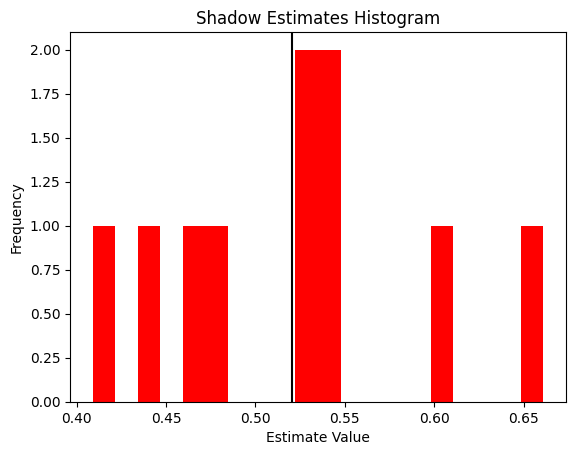

Mean estimate: 0.5206906186646748


In [43]:
shadow_results=get_shadows_from_basis(bitstring_counts,(12,2),target_state,verbose=False)

## testing rubbish (that ill keep not delete in case)

In [110]:
results=qnx.client.jobs.results(job_refs[0])[0]
download_results=results.download_result()

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

In [ ]:
with open(f'{data_dir}/{file_name}.pkl', 'wb') as file:
    pickle.dump([job_ref], file)

# Actual Workflow

In [90]:
qnx.quotas.get_all().df()

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\client\__init__.py:131: DeprecationWarning: Your version of qnexus is using a deprecated API endpoint (/api/quotas/v1beta) that will be deleted on Sun, 30 Nov 2025 00:00:00 GMT. After this date your current qnexus version may stop functioning. Please update to a later qnexus version to resolve the issue.
  warnings.warn(


,name,description,usage,quota
0,jupyterhub,"Total Jupyterhub notebook server running time,...",0.000000,1.0
1,simulation,"Total CPU running time, in seconds.",0.000000,No quota set for user
2,database_usage,Total megabytes used to store scientific data.,0.427046,No quota set for user
3,compilation,"Total CPU running time, in seconds.",3.037381,No quota set for user


In [ ]:
#Generate the number of shots that we will take on each basis
import numpy as np
from collections import Counter
num_qubits=13
seed = 42
rng = np.random.default_rng(seed)

shots_taken = []

for _ in range(1000):
    target_qubit = int(rng.integers(0, num_qubits))
    unitary_id = int(rng.integers(0, 3))
    shots_taken.append((target_qubit, unitary_id))

# Count frequencies
freq_counter = Counter(shots_taken)

# Sort by target_qubit, then unitary_id
freq_sorted = dict(sorted(freq_counter.items(), key=lambda x: (x[0][0], x[0][1])))
total_unitary_2 = sum(count for (i, u), count in freq_sorted.items() if u == 2)
print(freq_sorted)
print("\nTotal occurrences of (*, 2):", total_unitary_2)

{(0, 0): 30, (0, 1): 18, (0, 2): 26, (1, 0): 24, (1, 1): 30, (1, 2): 28, (2, 0): 22, (2, 1): 18, (2, 2): 22, (3, 0): 32, (3, 1): 24, (3, 2): 28, (4, 0): 28, (4, 1): 25, (4, 2): 18, (5, 0): 32, (5, 1): 26, (5, 2): 28, (6, 0): 27, (6, 1): 33, (6, 2): 27, (7, 0): 22, (7, 1): 24, (7, 2): 25, (8, 0): 24, (8, 1): 28, (8, 2): 22, (9, 0): 25, (9, 1): 28, (9, 2): 23, (10, 0): 28, (10, 1): 21, (10, 2): 31, (11, 0): 25, (11, 1): 19, (11, 2): 24, (12, 0): 27, (12, 1): 27, (12, 2): 31}

Total occurrences of (*, 2): 333


Make sure everything here is run, esepecially the functions designed to run the compliation and all. Do it one at a time as the name variables must be kept as you go.

The above section gives the number of shots required for each basis state, copied below to be safe.
{(0, 0): 30, (0, 1): 18, (0, 2): 26, (1, 0): 24, (1, 1): 30, (1, 2): 28, (2, 0): 22, (2, 1): 18, (2, 2): 22, (3, 0): 32, (3, 1): 24, (3, 2): 28, (4, 0): 28, (4, 1): 25, (4, 2): 18, (5, 0): 32, (5, 1): 26, (5, 2): 28, (6, 0): 27, (6, 1): 33, (6, 2): 27, (7, 0): 22, (7, 1): 24, (7, 2): 25, (8, 0): 24, (8, 1): 28, (8, 2): 22, (9, 0): 25, (9, 1): 28, (9, 2): 23, (10, 0): 28, (10, 1): 21, (10, 2): 31, (11, 0): 25, (11, 1): 19, (11, 2): 24, (12, 0): 27, (12, 1): 27, (12, 2): 31}
Total occurrences of (*, 2): 333

In [23]:
project = qnx.projects.get_or_create(name="State Preparation and Shadow Overlap")
qnx.context.set_active_project(project)

In [4]:
#Load in Quantinium Upload and Complitation Funciton
def quntinuum_compilation(
    circuits: list[QuantumCircuit],
    backend: QuantinuumConfig,name,
    optimization_level: int = 2
) -> list[CircuitRef]: 
    #circuits = [qiskit_to_tk(circuit) for circuit in circuits]
    uploaded_circuits = [
        qnx.circuits.upload(
            circuit=circuit,
            name=name
        )
        for circuit in circuits
    ]
    compiled_circuits_ref = qnx.compile(
                        programs=uploaded_circuits,
                        backend_config=backend,
                        optimisation_level=optimization_level,
                        name=name
                    )
    
    return compiled_circuits_ref

In [5]:
# Load in Accoustic Circuit
from pytket.circuit import Circuit, Unitary1qBox, Unitary2qBox
import numpy as np
def make_unitary(U):
    U = np.array(U)
    V, _, W = np.linalg.svd(U)
    return V @ W
def arch_apply_layer_tket(sorted_gates,qc,num_qubits):
    gate_count=0
    for idx in range(num_qubits-2,-1,-1):
        #qc.apply_gate_raw(sorted_gates[gate_count], (idx, idx+1), tags=['SU4'])
        u2 = sorted_gates[gate_count]
        u2=make_unitary(u2)
        u2box = Unitary2qBox(u2)
        qc.add_unitary2qbox(u2box, idx, idx+1)
        gate_count=gate_count+1
def arch_apply_tau_layer_tket(sorted_gates,qc,num_qubits):
    gate_count=0
    for idx in range(num_qubits):
        u1 = sorted_gates[gate_count]
        u1=make_unitary(u1)
        u1box = Unitary1qBox(u1)
        qc.add_unitary1qbox(u1box, idx)
        gate_count=gate_count+1
def arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,num_qubits,taued=True,basis_choice=False):
    '''Basis choice is (target_qubit,pauli), where tar starts from 0 and then the pauli is 0=X, 1=Y and 2=Z'''
    qc=Circuit(num_qubits)
    
    sorted_k_gates=[U.conj().T for U in sorted_k_gates]
    sorted_z_gates=[U.conj().T for U in sorted_z_gates]
    sorted_b_gates=[U.conj().T for U in sorted_b_gates]

    arch_apply_layer_tket(sorted_k_gates,qc,num_qubits)
    arch_apply_layer_tket(sorted_z_gates,qc,num_qubits)
    arch_apply_layer_tket(sorted_b_gates,qc,num_qubits)
    if taued:
      arch_apply_tau_layer_tket(tau_layer,qc,num_qubits)
    if basis_choice:
      target_qubit=basis_choice[0]
      unitary_id =basis_choice[1]
      print("Target Qubit is: ", target_qubit)
  
      #Apply pauli gate to qubit (nothing if Z)
      paulis = ['X', 'Y', 'Z']

      #if only comp basis selected then make sure we measure in Z.
      
      P = paulis[unitary_id]
      print("Will measure ",P, " at target qubit")
      if P == 'X':
        qc.H(target_qubit)            # H maps X->Z
      elif P == 'Y':
        qc.Sdg(target_qubit)          # Sdg (S dagger) then H maps Y->Z
        qc.H(target_qubit)
      # P == 'Z' → do nothing
    qc.measure_all()
    return qc
tau_layer=[np.array([[ 0.70756656+0.j        ,  0.70510361-0.04667407j],
        [-0.66757702+0.23171208j,  0.65166181-0.27565797j]]),
 np.array([[ 0.70646004+0.j        , -0.6039059 -0.36906893j],
        [ 0.2372931 +0.66678797j, -0.1449662 +0.69142649j]]),
 np.array([[ 0.76389571+0.j        , -0.63134767-0.13365428j],
        [ 0.64295216+0.05546051j,  0.73097187+0.22184855j]]),
 np.array([[ 0.74559257+0.j        ,  0.03857026-0.66528495j],
        [ 0.11278586+0.65678845j, -0.74090827+0.08344586j]]),
 np.array([[ 0.99917109+0.j        ,  0.01011472+0.03943119j],
        [-0.02436882+0.03260809j,  0.92388205+0.38050603j]]),
 np.array([[ 0.99961458+0.j        ,  0.02682634-0.00714454j],
        [-0.02579163+0.01027075j,  0.80223109-0.59636783j]]),
 np.array([[ 0.99981649+0.j        , -0.00387036+0.01876176j],
        [ 0.00883066+0.01700009j,  0.96207236-0.27212092j]]),
 np.array([[ 0.71461712+0.j        , -0.00869148+0.69946181j],
        [ 0.53887603+0.44602129j,  0.46245501-0.54480546j]]),
 np.array([[ 0.9999664 +0.j        ,  0.00811918-0.00113379j],
        [-0.00811019-0.00119639j,  0.99993664+0.00771393j]]),
 np.array([[ 0.99980298+0.j        , -0.01792838+0.0085195j ],
        [ 0.01134536-0.01628777j,  0.16402578-0.98625632j]]),
 np.array([[ 0.99991509+0.j        , -0.00534618-0.01188413j],
        [ 0.00643287+0.01133281j, -0.59053236+0.80690874j]]),
 np.array([[ 0.99999797+0.j        , -0.00169669-0.00108734j],
        [-0.00146146+0.00138752j, -0.9820911 +0.18839587j]]),
 np.array([[ 0.99994849+0.00000000e+00j, -0.01013957+4.48082824e-04j],
        [-0.00252882+9.82937960e-03j, -0.20614825+9.78468134e-01j]])]
sorted_k_gates=[np.array([[ 0.58202826+0.03064421j,  0.2211523 +0.66589927j,
         0.31456239+0.01467208j, -0.08062462-0.24961722j],
       [ 0.21442015-0.15826631j, -0.38193016-0.07747488j,
        -0.01207216-0.77562583j,  0.34533318-0.2368683j ],
       [ 0.08815743+0.32977098j,  0.09571298+0.29393884j,
        -0.29172782-0.37350674j, -0.06823435+0.74742894j],
       [-0.60646143+0.32398103j,  0.4414201 +0.25570314j,
         0.12592156-0.24212686j,  0.34689456-0.26867738j]]), np.array([[ 0.44552844+0.15794513j,  0.66797301+0.5592994j ,
        -0.11283244-0.02905615j,  0.03183672+0.05445167j],
       [-0.09733357+0.855663j  ,  0.23246245-0.40912809j,
         0.07423724-0.03686386j, -0.09281805-0.14648249j],
       [ 0.12614157-0.04675024j, -0.08832296+0.07383197j,
        -0.14336369+0.10399472j,  0.22148849-0.94245711j],
       [ 0.04027883-0.12330888j,  0.0781551 +0.01453717j,
         0.6354779 -0.73780368j,  0.019408  -0.16819601j]]), np.array([[ 0.64828808+0.5747724j , -0.12442896-0.41081484j,
        -0.06888901-0.10599752j,  0.00205952-0.22163585j],
       [ 0.0997587 +0.07837263j,  0.07700988+0.20810604j,
         0.64933299+0.57312201j, -0.12503056-0.41101397j],
       [-0.07949422-0.06547905j, -0.4600854 -0.42522884j,
         0.45789497+0.12939045j,  0.41654416+0.4438201j ],
       [ 0.45274918-0.13295315j,  0.56972027+0.22232999j,
         0.08476216-0.01795405j,  0.58351822+0.2352219j ]]), np.array([[ 0.52407372+0.461487j  , -0.40031671+0.38672605j,
        -0.20296601+0.21451742j,  0.2229162 +0.25624484j],
       [ 0.2432249 +0.16987124j,  0.21224962-0.2653005j ,
         0.35801352-0.5997838j ,  0.45552873+0.31801012j],
       [-0.03384098+0.35613347j, -0.14360225-0.30104796j,
         0.42340664+0.3572732j ,  0.32604748-0.58953199j],
       [-0.15906532-0.52065713j, -0.67983397-0.0364627j ,
         0.33589182+0.07163898j,  0.20981771+0.27952047j]]), np.array([[ 0.3195201 +0.28623376j, -0.39021268+0.67612951j,
         0.29130818+0.25674555j,  0.11327077-0.20724645j],
       [ 0.35619821-0.1541608j , -0.1448835 -0.18206131j,
        -0.13391825+0.40844378j, -0.77596986-0.09126936j],
       [-0.59401613+0.12715196j,  0.00234348-0.11431195j,
         0.6021543 +0.03509899j, -0.31027391-0.39725667j],
       [-0.45769029+0.29467142j,  0.35182842+0.44675435j,
        -0.43332058+0.33596486j, -0.20974368+0.18890249j]]), np.array([[ 0.50748849-0.38992088j,  0.26423653-0.37016937j,
        -0.27974655+0.22028492j,  0.29301619-0.41343532j],
       [ 0.21295812+0.2976991j , -0.40519303-0.29927838j,
         0.09443477-0.62699161j, -0.06438628-0.45397483j],
       [-0.52754712+0.32413781j, -0.00941132-0.37106295j,
        -0.67810661+0.08969459j,  0.08652006-0.05910172j],
       [ 0.253007  +0.09517038j,  0.26500474-0.57567434j,
         0.04397303-0.03704988j, -0.55460073+0.46304785j]]), np.array([[ 0.8465369 +0.1490747j ,  0.11381032+0.4065244j ,
         0.1188296 +0.03126009j, -0.06330886-0.25264888j],
       [ 0.12141814-0.0432531j , -0.19565552-0.17316475j,
         0.8616023 -0.00372001j,  0.18176981+0.37377409j],
       [-0.010625  +0.32042399j,  0.72045441+0.10184213j,
        -0.07680818-0.17377331j,  0.23720832+0.52480926j],
       [-0.02840682-0.37542968j, -0.14094034+0.45191532j,
        -0.15965058+0.42537632j,  0.63258819+0.16599045j]]), np.array([[ 0.6879807 -0.15085243j, -0.37283286-0.26820696j,
         0.33201212-0.07792622j,  0.38242064+0.17446116j],
       [ 0.22139692+0.47721791j, -0.23807596+0.7458153j ,
         0.12477684+0.20328617j,  0.10738893-0.2046923j ],
       [-0.02372256-0.38704301j,  0.04009478-0.0397363j ,
         0.08806785+0.90358429j,  0.06914538-0.13208626j],
       [-0.18861644+0.20305504j,  0.39338576-0.13491159j,
         0.01759658-0.04765265j,  0.81504929-0.28870959j]]), np.array([[ 0.20146529-0.40427636j,  0.57271501+0.66513107j,
        -0.09169325+0.12521773j, -0.0271526 -0.02731558j],
       [ 0.22493316+0.1184158j , -0.00507774+0.05414656j,
         0.80426111+0.39957849j, -0.09271839+0.342534j  ],
       [-0.82288616+0.19381148j, -0.06260719+0.46273796j,
         0.1224518 -0.08029448j,  0.02590225+0.21245428j],
       [-0.11617348-0.05616341j, -0.08175297+0.04371399j,
         0.21382396+0.3197681j ,  0.68024952-0.60335992j]]), np.array([[ 0.87066998+0.1150999j , -0.27420068-0.37600907j,
         0.09424396+0.02108211j, -0.03612314-0.03854494j],
       [ 0.372813  +0.19573726j,  0.21562763+0.7651584j ,
        -0.173029  -0.11540316j, -0.1221138 -0.36409618j],
       [ 0.19144084-0.0476141j ,  0.34638822+0.15401582j,
         0.38760483-0.29324391j,  0.65628003+0.38787196j],
       [-0.08856471-0.06799111j,  0.0876067 -0.00937547j,
         0.82228486+0.18717588j, -0.12840687-0.50209077j]]), np.array([[ 0.09265075-0.09016941j,  0.50203184+0.85223331j,
        -0.04579392-0.04069792j, -0.03215189-0.01267246j],
       [ 0.07778813+0.54951414j,  0.10262224+0.03513331j,
         0.20297511+0.08275016j,  0.7909637 +0.08091651j],
       [-0.41503278-0.58944628j, -0.04123336+0.03158399j,
         0.49248551-0.30923895j,  0.36718933-0.06785595j],
       [-0.1517764 +0.36405129j,  0.07315172+0.04298646j,
         0.75285865+0.20792608j, -0.44757153-0.16395699j]]), np.array([[ 0.94288573-0.27707098j, -0.07145321-0.02650028j,
        -0.15852259-0.05485833j,  0.00544126+0.01489628j],
       [-0.03329412-0.07890731j,  0.30523914-0.93573229j,
        -0.01239679-0.05010488j, -0.0441048 +0.138888j  ],
       [-0.04695647-0.08672901j,  0.0741091 -0.02479653j,
         0.04555413-0.6330607j ,  0.64230814-0.41081063j],
       [ 0.12257869+0.04594511j,  0.03183247-0.13529964j,
         0.38746771+0.6451548j ,  0.2426427 -0.58164661j]])]
sorted_z_gates=[np.array([[ 7.03134478e-01+0.64204651j,  1.32967243e-01-0.17099836j,
         1.35690170e-01+0.02980882j, -8.90878621e-02-0.13863772j],
       [ 1.54638248e-01-0.18665489j,  7.95244426e-01+0.5456483j ,
         9.06082570e-04+0.05827191j,  8.24846307e-02-0.03001751j],
       [-8.03907783e-02-0.11601588j, -8.88605746e-02+0.06222374j,
         9.07885923e-01+0.34394578j,  2.24949069e-02-0.15889641j],
       [ 1.18723479e-01-0.02464785j, -5.83552520e-02-0.08809188j,
         3.86060998e-02-0.18236555j,  9.65796737e-01-0.08136794j]]), np.array([[ 0.64571428+0.49596465j, -0.45380149-0.33907793j,
        -0.06694162-0.08015101j,  0.04724597+0.0549996j ],
       [ 0.4955781 +0.27439294j,  0.71747993+0.38491003j,
        -0.05431832-0.0482405j , -0.07904742-0.06820239j],
       [ 0.10117342+0.02561433j, -0.07058747-0.01696308j,
         0.72663724+0.36736893j, -0.50884918-0.24889436j],
       [ 0.07238447+0.00716485j,  0.10395368+0.00897127j,
         0.53788306+0.17758718j,  0.77647313+0.24506405j]]), np.array([[ 0.64636693+0.63721595j,  0.03666502+0.18464219j,
         0.15823873-0.3293842j ,  0.07512451-0.03938812j],
       [-0.19001252-0.03081503j,  0.64599194+0.63867178j,
         0.00114168+0.07497111j,  0.16872555-0.32194436j],
       [-0.08004571+0.3581736j , -0.06430601+0.04382427j,
        -0.90366332+0.09417753j, -0.15828807-0.0933628j ],
       [-0.0257416 -0.061262j  , -0.07977603+0.35628033j,
         0.14020559-0.12534022j, -0.90711751+0.063675j  ]]), np.array([[ 0.65471375+0.65571412j, -0.05704243-0.06013354j,
         0.05952997-0.33061483j,  0.14617432+0.01738101j],
       [ 0.00359358+0.04573564j, -0.15514195+0.95233419j,
         0.15024435+0.05351004j,  0.18091655-0.09337244j],
       [ 0.33468649-0.11782398j,  0.03022321-0.10588509j,
         0.75758999+0.51223815j, -0.15635953+0.03462008j],
       [ 0.1146089 -0.01585878j,  0.12341588+0.18645136j,
        -0.15557113+0.03435739j, -0.28460644+0.91117182j]]), np.array([[ 0.48765382+0.80428082j, -0.02004694+0.18623798j,
        -0.03871273+0.0552293j , -0.25148666+0.1115579j ],
       [-0.06720493-0.14190248j, -0.43673553+0.8552704j ,
         0.06123371-0.11849076j,  0.11466872+0.14894048j],
       [-0.15239092+0.10160871j,  0.12887923+0.00218074j,
         0.82542422+0.41149955j,  0.11428394+0.29346247j],
       [-0.19945933-0.13168887j,  0.15957604-0.02467874j,
         0.00596335-0.35632686j, -0.64857446+0.60757489j]]), np.array([[-0.20310121+0.72763244j, -0.46759073+0.24399318j,
         0.03902037+0.11005302j, -0.1356478 +0.34509794j],
       [-0.16104273+0.00789092j,  0.31571895+0.2222955j ,
         0.28464787-0.72117529j, -0.43495194+0.18603181j],
       [-0.12050757+0.51657895j,  0.68663345-0.21409732j,
         0.10194473+0.32851939j, -0.14218333-0.25057363j],
       [ 0.24528904+0.24851823j, -0.21644769+0.09262687j,
        -0.41749531-0.30434763j, -0.26301599-0.69752091j]]), np.array([[ 0.59960737+0.58699756j,  0.52863945-0.12070687j,
         0.01438597-0.00941078j, -0.01492176+0.03683578j],
       [-0.53496912-0.08351615j,  0.55447857-0.62927262j,
         0.04676391-0.00283672j, -0.03238546-0.01260359j],
       [-0.00557339+0.03069273j, -0.01801741-0.02413408j,
         0.31915752+0.77555265j,  0.53806246+0.07256144j],
       [-0.02189967+0.03585054j,  0.03675377-0.01678535j,
        -0.45849335-0.28974123j,  0.74068471-0.39220222j]]), np.array([[ 0.77662637+6.11188819e-01j,  0.0218406 -2.16353155e-02j,
        -0.14257091+3.71626137e-02j,  0.00501998+2.49375782e-02j],
       [-0.0162492 -2.11654570e-02j,  0.86502625-4.82211327e-01j,
         0.04885749-8.62237496e-04j,  0.02443493+1.24518837e-01j],
       [ 0.02361563+1.47090131e-01j, -0.04319908+1.77398753e-03j,
         0.87237333+4.63234941e-01j,  0.01623505-7.21592420e-03j],
       [ 0.00559072+1.90586560e-02j,  0.12775119+8.18806839e-03j,
        -0.01529697+6.98846046e-03j,  0.37240375-9.18831164e-01j]]), np.array([[-0.09681078+0.83362289j, -0.0966908 +0.06137852j,
        -0.11812443+0.40895191j, -0.31612943-0.03809521j],
       [-0.10657436-0.17385175j,  0.78609145-0.12908755j,
        -0.20798033+0.30186568j, -0.26471895+0.34548415j],
       [ 0.30293512-0.31677137j, -0.40939011-0.12625996j,
        -0.62107907+0.48588119j,  0.02822391+0.04156967j],
       [ 0.19994696-0.14840973j,  0.13676433-0.38734208j,
         0.20579641+0.14231776j, -0.37154238-0.75406045j]]), np.array([[ 0.41154583+0.30545641j, -0.57722946+0.14494536j,
        -0.61270542+0.05550446j, -0.02528286+0.06320997j],
       [-0.24068861+0.49135409j,  0.32555458+0.31687055j,
        -0.18830948+0.02954589j,  0.66026907-0.14818492j],
       [-0.12810287+0.12477796j, -0.64350872-0.05277341j,
         0.55380291+0.2822562j ,  0.28309016-0.29090436j],
       [ 0.52090793-0.36693543j, -0.02700549-0.14760238j,
         0.09897426-0.43475944j,  0.60774319+0.05774166j]]), np.array([[ 0.06857136+0.26545743j,  0.4617385 +0.74884729j,
         0.29742017+0.15911151j, -0.19018004+0.03019813j],
       [-0.42767494-0.824323j  ,  0.22178229+0.26306455j,
        -0.08670321-0.06482756j,  0.08332348+0.02307675j],
       [-0.00076721-0.09914634j, -0.03850987-0.13550184j,
         0.62820086+0.46576225j,  0.59005693-0.10289649j],
       [-0.17079222-0.15302122j, -0.2067164 -0.21227227j,
         0.4909668 +0.14793756j, -0.65673252+0.40668393j]]), np.array([[ 0.93679913+0.02594862j,  0.13991495-0.28770167j,
         0.10117862+0.0920605j , -0.01879686+0.01788962j],
       [ 0.30961345-0.04226362j, -0.28174109+0.8950109j ,
         0.04800702+0.06610847j,  0.05148477-0.11227224j],
       [-0.10830616+0.09081878j, -0.06490451+0.01058552j,
         0.90338618+0.10824496j, -0.31561365+0.2196851j ],
       [-0.04060171+0.04960425j,  0.02598153-0.11058619j,
         0.35881805-0.1343086j ,  0.44351932-0.79967993j]])]
sorted_b_gates=[np.array([[ 0.79470034+0.46651016j, -0.06183633-0.02563694j,
         0.0405321 +0.03077763j,  0.35519194-0.13261686j],
       [ 0.04163815+0.02565811j,  0.9876019 +0.07080013j,
        -0.01868977+0.10151397j,  0.01365924-0.07997988j],
       [-0.01215399+0.00795198j, -0.05136915+0.09569919j,
         0.77172121+0.6149146j , -0.11660769+0.02685125j],
       [-0.38320895-0.03697997j, -0.03971645-0.04212265j,
         0.11435339+0.00228377j,  0.63863364-0.65383242j]]), np.array([[ 0.73014302+0.67053803j,  0.06824339+0.09991291j,
        -0.00315423-0.03241934j, -0.02737492-0.02863255j],
       [-0.06832139-0.10241291j,  0.33838657+0.92840835j,
        -0.05289589-0.07098943j,  0.01243432-0.02010401j],
       [ 0.02130573+0.01828214j, -0.02244896+0.0892792j ,
        -0.01508716+0.98722821j, -0.01262397+0.12542161j],
       [-0.01502122+0.03316467j,  0.01569681+0.01384212j,
         0.03143621-0.12355636j, -0.33237175+0.93354758j]]), np.array([[ 0.73591107+0.55126318j,  0.16441159+0.31931058j,
        -0.0224752 -0.14543077j,  0.01021258-0.06159422j],
       [ 0.24565266-0.26200369j, -0.84558714+0.34376809j,
        -0.05742093+0.0471137j ,  0.17163718+0.05327793j],
       [ 0.019668  +0.14221932j,  0.01602544+0.0780073j ,
        -0.45545565+0.78281084j, -0.32364484+0.21924013j],
       [ 0.06944699-0.01079778j, -0.16376764-0.06821787j,
         0.33146163+0.20670853j, -0.49926612-0.74948323j]]), np.array([[ 7.17991637e-01+0.67342796j, -5.34383911e-03-0.05433924j,
         2.69559704e-02-0.16432942j, -1.35804577e-02+0.00928795j],
       [ 5.30820938e-02-0.01328688j,  8.67896360e-01+0.46394857j,
        -8.94403912e-03-0.01354531j, -1.84544123e-02-0.16706091j],
       [ 9.26703685e-02-0.13926986j, -3.23254858e-03-0.00330969j,
         9.84563062e-01-0.00185388j, -3.85591669e-02-0.03376444j],
       [ 6.17368744e-04-0.00206549j,  5.46872610e-02-0.15973173j,
         2.73890182e-02-0.04344799j,  9.48825067e-01-0.26188459j]]), np.array([[ 0.56507372+0.30746262j, -0.11876625-0.12696098j,
        -0.38800081+0.20779634j,  0.40301607+0.44697653j],
       [ 0.17050499-0.21191571j,  0.19827398+0.80737897j,
        -0.20270783-0.40095894j,  0.05497155+0.17310693j],
       [-0.53087812+0.34505451j, -0.03796253+0.20040768j,
         0.24217185-0.02061659j,  0.70283543+0.06671974j],
       [-0.07711519-0.32455703j, -0.25601526-0.41406994j,
        -0.3206664 -0.66522051j,  0.30681165-0.11063275j]]), np.array([[ 0.22004077+0.01409825j, -0.2863934 +0.24745917j,
        -0.0682152 -0.17868422j, -0.75287943+0.45245693j],
       [-0.12101337-0.00697645j, -0.10178502+0.91398206j,
         0.1196823 +0.08706739j,  0.07034555-0.33575381j],
       [ 0.24391325-0.13520864j, -0.04595563+0.00539721j,
         0.66366276-0.65539256j,  0.21681634+0.05556001j],
       [ 0.57950374-0.72325014j,  0.09281615-0.01623243j,
        -0.04747952+0.26319591j, -0.08247475-0.23211602j]]), np.array([[ 0.5544758 +0.56143093j,  0.47486683+0.36179487j,
         0.08106661+0.04452605j,  0.08334508+0.07387222j],
       [-0.58944759+0.13023794j,  0.7443091 -0.27420421j,
         0.03809042-0.06380702j, -0.0243691 +0.01701644j],
       [-0.04494578-0.08505727j, -0.01611423-0.10867334j,
         0.30125342+0.72871738j,  0.29054326+0.52199382j],
       [-0.05799434-0.01798102j,  0.01990613+0.04422852j,
        -0.59452457-0.10335045j,  0.79213566+0.04838633j]]), np.array([[ 0.36087993-0.01080293j,  0.91557851-0.03273781j,
         0.07859434+0.05716312j, -0.12966675+0.06352207j],
       [ 0.87235786+0.28739604j, -0.32927208-0.09928422j,
        -0.08720405-0.17208417j, -0.01103217+0.02790335j],
       [-0.02057557+0.08272297j, -0.09191175+0.04741377j,
        -0.08672642+0.38223717j, -0.17125989+0.89391333j],
       [-0.07868024-0.1121928j ,  0.01114537+0.17761397j,
         0.35322866-0.82154768j, -0.14878834+0.35735446j]]), np.array([[ 0.14617241+0.49153034j, -0.43146663-0.40556759j,
        -0.21456778-0.13877135j,  0.47072835+0.31543785j],
       [ 0.07798231-0.15998614j,  0.45634742+0.42076338j,
        -0.19969481-0.45344271j,  0.49354915+0.30651154j],
       [ 0.74266325-0.26688234j,  0.24376679-0.31700554j,
        -0.09025163+0.21777477j, -0.20886591+0.34367742j],
       [-0.25358341+0.13518623j,  0.05692467+0.31764998j,
        -0.26052666+0.75217652j,  0.08870556+0.41444647j]]), np.array([[ 0.51030462+5.61704849e-01j,  0.16617521-1.72770756e-01j,
        -0.11466276+3.50835031e-01j, -0.46919987+1.01151586e-01j],
       [ 0.06206008-4.92001405e-04j,  0.11666512+8.83591936e-01j,
         0.35285731+2.74771730e-02j, -0.26809279+6.83068673e-02j],
       [-0.17214592-1.90664016e-01j,  0.32007603+9.58411087e-02j,
        -0.13546116+8.38196024e-01j,  0.31779335-2.15387760e-02j],
       [-0.55769994-2.07867653e-01j, -0.0759138 -1.75480827e-01j,
        -0.00643185+1.32439756e-01j, -0.61850013+4.57254109e-01j]]), np.array([[ 0.36154847+0.51179882j, -0.50070492-0.09801636j,
         0.22954133+0.47852417j,  0.24568187+0.07069554j],
       [-0.26625981+0.35218558j,  0.08618814+0.72588701j,
        -0.25017231+0.26089812j, -0.04406011-0.37166568j],
       [ 0.19863699-0.47962333j, -0.04338617-0.2596613j ,
        -0.30682601+0.53710677j, -0.09528713-0.5191271j ],
       [ 0.36943096+0.08025755j, -0.34575688+0.12842452j,
        -0.41491508-0.18135872j, -0.68531738+0.21525194j]]), np.array([[ 8.76599706e-01+0.24382701j, -3.78902308e-01+0.16072861j,
        -1.28022078e-02+0.03250201j,  3.18294542e-02+0.02207508j],
       [-4.11956822e-01-0.0070284j , -7.18755732e-01+0.55739191j,
        -4.59355870e-02-0.01661756j,  2.29264857e-02+0.00589798j],
       [-2.86962958e-02-0.02468589j, -2.02857661e-02-0.04027613j,
        -3.01108954e-01+0.94357038j, -7.34377502e-02-0.10074071j],
       [ 7.03164803e-04-0.03049853j,  2.35426873e-02+0.02675575j,
        -1.19636329e-01+0.03299989j, -3.62256667e-01+0.92258738j]])]

In [6]:
#Processing of measurement data
def get_shadows_from_basis(results, basis_choice,target_state,title,verbose:bool=False):
    """
    results: dict mapping bitstring -> count
    basis_choice: structure giving Pauli choice per qubit
    """

    estimates = []
    paulis = ['X', 'Y', 'Z']

      #if only comp basis selected then make sure we measure in Z.
      
    P = paulis[basis_choice[1]]
    target_qubit=basis_choice[0]
    print(target_qubit,P)
    for measurement, count in results.items():
        conditional_target_qubit_state=build_conditional_postmeasurement_single_qubit(target_state,measurement,target_qubit,verbose=verbose)
        single_estimate=compute_local_overlap(conditional_target_qubit_state, int(measurement[target_qubit]),P,verbose=verbose)
        estimates.extend([single_estimate] * count)
        
    # ---- Histogram Plot ----
    mean= np.mean(estimates)

    # ---- plotting ----
    plt.figure(figsize=(8,5))

    # histogram (grey bars with black edges)
    plt.hist(
        estimates,
        bins=50,
        color='grey',
        edgecolor='black',
        alpha=0.8
    )

    # mean line (black dashed)
    plt.axvline(
        mean,
        color='black',
        linestyle='--',
        linewidth=2,
        label=f"Mean = {mean:.3f}"
    )
    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.title(
        title
    )
    plt.legend()
    plt.tight_layout()
    plt.show()

    return estimates

## Basis Trials (Emulator and Hardware) DO NOT RUN ALL!!

I'd recomend for this and for all similar sections to gothrough each one and check when running. Best way for this is to...
1. Check cells are correct (basis choice and shots and backend)
2. Runthe cells
3. Copy in the measurement analysis step and copy and paste the job reference name manually so it never gets lost.

### (12,1): 27 shots

In [ ]:
#Circuit Upload.
basis_choice=(12,1)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=27

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  12
Will measure  Y  at target qubit
Acoustic_Circ_(12, 1)-2026_02_25-18-41-59


UnboundLocalError: No Project set.

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

12 Y


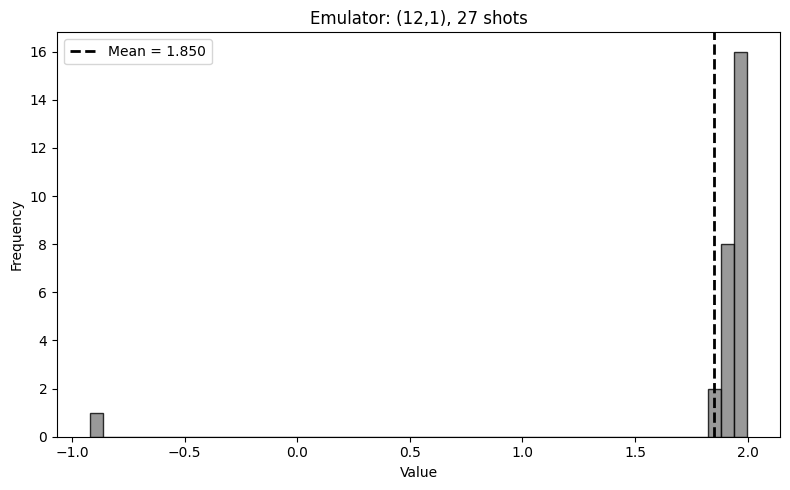

NameError: name 'shadow_results' is not defined

In [43]:
with open('Acoustic_Circ_(12, 1)-2026_02_25-08-37-42_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_12_1=get_shadows_from_basis(bitstring_counts,(12,1),target_state,"Emulator: (12,1), 27 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

12 Y


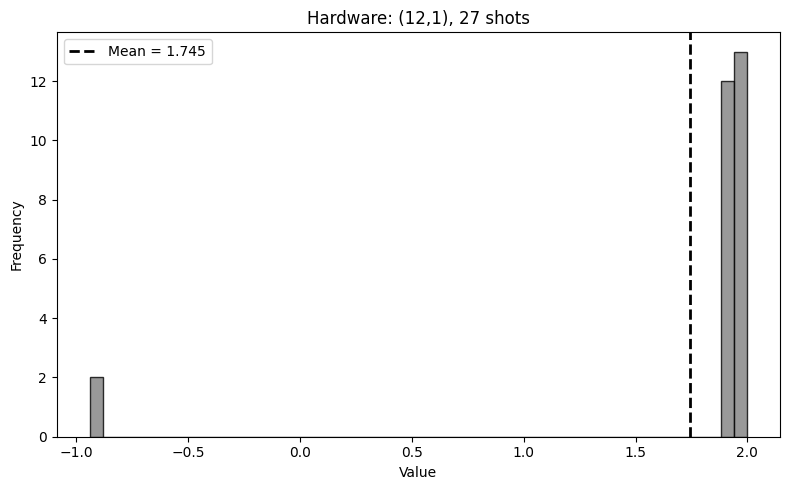

NameError: name 'shadow_results' is not defined

In [19]:
with open('Acoustic_Circ_(12, 1)-2026_02_25-14-12-52_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_12_1_h=get_shadows_from_basis(bitstring_counts,(12,1),target_state,"Hardware: (12,1), 27 shots",verbose=False)
print(shadow_results)

### (12,0): 27 shots

In [ ]:
#Circuit Upload.
basis_choice=(12,0)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=27

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  12
Will measure  X  at target qubit
Acoustic_Circ_(12, 0)-2026_02_25-14-11-45


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

12 X


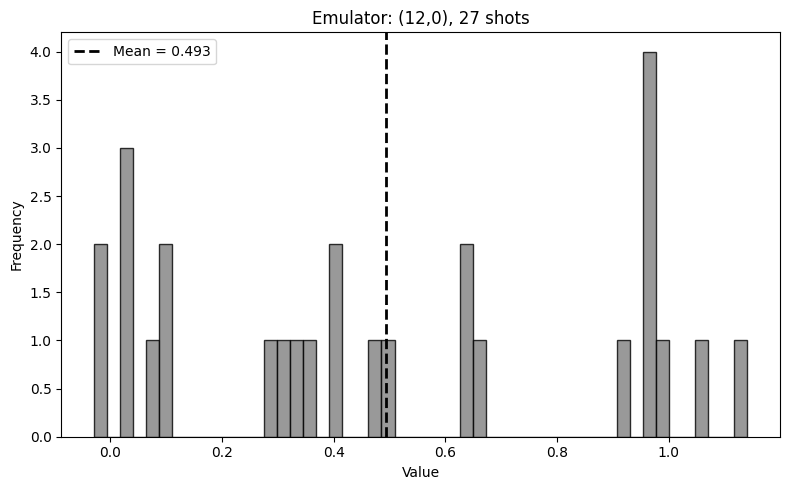

NameError: name 'shadow_results' is not defined

In [44]:
with open('Acoustic_Circ_(12, 0)-2026_02_25-08-37-27_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_12_0=get_shadows_from_basis(bitstring_counts,(12,0),target_state,"Emulator: (12,0), 27 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

12 X


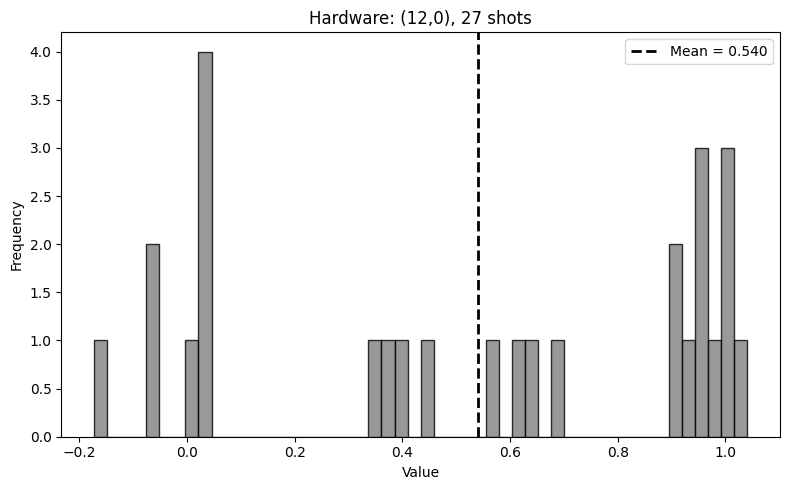

NameError: name 'shadow_results' is not defined

In [80]:
with open('Acoustic_Circ_(12, 0)-2026_02_25-14-11-45_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_12_0_h=get_shadows_from_basis(bitstring_counts,(12,0),target_state,"Hardware: (12,0), 27 shots",verbose=False)
print(shadow_results)

### (11,1): 19 shots

In [ ]:
#Circuit Upload.
basis_choice=(11,1)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=19

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  11
Will measure  Y  at target qubit
Acoustic_Circ_(11, 1)-2026_02_25-14-10-40


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

11 Y


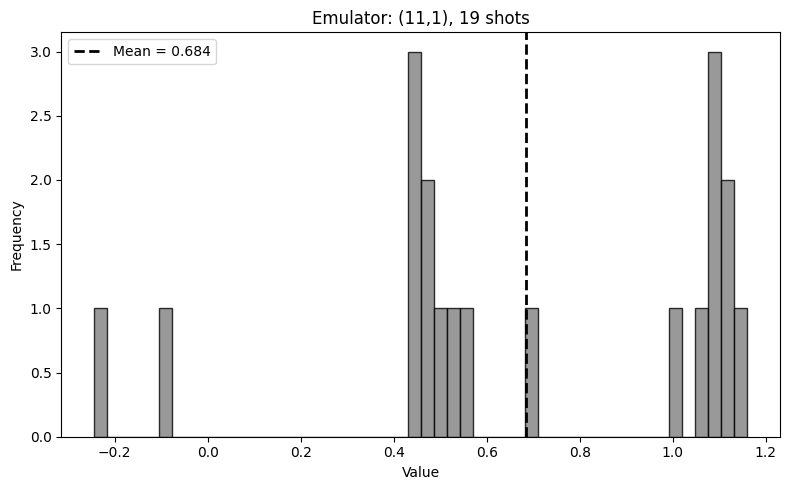

NameError: name 'shadow_results' is not defined

In [45]:
with open('Acoustic_Circ_(11, 1)-2026_02_25-08-37-08_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_11_1=get_shadows_from_basis(bitstring_counts,(11,1),target_state,"Emulator: (11,1), 19 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

11 Y


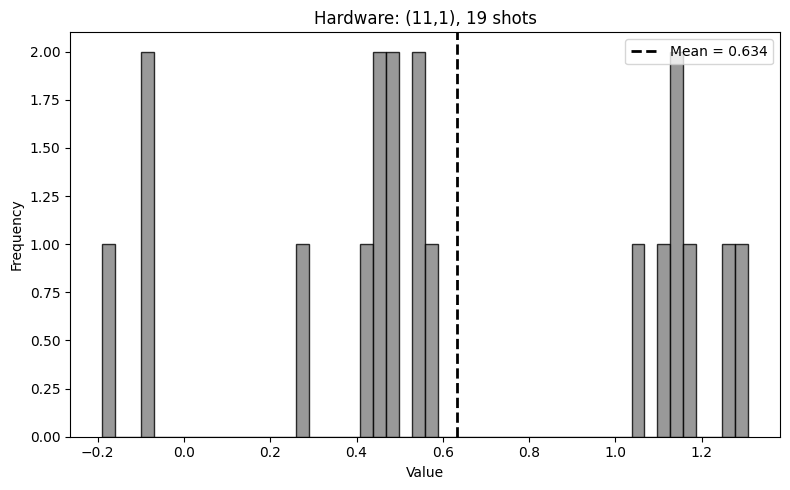

NameError: name 'shadow_results' is not defined

In [46]:
with open('Acoustic_Circ_(11, 1)-2026_02_25-14-10-40_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_11_1_h=get_shadows_from_basis(bitstring_counts,(11,1),target_state,"Hardware: (11,1), 19 shots",verbose=False)
print(shadow_results)

### (11,0) 25 shots

In [ ]:
#Circuit Upload.
basis_choice=(11,0)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=25

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  11
Will measure  X  at target qubit
Acoustic_Circ_(11, 0)-2026_02_25-14-09-14


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

11 X


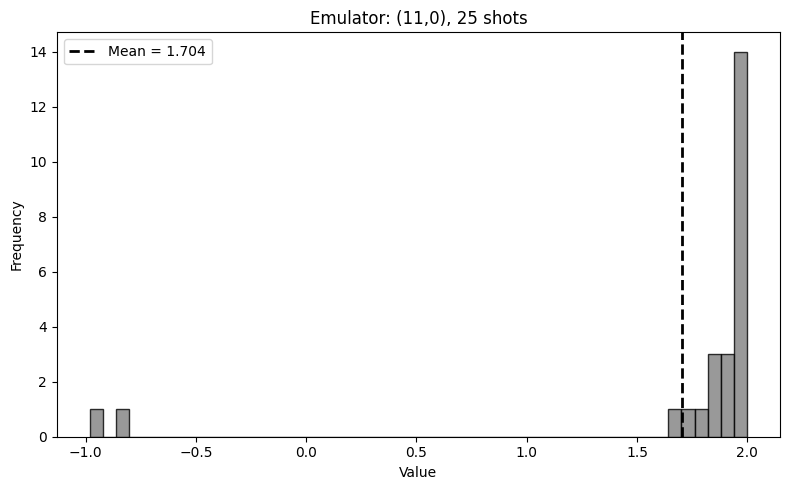

NameError: name 'shadow_results' is not defined

In [47]:
with open('Acoustic_Circ_(11, 0)-2026_02_25-08-36-53_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_11_0=get_shadows_from_basis(bitstring_counts,(11,0),target_state,"Emulator: (11,0), 25 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

11 X


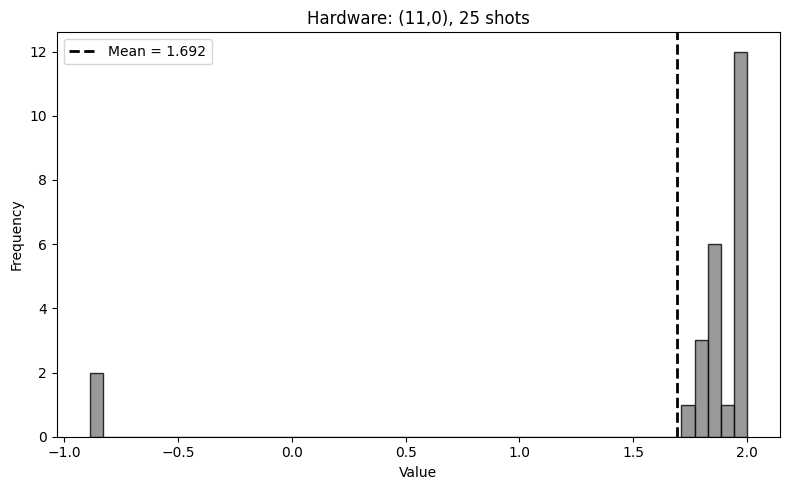

NameError: name 'shadow_results' is not defined

In [48]:
with open('Acoustic_Circ_(11, 0)-2026_02_25-14-09-14_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_11_0_h=get_shadows_from_basis(bitstring_counts,(11,0),target_state,"Hardware: (11,0), 25 shots",verbose=False)
print(shadow_results)

### (10,1): 21 shots

In [ ]:
#Circuit Upload.
basis_choice=(10,1)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=21

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  10
Will measure  Y  at target qubit
Acoustic_Circ_(10, 1)-2026_02_25-14-08-10


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

10 Y


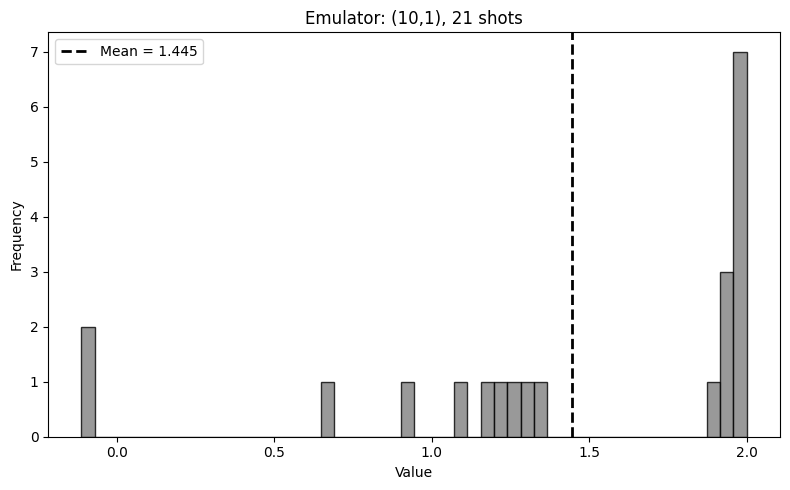

NameError: name 'shadow_results' is not defined

In [49]:
with open('Acoustic_Circ_(10, 1)-2026_02_25-08-36-33_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_10_1=get_shadows_from_basis(bitstring_counts,(10,1),target_state,"Emulator: (10,1), 21 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

10 Y


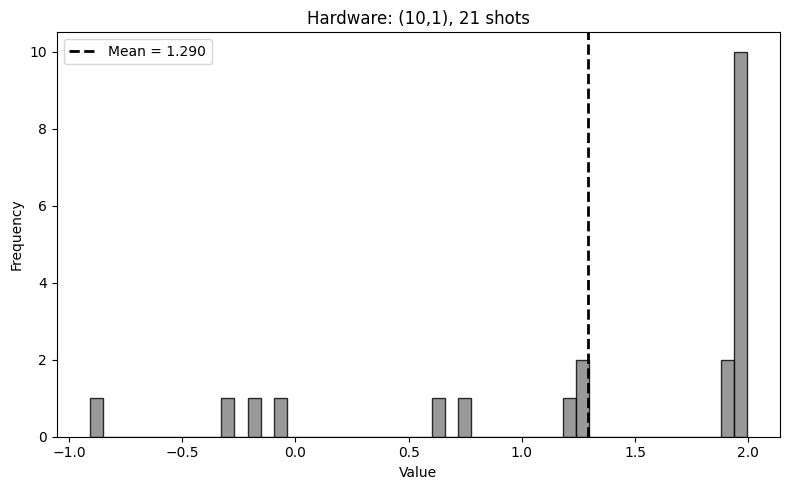

NameError: name 'shadow_results' is not defined

In [50]:
with open('Acoustic_Circ_(10, 1)-2026_02_25-14-08-10_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_10_1_h=get_shadows_from_basis(bitstring_counts,(10,1),target_state,"Hardware: (10,1), 21 shots",verbose=False)
print(shadow_results)

### (10,0): 28 shots

In [ ]:
#Circuit Upload.
basis_choice=(10,0)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=28

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  10
Will measure  X  at target qubit
Acoustic_Circ_(10, 0)-2026_02_25-14-06-51


Exception in callback Task.__step()
handle: <Handle Task.__step()>
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\asyncio\events.py", line 88, in _run
    self._context.run(self._callback, *self._args)
RuntimeError: cannot enter context: <_contextvars.Context object at 0x0000025A880EFA00> is already entered
Exception in callback Task.__step()
handle: <Handle Task.__step()>
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\asyncio\events.py", line 88, in _run
    self._context.run(self._callback, *self._args)
RuntimeError: cannot enter context: <_contextvars.Context object at 0x0000025A880EFA00> is already entered
Task was destroyed but it is pending!
task: <Task pending name='Task-1382' coro=<_async_in_context.<locals>.run_in_context() done, defined at c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-1383' coro=<Kernel.shell_main() running at c:\Users\ar

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

10 X


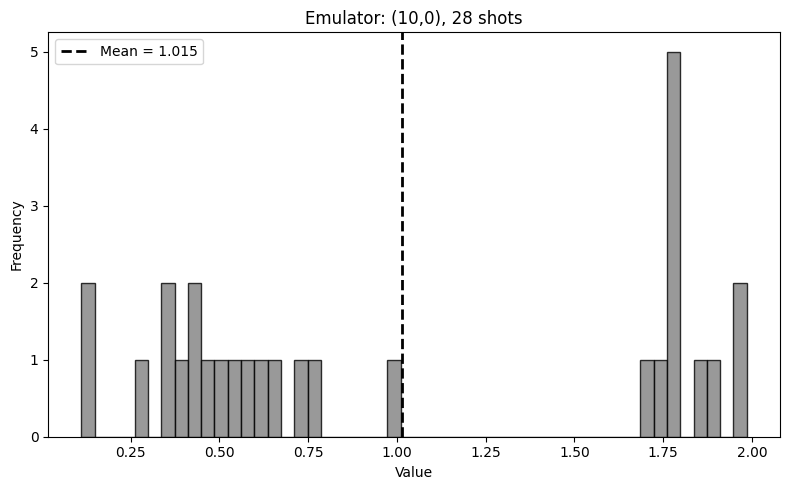

NameError: name 'shadow_results' is not defined

In [51]:
with open('Acoustic_Circ_(10, 0)-2026_02_25-08-36-12_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_10_0=get_shadows_from_basis(bitstring_counts,(10,0),target_state,"Emulator: (10,0), 28 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

10 X


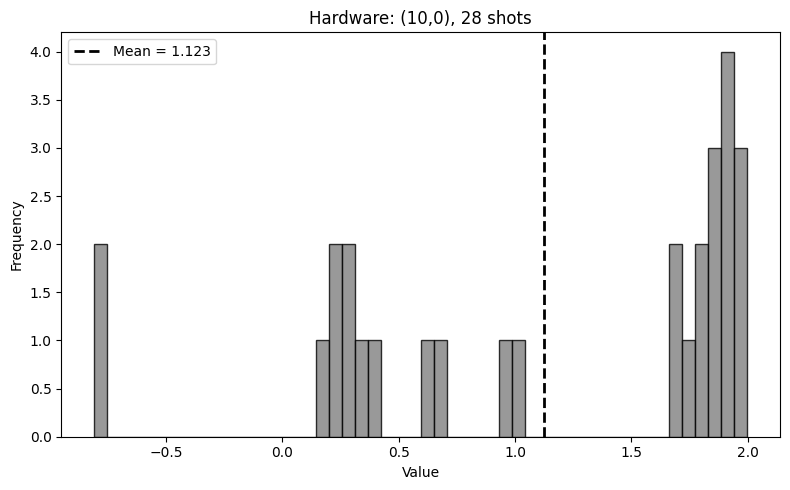

NameError: name 'shadow_results' is not defined

In [52]:
with open('Acoustic_Circ_(10, 0)-2026_02_25-14-06-51_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_10_0_h=get_shadows_from_basis(bitstring_counts,(10,0),target_state,"Hardware: (10,0), 28 shots",verbose=False)
print(shadow_results)

### (9,1): 28 shots

In [ ]:
#Circuit Upload.
basis_choice=(9,1)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=28

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  9
Will measure  Y  at target qubit
Acoustic_Circ_(9, 1)-2026_02_25-12-55-54


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

9 Y


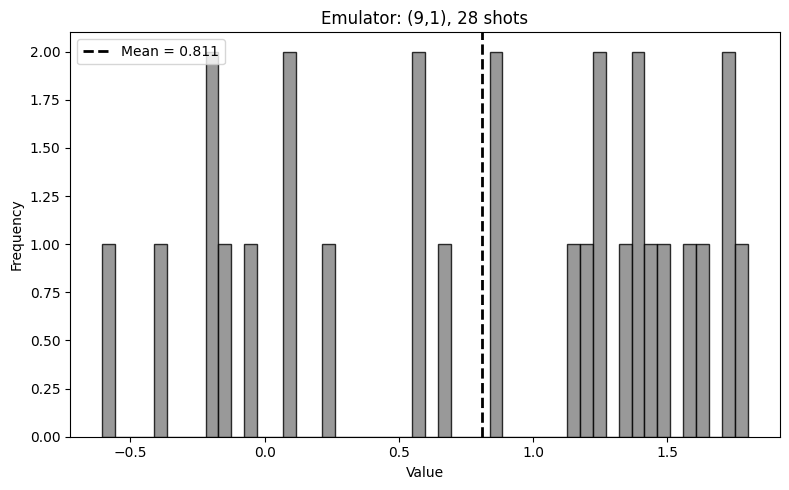

NameError: name 'shadow_results' is not defined

In [53]:
with open('Acoustic_Circ_(9, 1)-2026_02_25-08-35-55_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_9_1=get_shadows_from_basis(bitstring_counts,(9,1),target_state,"Emulator: (9,1), 28 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

9 Y


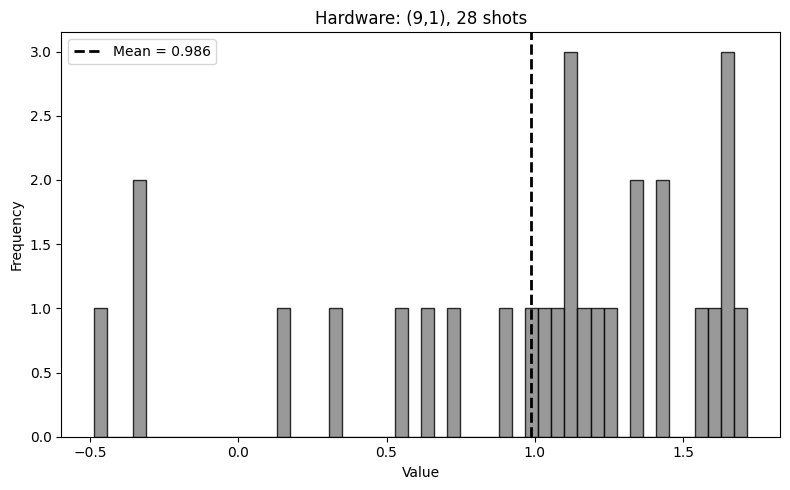

NameError: name 'shadow_results' is not defined

In [54]:
with open('Acoustic_Circ_(9, 1)-2026_02_25-12-55-54_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_9_1_h=get_shadows_from_basis(bitstring_counts,(9,1),target_state,"Hardware: (9,1), 28 shots",verbose=False)
print(shadow_results)

### (9,0): 25 shots

In [ ]:
#Circuit Upload.
basis_choice=(9,0)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=25

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  9
Will measure  X  at target qubit
Acoustic_Circ_(9, 0)-2026_02_25-12-55-20


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

9 X


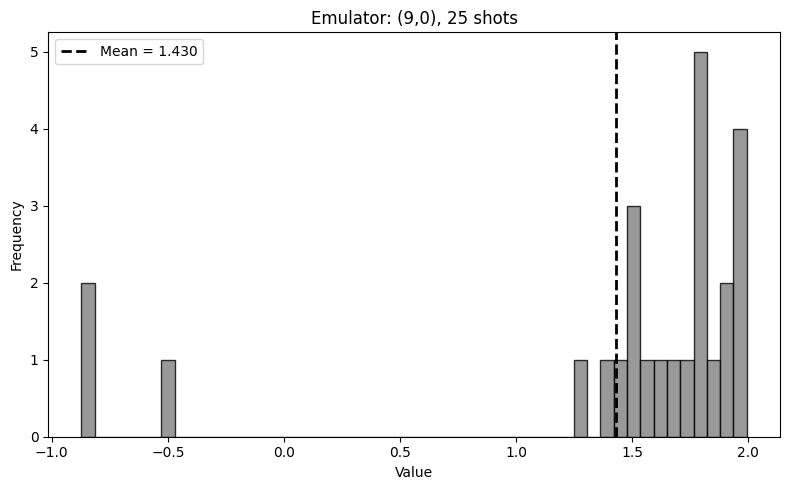

NameError: name 'shadow_results' is not defined

In [55]:
with open('Acoustic_Circ_(9, 0)-2026_02_25-08-35-45_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_9_0=get_shadows_from_basis(bitstring_counts,(9,0),target_state,"Emulator: (9,0), 25 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

9 X


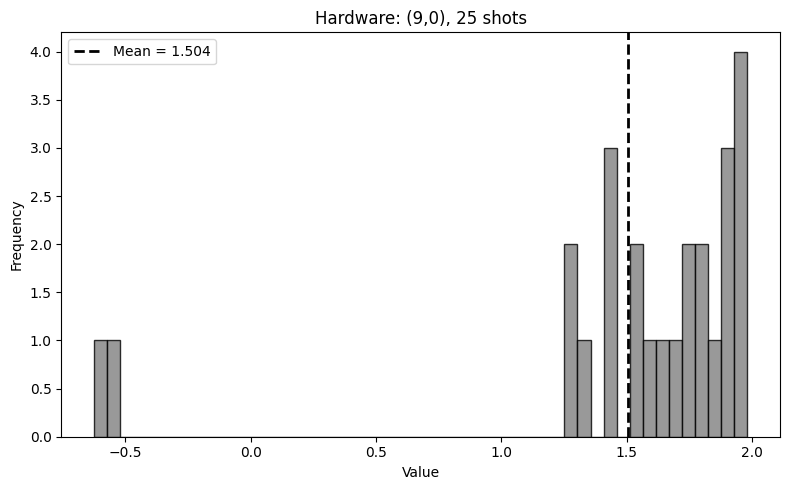

NameError: name 'shadow_results' is not defined

In [56]:
with open('Acoustic_Circ_(9, 0)-2026_02_25-12-55-20_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_9_0_h=get_shadows_from_basis(bitstring_counts,(9,0),target_state,"Hardware: (9,0), 25 shots",verbose=False)
print(shadow_results)

### (8,1): 28 shots

In [ ]:
#Circuit Upload.
basis_choice=(8,1)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=28

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  8
Will measure  Y  at target qubit
Acoustic_Circ_(8, 1)-2026_02_25-12-54-38


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

8 Y


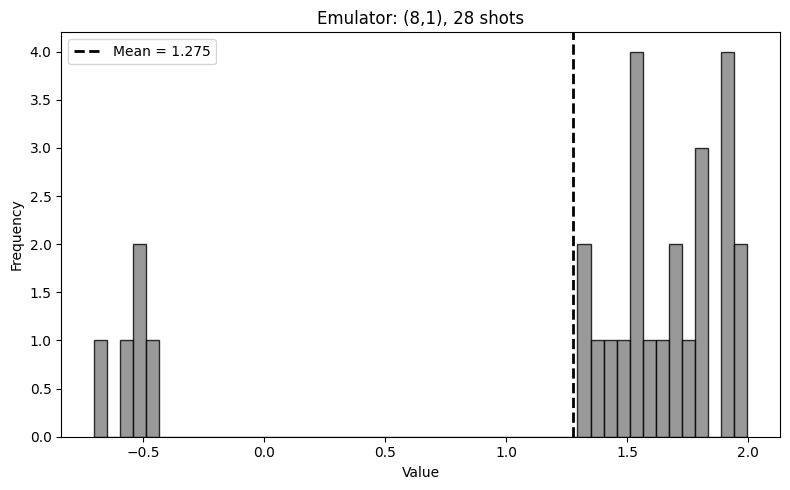

NameError: name 'shadow_results' is not defined

In [57]:
with open('Acoustic_Circ_(8, 1)-2026_02_25-08-35-38_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_8_1=get_shadows_from_basis(bitstring_counts,(8,1),target_state,"Emulator: (8,1), 28 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

8 Y


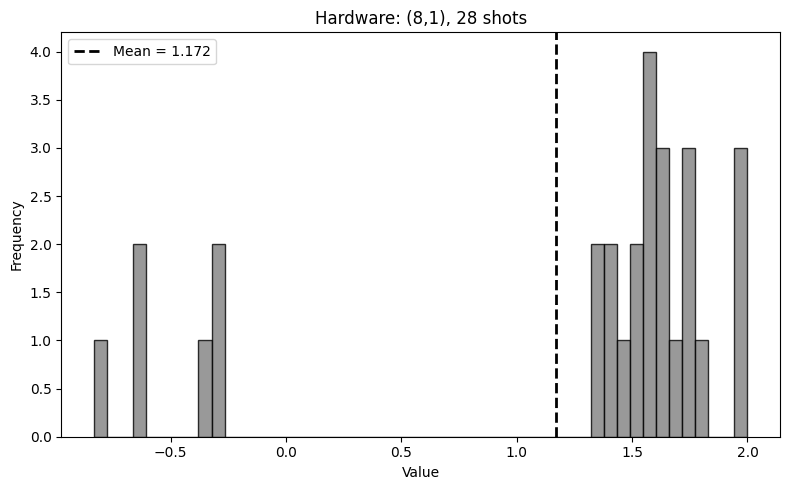

NameError: name 'shadow_results' is not defined

In [58]:
with open('Acoustic_Circ_(8, 1)-2026_02_25-12-54-38_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_8_1_h=get_shadows_from_basis(bitstring_counts,(8,1),target_state,"Hardware: (8,1), 28 shots",verbose=False)
print(shadow_results)

### (8,0): 24 shots

In [ ]:
#Circuit Upload.
basis_choice=(8,0)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=24

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  8
Will measure  X  at target qubit
Acoustic_Circ_(8, 0)-2026_02_25-12-53-56


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

8 X


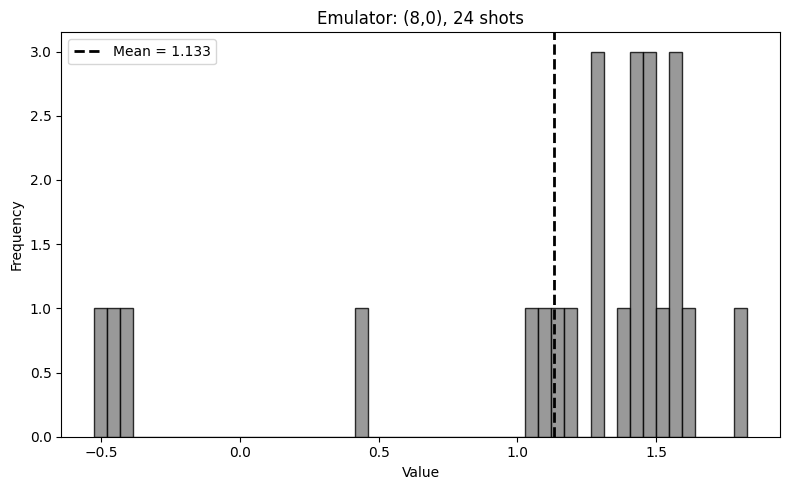

NameError: name 'shadow_results' is not defined

In [59]:
with open('Acoustic_Circ_(8, 0)-2026_02_25-08-35-25_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_8_0=get_shadows_from_basis(bitstring_counts,(8,0),target_state,"Emulator: (8,0), 24 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

8 X


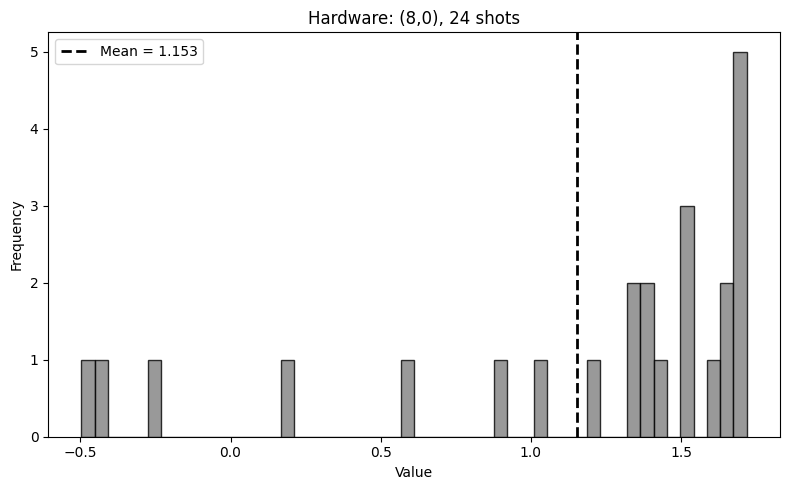

NameError: name 'shadow_results' is not defined

In [60]:
with open('Acoustic_Circ_(8, 0)-2026_02_25-12-53-56_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_8_0_h=get_shadows_from_basis(bitstring_counts,(8,0),target_state,"Hardware: (8,0), 24 shots",verbose=False)
print(shadow_results)

### (7,1): 24 shots

In [ ]:
#Circuit Upload.
basis_choice=(7,1)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=24

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  7
Will measure  Y  at target qubit
Acoustic_Circ_(7, 1)-2026_02_25-12-53-01


Exception in callback Task.__step()
handle: <Handle Task.__step()>
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\asyncio\events.py", line 88, in _run
    self._context.run(self._callback, *self._args)
RuntimeError: cannot enter context: <_contextvars.Context object at 0x0000025A880EFA00> is already entered
Exception in callback Task.__step()
handle: <Handle Task.__step()>
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\asyncio\events.py", line 88, in _run
    self._context.run(self._callback, *self._args)
RuntimeError: cannot enter context: <_contextvars.Context object at 0x0000025A880EFA00> is already entered
Task was destroyed but it is pending!
task: <Task pending name='Task-1317' coro=<_async_in_context.<locals>.run_in_context() done, defined at c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-1318' coro=<Kernel.shell_main() running at c:\Users\ar

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

7 Y


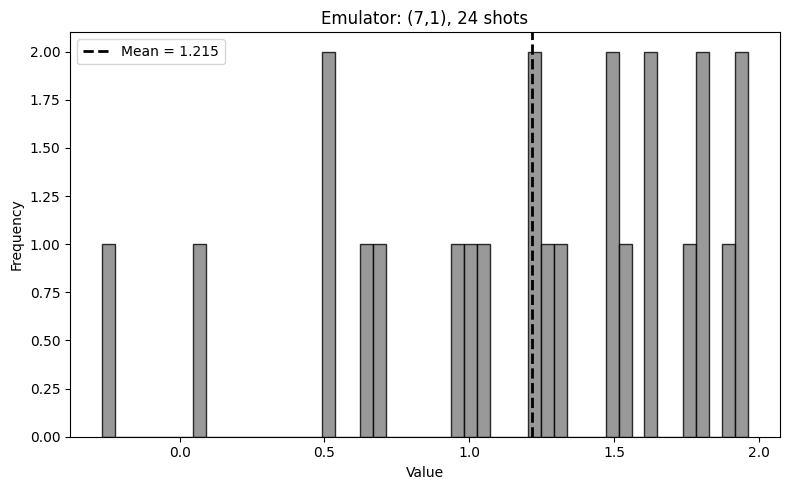

NameError: name 'shadow_results' is not defined

In [61]:
with open('Acoustic_Circ_(7, 1)-2026_02_25-08-34-46_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_7_1=get_shadows_from_basis(bitstring_counts,(7,1),target_state,"Emulator: (7,1), 24 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

7 Y


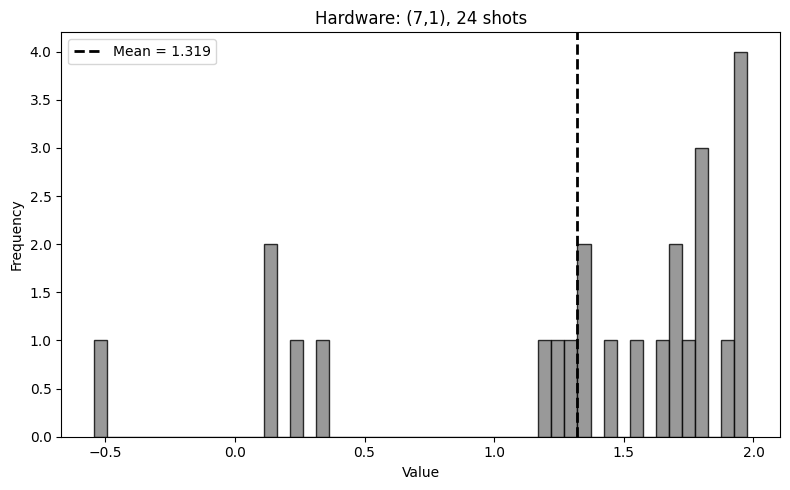

NameError: name 'shadow_results' is not defined

In [62]:
with open('Acoustic_Circ_(7, 1)-2026_02_25-12-53-01_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_7_1_h=get_shadows_from_basis(bitstring_counts,(7,1),target_state,"Hardware: (7,1), 24 shots",verbose=False)
print(shadow_results)

### (7,0): 22 shots

In [ ]:
#Circuit Upload.
basis_choice=(7,0)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=22

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  7
Will measure  X  at target qubit
Acoustic_Circ_(7, 0)-2026_02_25-12-52-18


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

7 X


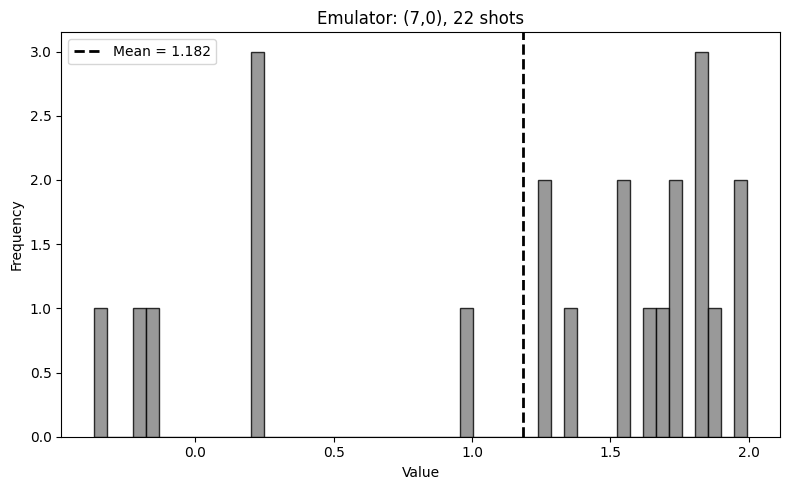

NameError: name 'shadow_results' is not defined

In [63]:
with open('Acoustic_Circ_(7, 0)-2026_02_25-08-34-21_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_7_0=get_shadows_from_basis(bitstring_counts,(7,0),target_state,"Emulator: (7,0), 22 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

7 X


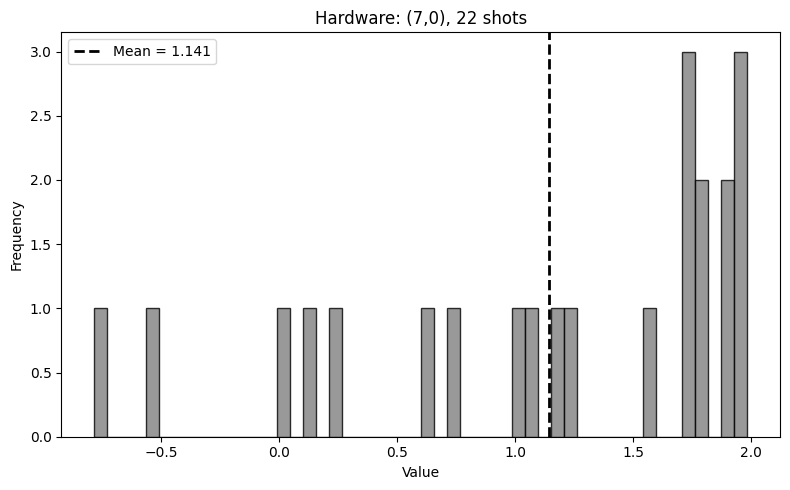

NameError: name 'shadow_results' is not defined

In [64]:
with open('Acoustic_Circ_(7, 0)-2026_02_25-12-52-18_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_7_0_h=get_shadows_from_basis(bitstring_counts,(7,0),target_state,"Hardware: (7,0), 22 shots",verbose=False)
print(shadow_results)

### (6,1): 33 shots

In [ ]:
#Circuit Upload.
basis_choice=(6,1)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=33

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  6
Will measure  Y  at target qubit
Acoustic_Circ_(6, 1)-2026_02_25-12-51-33


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

6 Y


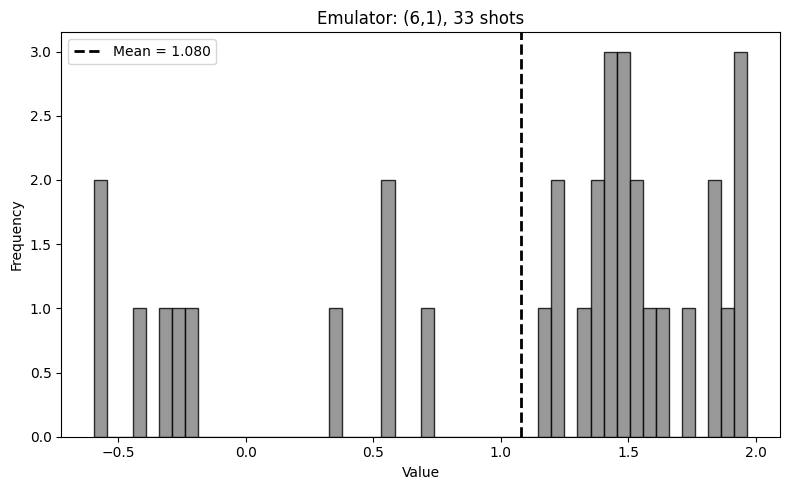

NameError: name 'shadow_results' is not defined

In [65]:
with open('Acoustic_Circ_(6, 1)-2026_02_25-08-33-27_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_6_1=get_shadows_from_basis(bitstring_counts,(6,1),target_state,"Emulator: (6,1), 33 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

6 Y


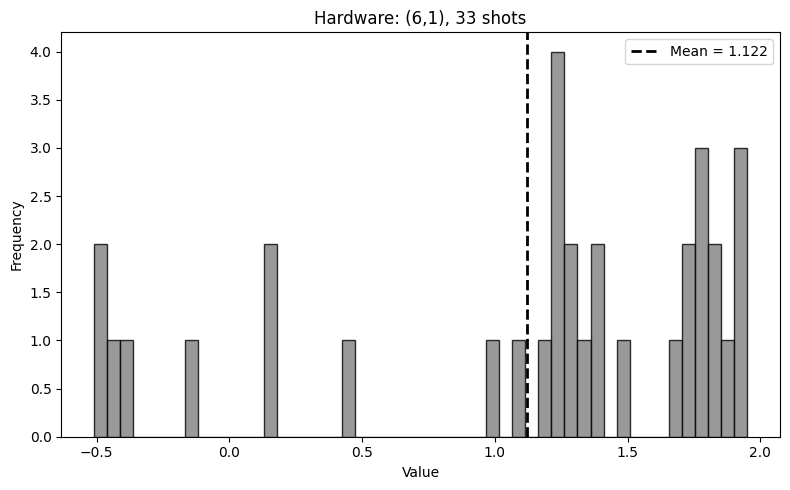

NameError: name 'shadow_results' is not defined

In [66]:
with open('Acoustic_Circ_(6, 1)-2026_02_25-12-51-33_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_6_1_h=get_shadows_from_basis(bitstring_counts,(6,1),target_state,"Hardware: (6,1), 33 shots",verbose=False)
print(shadow_results)

### (6,0) 27 shots

In [ ]:
#Circuit Upload.
basis_choice=(6,0)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=27

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  6
Will measure  X  at target qubit
Acoustic_Circ_(6, 0)-2026_02_25-12-50-48


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

6 X


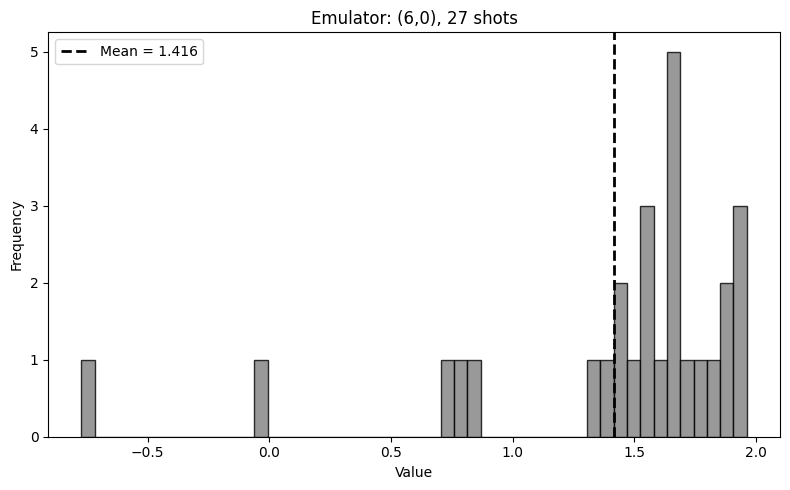

NameError: name 'shadow_results' is not defined

In [67]:
with open('Acoustic_Circ_(6, 0)-2026_02_25-08-40-15_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_6_0=get_shadows_from_basis(bitstring_counts,(6,0),target_state,"Emulator: (6,0), 27 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

6 X


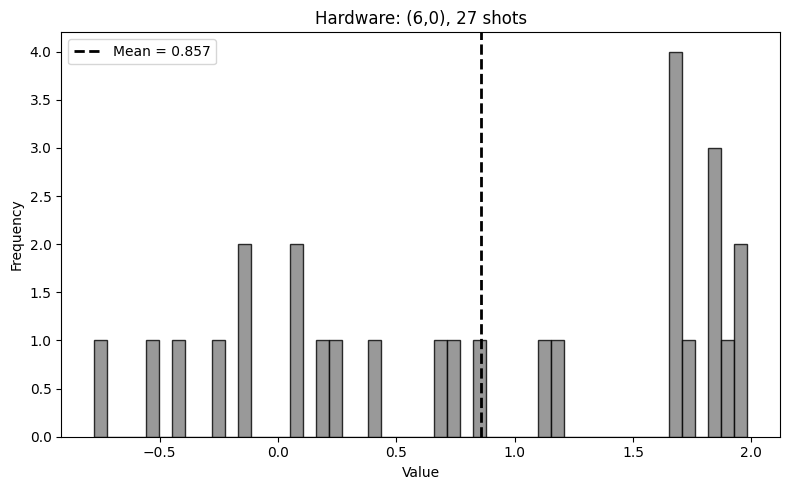

NameError: name 'shadow_results' is not defined

In [68]:
with open('Acoustic_Circ_(6, 0)-2026_02_25-12-50-48_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_6_0_h=get_shadows_from_basis(bitstring_counts,(6,0),target_state,"Hardware: (6,0), 27 shots",verbose=False)
print(shadow_results)

### (5,1) 26 shots

In [ ]:
#Circuit Upload.
basis_choice=(5,1)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=26

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  5
Will measure  Y  at target qubit
Acoustic_Circ_(5, 1)-2026_02_25-12-50-05


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

5 Y


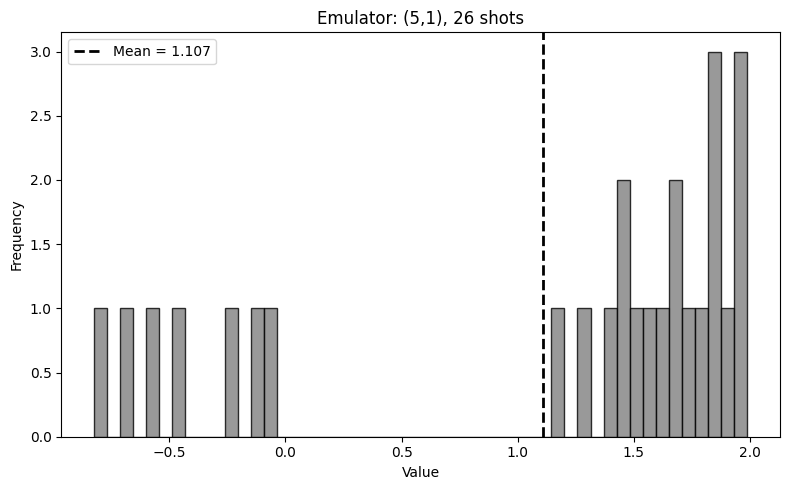

NameError: name 'shadow_results' is not defined

In [69]:
with open('Acoustic_Circ_(5, 1)-2026_02_25-08-40-01_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_5_1=get_shadows_from_basis(bitstring_counts,(5,1),target_state,"Emulator: (5,1), 26 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

5 Y


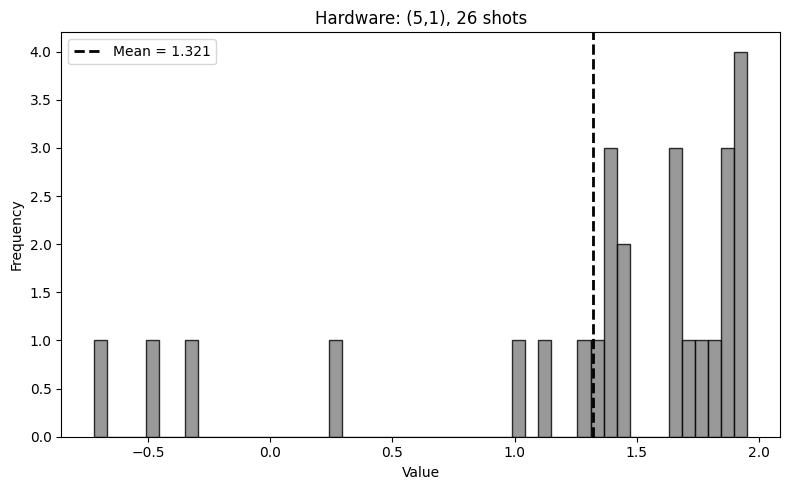

NameError: name 'shadow_results' is not defined

In [70]:
with open('Acoustic_Circ_(5, 1)-2026_02_25-12-50-05_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_5_1_h=get_shadows_from_basis(bitstring_counts,(5,1),target_state,"Hardware: (5,1), 26 shots",verbose=False)
print(shadow_results)

### (5,0): 32 shots

In [ ]:
#Circuit Upload.
basis_choice=(5,0)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=32

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  5
Will measure  X  at target qubit
Acoustic_Circ_(5, 0)-2026_02_25-12-49-19


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

5 X


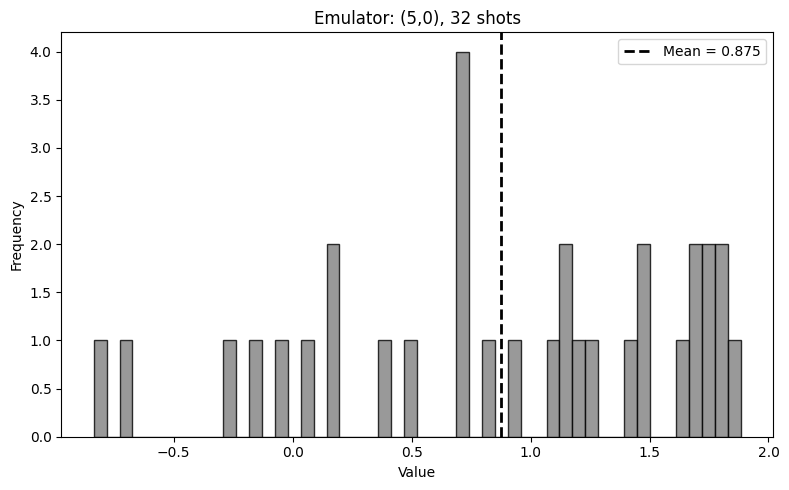

NameError: name 'shadow_results' is not defined

In [42]:
with open('Acoustic_Circ_(5, 0)-2026_02_25-08-39-34_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_5_0=get_shadows_from_basis(bitstring_counts,(5,0),target_state,"Emulator: (5,0), 32 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

5 X


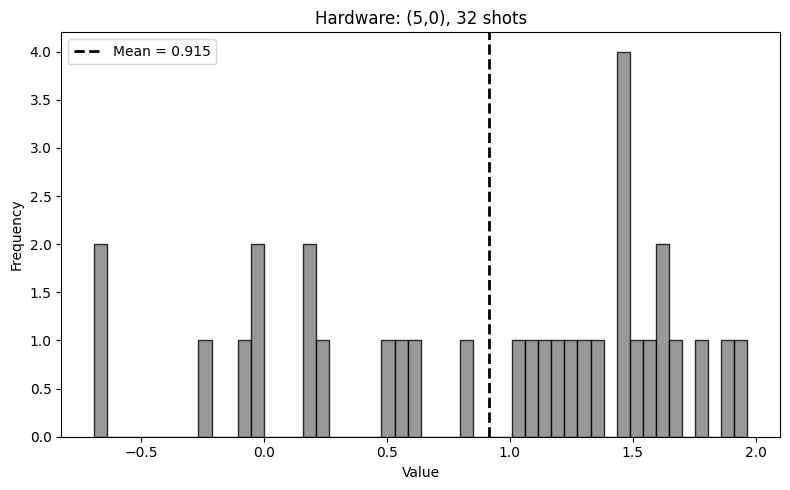

NameError: name 'shadow_results' is not defined

In [41]:
with open('Acoustic_Circ_(5, 0)-2026_02_25-12-49-19_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_5_0_h=get_shadows_from_basis(bitstring_counts,(5,0),target_state,"Hardware: (5,0), 32 shots",verbose=False)
print(shadow_results)

### (4,1): 25 shots

In [ ]:
#Circuit Upload.
basis_choice=(4,1)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=25

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  4
Will measure  Y  at target qubit
Acoustic_Circ_(4, 1)-2026_02_25-12-47-17


Exception in callback Task.__step()
handle: <Handle Task.__step()>
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\asyncio\events.py", line 88, in _run
    self._context.run(self._callback, *self._args)
RuntimeError: cannot enter context: <_contextvars.Context object at 0x0000025A880EFA00> is already entered
Exception in callback Task.__step()
handle: <Handle Task.__step()>
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\asyncio\events.py", line 88, in _run
    self._context.run(self._callback, *self._args)
RuntimeError: cannot enter context: <_contextvars.Context object at 0x0000025A880EFA00> is already entered
Task was destroyed but it is pending!
task: <Task pending name='Task-1236' coro=<_async_in_context.<locals>.run_in_context() done, defined at c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-1237' coro=<Kernel.shell_main() running at c:\Users\ar

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

4 Y


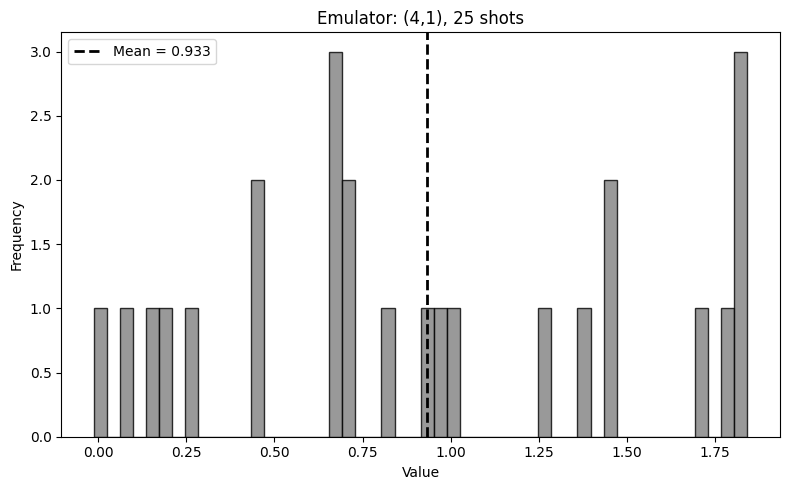

NameError: name 'shadow_results' is not defined

In [40]:
with open('Acoustic_Circ_(4, 1)-2026_02_25-08-30-47_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_4_1=get_shadows_from_basis(bitstring_counts,(4,1),target_state,"Emulator: (4,1), 25 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

4 Y


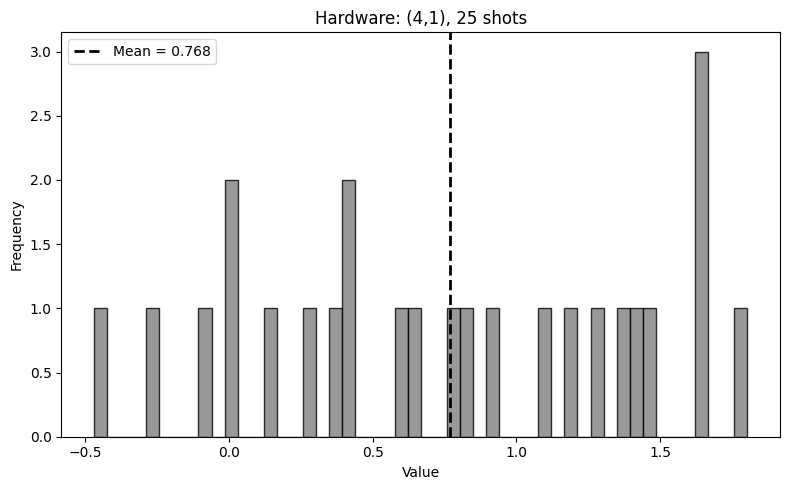

NameError: name 'shadow_results' is not defined

In [39]:
with open('Acoustic_Circ_(4, 1)-2026_02_25-12-47-17_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_4_1_h=get_shadows_from_basis(bitstring_counts,(4,1),target_state,"Hardware: (4,1), 25 shots",verbose=False)
print(shadow_results)

### (4,0): 28 shots

In [ ]:
#Circuit Upload.
basis_choice=(4,0)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=28

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  4
Will measure  X  at target qubit
Acoustic_Circ_(4, 0)-2026_02_25-12-46-35


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

4 X


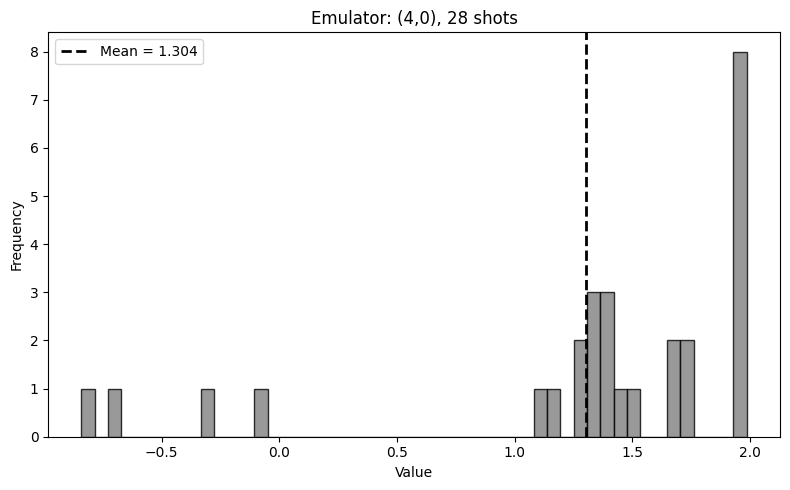

NameError: name 'shadow_results' is not defined

In [38]:
with open('Acoustic_Circ_(4, 0)-2026_02_25-08-29-58_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_4_0=get_shadows_from_basis(bitstring_counts,(4,0),target_state,"Emulator: (4,0), 28 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

4 X


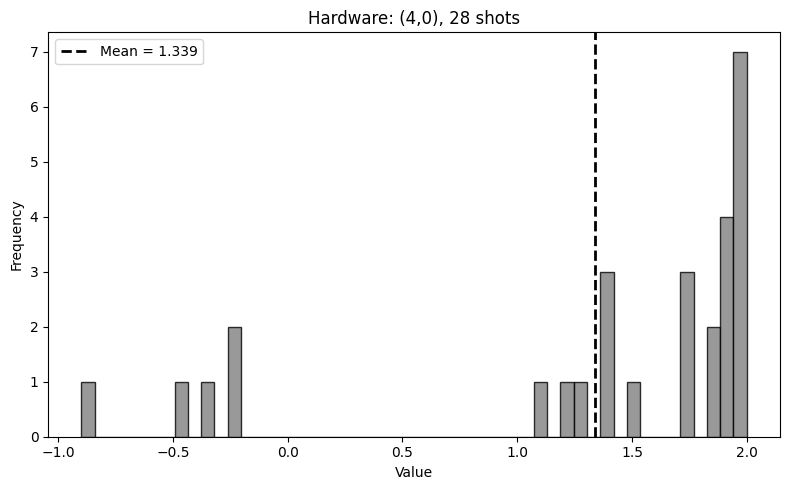

NameError: name 'shadow_results' is not defined

In [37]:
with open('Acoustic_Circ_(4, 0)-2026_02_25-12-46-35_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_4_0_h=get_shadows_from_basis(bitstring_counts,(4,0),target_state,"Hardware: (4,0), 28 shots",verbose=False)
print(shadow_results)

### (3,1): 24 shots

In [ ]:
#Circuit Upload.
basis_choice=(3,1)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=24

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  3
Will measure  Y  at target qubit
Acoustic_Circ_(3, 1)-2026_02_25-12-45-52


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

3 Y


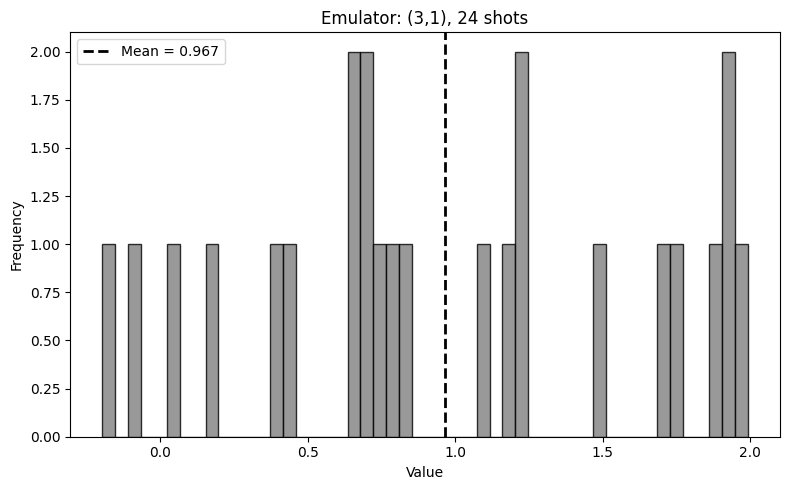

NameError: name 'shadow_results' is not defined

In [36]:
with open('Acoustic_Circ_(3, 1)-2026_02_25-08-28-38_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_3_1=get_shadows_from_basis(bitstring_counts,(3,1),target_state,"Emulator: (3,1), 24 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

3 Y


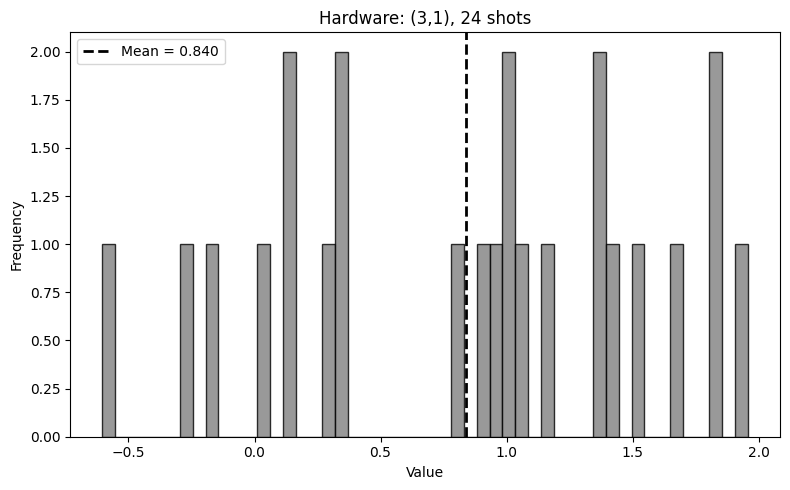

NameError: name 'shadow_results' is not defined

In [35]:
with open('Acoustic_Circ_(3, 1)-2026_02_25-12-45-52_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_3_1_h=get_shadows_from_basis(bitstring_counts,(3,1),target_state,"Hardware: (3,1), 24 shots",verbose=False)
print(shadow_results)

### (3,0): 32 shots

In [ ]:
#Circuit Upload.
basis_choice=(3,0)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=32

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  3
Will measure  X  at target qubit
Acoustic_Circ_(3, 0)-2026_02_25-12-44-17


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

3 X


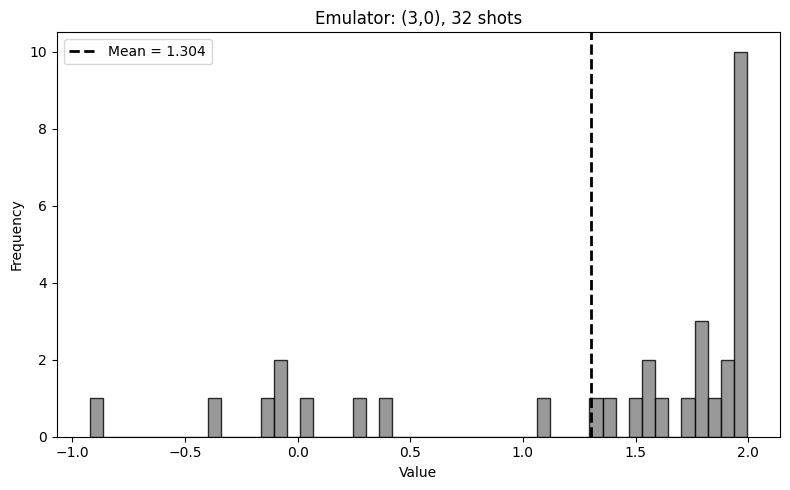

NameError: name 'shadow_results' is not defined

In [34]:
with open('Acoustic_Circ_(3, 0)-2026_02_25-08-28-13_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_3_0=get_shadows_from_basis(bitstring_counts,(3,0),target_state,"Emulator: (3,0), 32 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

3 X


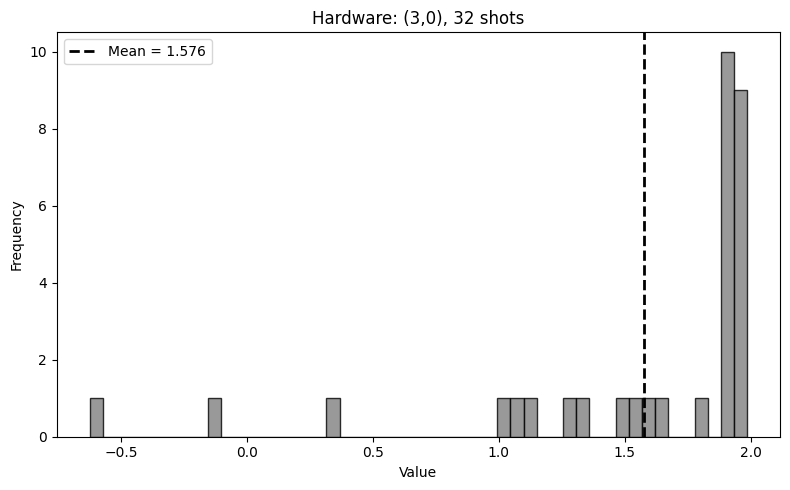

NameError: name 'shadow_results' is not defined

In [33]:
with open('Acoustic_Circ_(3, 0)-2026_02_25-12-44-17_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_3_0_h=get_shadows_from_basis(bitstring_counts,(3,0),target_state,"Hardware: (3,0), 32 shots",verbose=False)
print(shadow_results)

### (2,1): 18 shots

In [ ]:
#Circuit Upload.
basis_choice=(2,1)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=18

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  2
Will measure  Y  at target qubit
Acoustic_Circ_(2, 1)-2026_02_25-12-43-03


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

2 Y


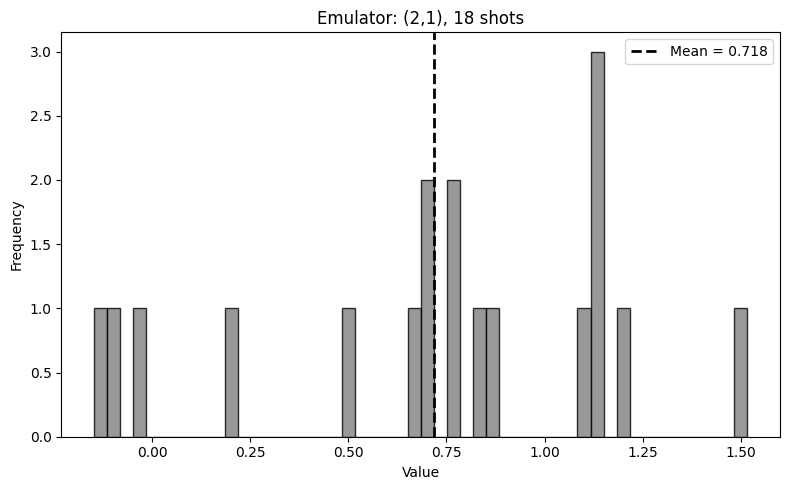

NameError: name 'shadow_results' is not defined

In [90]:
with open('Acoustic_Circ_(2, 1)-2026_02_25-08-27-18_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_2_1=get_shadows_from_basis(bitstring_counts,(2,1),target_state,"Emulator: (2,1), 18 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

2 Y


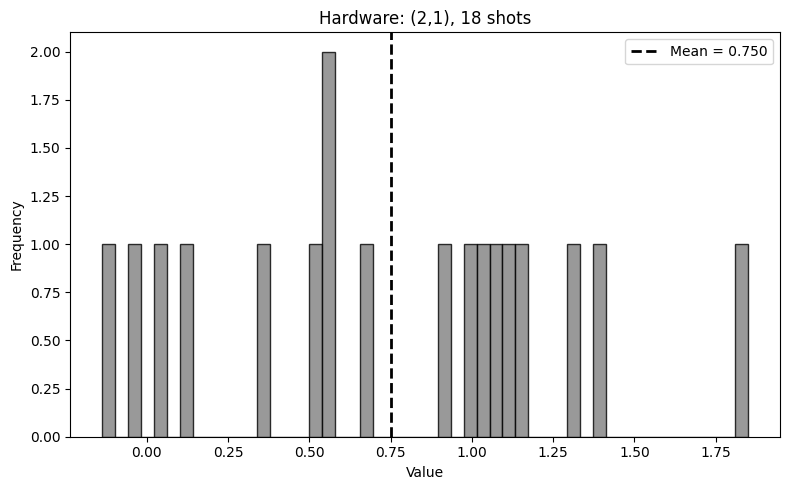

NameError: name 'shadow_results' is not defined

In [32]:
with open('Acoustic_Circ_(2, 1)-2026_02_25-12-43-03_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_2_1_h=get_shadows_from_basis(bitstring_counts,(2,1),target_state,"Hardware: (2,1), 18 shots",verbose=False)
print(shadow_results)

### (2,0): 22 shots

In [ ]:
#Circuit Upload.
basis_choice=(2,0)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=22

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  2
Will measure  X  at target qubit
Acoustic_Circ_(2, 0)-2026_02_25-12-41-52


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

2 X


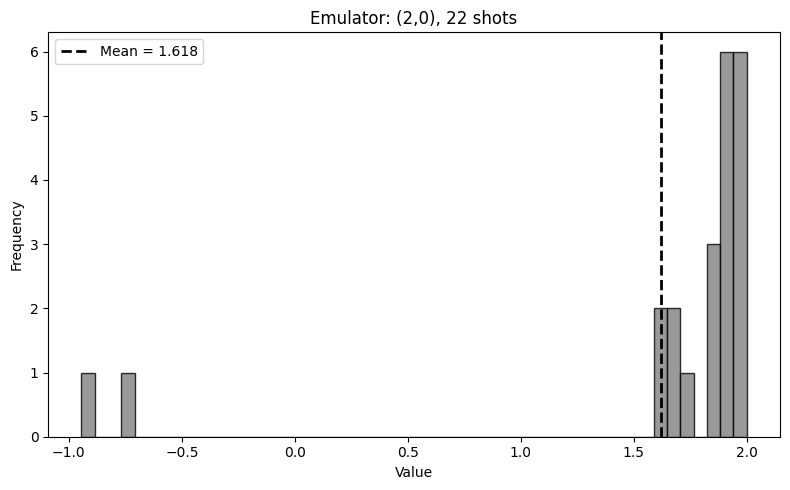

NameError: name 'shadow_results' is not defined

In [89]:
with open('Acoustic_Circ_(2, 0)-2026_02_25-08-26-56_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_2_0=get_shadows_from_basis(bitstring_counts,(2,0),target_state,"Emulator: (2,0), 22 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

2 X


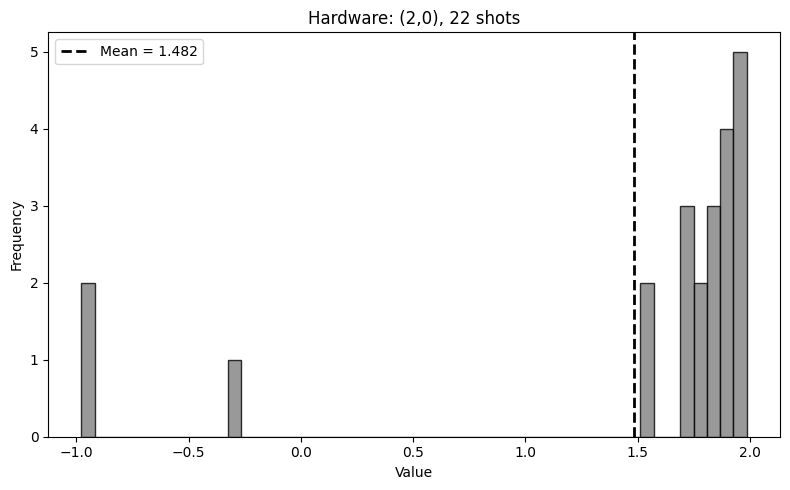

NameError: name 'shadow_results' is not defined

In [31]:
with open('Acoustic_Circ_(2, 0)-2026_02_25-12-41-52_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_2_0_h=get_shadows_from_basis(bitstring_counts,(2,0),target_state,"Hardware: (2,0), 22 shots",verbose=False)
print(shadow_results)

### (1,1): 30 shots

In [ ]:
#Circuit Upload.
basis_choice=(1,1)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=30

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  1
Will measure  Y  at target qubit
Acoustic_Circ_(1, 1)-2026_02_25-12-37-56


Exception in callback Task.__step()
handle: <Handle Task.__step()>
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\asyncio\events.py", line 88, in _run
    self._context.run(self._callback, *self._args)
RuntimeError: cannot enter context: <_contextvars.Context object at 0x0000025A880EFA00> is already entered
Exception in callback Task.__step()
handle: <Handle Task.__step()>
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\asyncio\events.py", line 88, in _run
    self._context.run(self._callback, *self._args)
RuntimeError: cannot enter context: <_contextvars.Context object at 0x0000025A880EFA00> is already entered
Task was destroyed but it is pending!
task: <Task pending name='Task-1164' coro=<_async_in_context.<locals>.run_in_context() done, defined at c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-1165' coro=<Kernel.shell_main() running at c:\Users\ar

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

1 Y


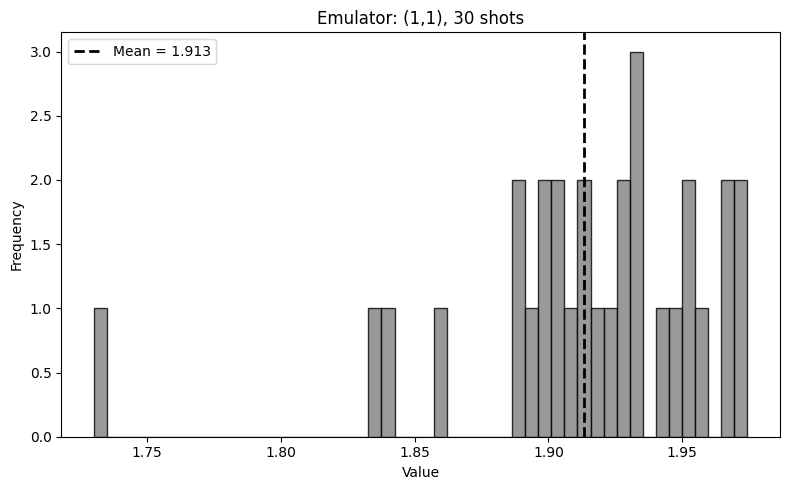

NameError: name 'shadow_results' is not defined

In [88]:
with open('Acoustic_Circ_(1, 1)-2026_02_25-08-26-16_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_1_1=get_shadows_from_basis(bitstring_counts,(1,1),target_state,"Emulator: (1,1), 30 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

1 Y


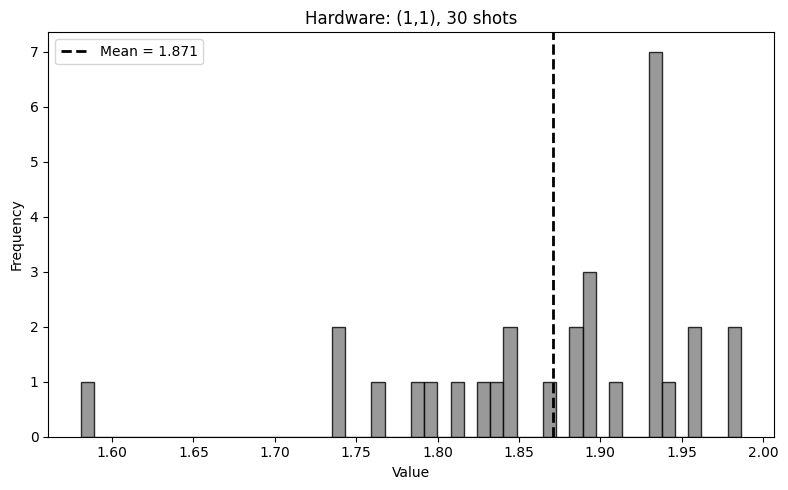

NameError: name 'shadow_results' is not defined

In [30]:
with open('Acoustic_Circ_(1, 1)-2026_02_25-12-37-56_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_1_1_h=get_shadows_from_basis(bitstring_counts,(1,1),target_state,"Hardware: (1,1), 30 shots",verbose=False)
print(shadow_results)

### (1,0): 24 shots

In [ ]:
#Circuit Upload.
basis_choice=(1,0)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=24

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)
print(name)
with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  1
Will measure  X  at target qubit
Acoustic_Circ_(1, 0)-2026_02_25-09-26-23


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

1 X


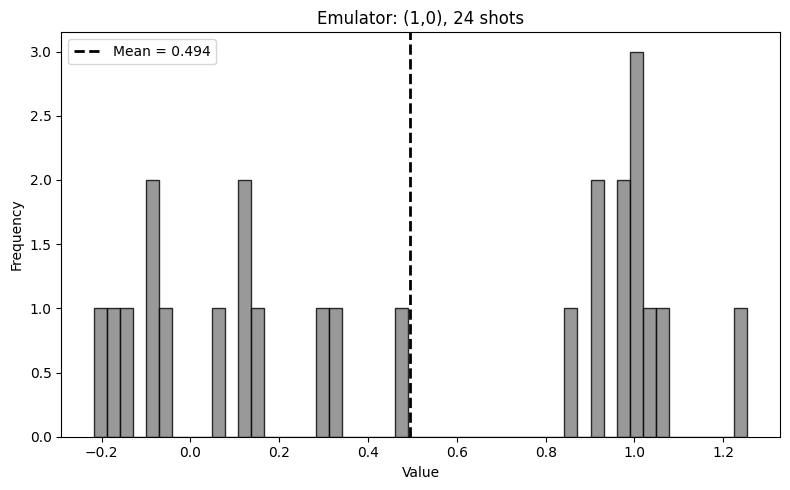

NameError: name 'shadow_results' is not defined

In [87]:
with open('Acoustic_Circ_(1, 0)-2026_02_25-08-21-25_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_1_0=get_shadows_from_basis(bitstring_counts,(1,0),target_state,"Emulator: (1,0), 24 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

1 X


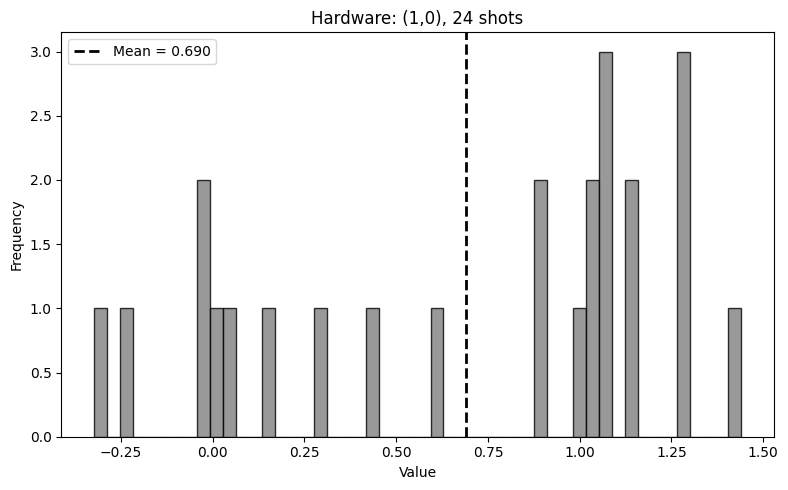

NameError: name 'shadow_results' is not defined

In [29]:
with open('Acoustic_Circ_(1, 0)-2026_02_25-09-26-23_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_1_0_h=get_shadows_from_basis(bitstring_counts,(1,0),target_state,"Hardware: (1,0), 24 shots",verbose=False)
print(shadow_results)

### (0,1): 18 shots

In [185]:
#Circuit Upload.
basis_choice=(0,1)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="H2-1") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=18

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)
with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  0
Will measure  Y  at target qubit
Acoustic_Circ_(0, 1)-2026_02_25-12-31-29


Acoustic_Circ_(0, 1)-2026_02_25-08-15-05


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

0 Y


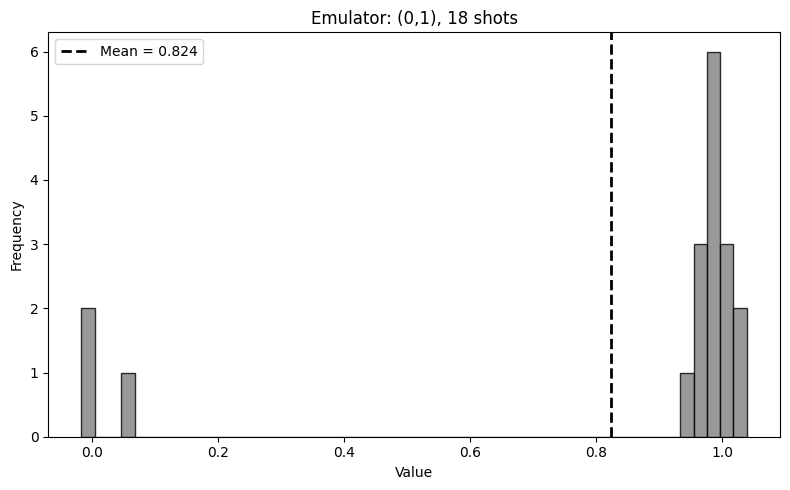

NameError: name 'shadow_results' is not defined

In [82]:
with open('Acoustic_Circ_(0, 1)-2026_02_25-08-15-05_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_0_1=get_shadows_from_basis(bitstring_counts,(0,1),target_state,"Emulator: (0,1), 18 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

0 Y


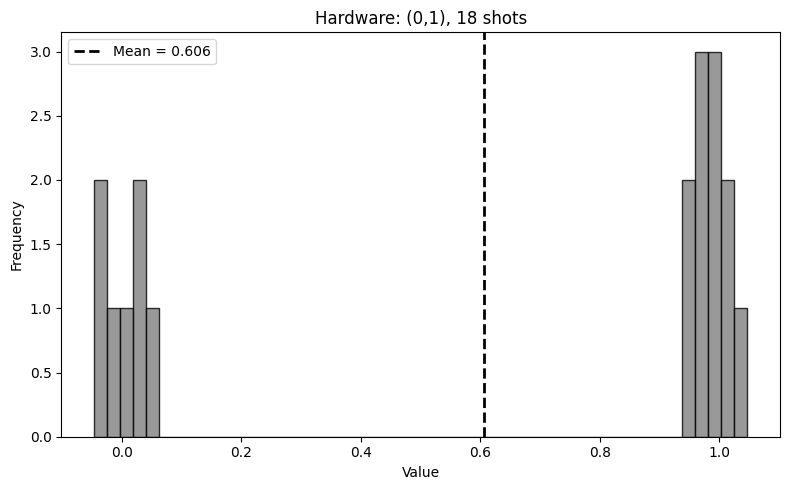

NameError: name 'shadow_results' is not defined

In [28]:
with open('Acoustic_Circ_(0, 1)-2026_02_25-12-31-29_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_0_1_h=get_shadows_from_basis(bitstring_counts,(0,1),target_state,"Hardware: (0,1), 18 shots",verbose=False)
print(shadow_results)

### (0,0): 30 Shots

In [186]:
#Circuit Upload.
basis_choice=(0,0)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="H2-1") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]
#execute job
shots=30

job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)

with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Target Qubit is:  0
Will measure  X  at target qubit
Acoustic_Circ_(0, 0)-2026_02_25-12-35-11


--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

0 X


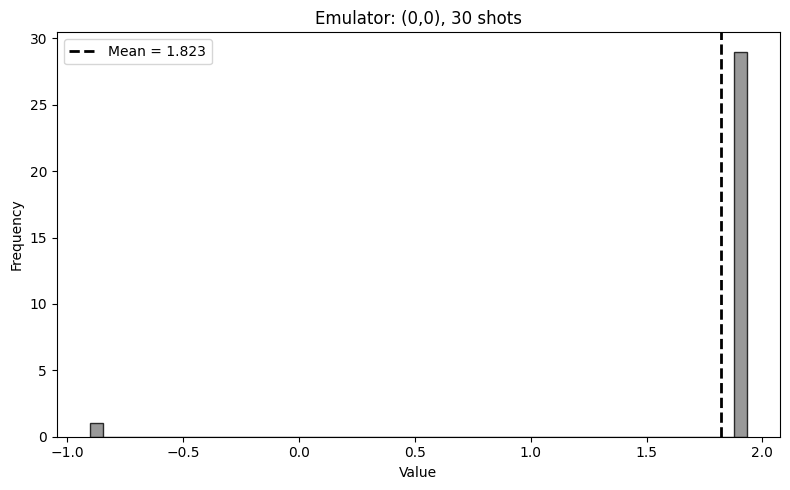

NameError: name 'shadow_results' is not defined

In [85]:
with open('Acoustic_Circ_(0, 0)-2026_02_24-20-41-04_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_0_0=get_shadows_from_basis(bitstring_counts,(0,0),target_state,"Emulator: (0,0), 30 shots",verbose=False)
print(shadow_results)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

0 X


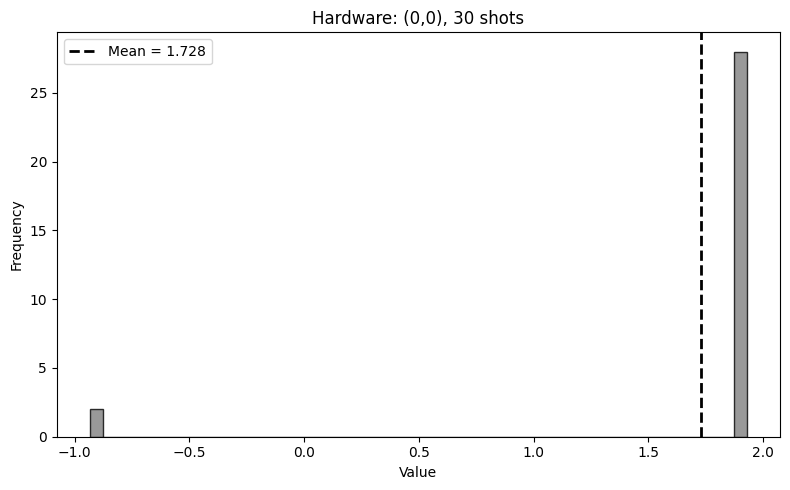

NameError: name 'shadow_results' is not defined

In [27]:
with open('Acoustic_Circ_(0, 0)-2026_02_25-12-35-11_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_0_0_h=get_shadows_from_basis(bitstring_counts,(0,0),target_state,"Hardware: (0,0), 30 shots",verbose=False)
print(shadow_results)

### (_,2): 333 Shots

In [24]:
#Circuit Upload.
basis_choice=(12,2)
tket_accoustic_circuit=arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True,basis_choice=basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"Acoustic_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tket_accoustic_circuit]
backend = qnx.QuantinuumConfig(device_name="H2-1") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]

Target Qubit is:  12
Will measure  Z  at target qubit
Acoustic_Circ_(12, 2)-2026_02_26-08-40-46


In [54]:
#Get circuit cost if running the syntax checker (will only work for syntax checker)\
print("1-qubit gates",compiled_circuits[0].n_1qb_gates())
print("2-qubit gates",compiled_circuits[0].n_2qb_gates())
cost=qnx.client.circuits.cost(
    circuit_ref = compiled_circuits_ref[0],
    n_shots = 333,
    backend_config = backend
)
print("Cost for given shots is",cost)

1-qubit gates 229
2-qubit gates 108
Cost for given shots is 100.83


In [25]:
#execute job
shots=333
job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)
print(name)
with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

Acoustic_Circ_(12, 2)-2026_02_26-08-40-46


In [75]:
import random
def get_shadows_from_basis_allcomp(results,target_state,title,verbose:bool=False):
    """
    This function is needed for the niche purpose of batching all of the (_,2) together. Data is collected in the same way for all
    the different basis but we need to make sure they are still all processed randomly as requied on each qubit. This is hardcoded into the funciton, this random choice of which ones they will be in.
    results: dict mapping bitstring -> count
    basis_choice: structure giving Pauli choice per qubit
    """
    
    estimates = []
    paulis = ['X', 'Y', 'Z']

      #if only comp basis selected then make sure we measure in Z.
    
    P = paulis[2]

    # --- Step 1: Expand dictionary into explicit shot list ---
    shot_list = []
    for bitstring, count in results.items():
        shot_list.extend([bitstring] * count)
    if verbose:
        print("Shot list unpacked",shot_list)
    # Shuffle shots randomly
    random.shuffle(shot_list)
    if verbose:
        print("Randomised shot list",shot_list)

    #Break shot list into desired sizes
    shot_segments = []
    sizes= [26,28,22,28,18,28,27,25,22,23,31,24,31]
    start = 0
    for size in sizes:
        end = start + size
        shot_segments.append(shot_list[start:end])
        start = end
    

    #HERE CYCLE OVER ALL THE DIFFERENT SHOTS THAT NEED TO TAKE PLACE
    # --- Step 3: Process each shot sequentially ---
    target_qubit=0
    for shots in shot_segments:
        print("Measuring on qubit",target_qubit, "with", shots)
        for measurement in shots:
            if verbose:
                print(f"Processing shot: {bitstring}")
            # --- Your existing per-shot logic goes here ---
            # e.g. compute single-shot shadow estimate
            conditional_target_qubit_state=build_conditional_postmeasurement_single_qubit(target_state,measurement,target_qubit,verbose=verbose)
            estimate=compute_local_overlap(conditional_target_qubit_state, int(measurement[target_qubit]),P,verbose=verbose)
            estimates.append(estimate)
        target_qubit=target_qubit+1
    # ---- Histogram Plot ----
    mean= np.mean(estimates)

    # ---- plotting ----
    plt.figure(figsize=(8,5))

    # histogram (grey bars with black edges)
    plt.hist(
        estimates,
        bins=50,
        color='grey',
        edgecolor='black',
        alpha=0.8
    )

    # mean line (black dashed)
    plt.axvline(
        mean,
        color='black',
        linestyle='--',
        linewidth=2,
        label=f"Mean = {mean:.3f}"
    )
    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.title(
        title
    )
    plt.legend()
    plt.tight_layout()
    plt.show()

    return estimates

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

Measuring on qubit 0 with ['0000010010000', '1010110101011', '1111010011101', '0110000001110', '0111011000110', '0110001000001', '0101101100111', '0100001110111', '1100000111001', '0011000000001', '1001001000101', '0110011110101', '0110001111001', '1011001001101', '1010000111001', '1011010001101', '1110101111101', '0101011110011', '1010010110100', '0101010000010', '1010111001001', '1110010111111', '1111101110100', '1100101000101', '0111001111110', '0011011011001']
Measuring on qubit 1 with ['1000100010101', '0101101111110', '0010111100010', '1000101000110', '1101000000000', '0101100010111', '0001000001101', '1110110011111', '1010110100000', '0101101011100', '0011011010111', '0011100010111', '1101010011100', '1000010111001', '1001011000000', '1010110001000', '1001101001001', '0110100111010', '1110111110110', '0101011001011', '1010111100110', '1011001001100', '0100110100111', '0000000111011', '0010110001001', '1011111010100', '0101111001010', '1011011100110']
Measuring on qubit 2 with ['

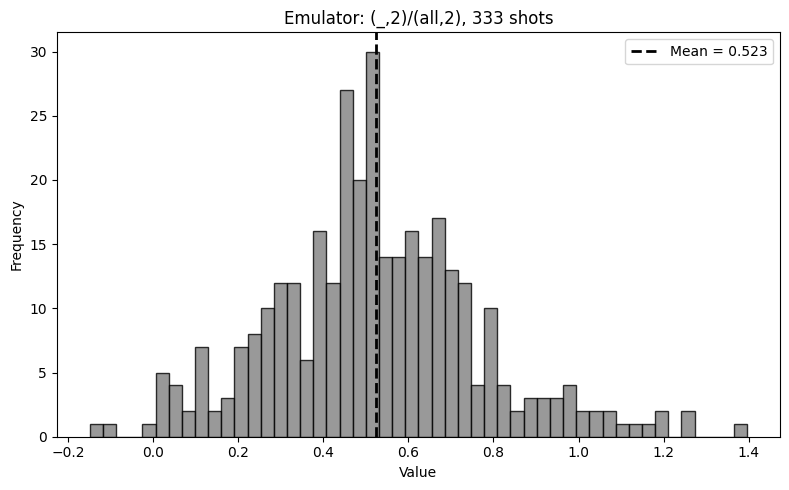

[np.float64(0.5340071516466751), np.float64(0.4586317357679469), np.float64(0.5014463121306881), np.float64(0.4494784224136626), np.float64(0.4859959857500768), np.float64(0.45657222170953843), np.float64(0.49835105977246463), np.float64(0.46678896433080674), np.float64(0.5125633125202504), np.float64(0.4770295715448915), np.float64(0.5301250506811309), np.float64(0.4677625318966827), np.float64(0.45877851537116676), np.float64(0.5154164201310516), np.float64(0.45509059563171944), np.float64(0.49828565770767397), np.float64(0.5309487835215478), np.float64(0.5138956780814505), np.float64(0.4584590472985802), np.float64(0.5139584771877211), np.float64(0.4629883928823817), np.float64(0.5353540991610659), np.float64(0.5254433299853125), np.float64(0.5382490996879629), np.float64(0.5258040116740598), np.float64(0.5169655414910067), np.float64(0.5690706211973197), np.float64(0.2979040128543904), np.float64(0.7014224527652666), np.float64(0.5786088879744709), np.float64(0.4460302950826809), n

In [79]:
with open('Acoustic_Circ_(12, 2)-2026_02_24-14-57-31_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_all_2=get_shadows_from_basis_allcomp(bitstring_counts,target_state,"Emulator: (_,2)/(all,2), 333 shots",verbose=False)
print(shadow_results_all_2)

--- Logging error ---
Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\qnexus\models\__init__.py", line 384, in to_pytket_backend_info
    gate_set.add(getattr(OpType, gate))
                 ^^^^^^^^^^^^^^^^^^^^^
AttributeError: type object 'OpType' has no attribute 'RZZ'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 1160, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 999, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 703, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\archi\anaconda3\envs\newMPS\Lib\logging\__init__.py", line 392, in getMessage
   

Measuring on qubit 0 with ['1100000101110', '0000111110010', '0001001111011', '1011100010011', '1011000010011', '0011100001000', '0000011001111', '0010110001000', '0111001110000', '1110100100101', '0100100100100', '1111100110101', '1010010011110', '1100001101001', '0000111001010', '1001011010111', '1111010001100', '0111100010011', '1110100000011', '0111100010011', '0110110011101', '1010101110101', '0001101011010', '0010100111000', '1101000010110', '0110001011011']
Measuring on qubit 1 with ['1111001111011', '0110110001110', '0101001111111', '0011011110100', '1110110001000', '1111110111011', '1010001110010', '0000110100100', '1111001111111', '0011110000111', '0010101101111', '0000010111110', '0001100000000', '0011100110111', '0110010011010', '1010001110110', '1110110100011', '0001000001010', '1010011101110', '0110110111000', '0010110001110', '1110101011001', '1100100011010', '0000001011001', '1010010111101', '1111101110110', '1111001101010', '1000011111100']
Measuring on qubit 2 with ['

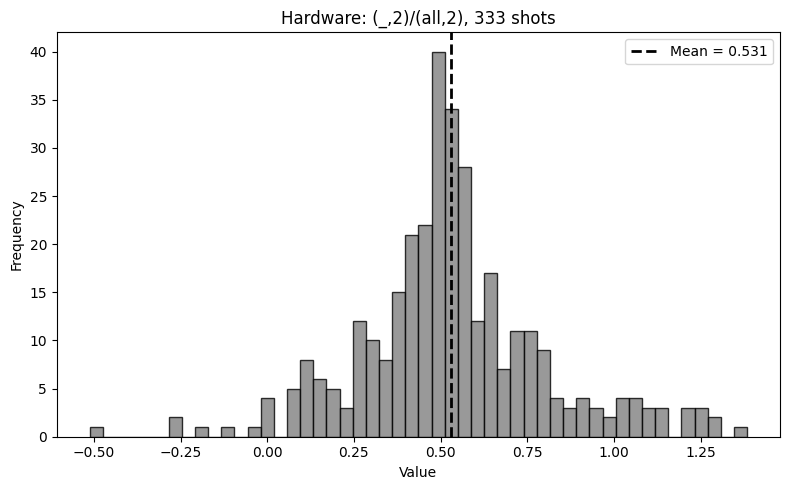

[np.float64(0.5208399917752142), np.float64(0.5447625590453796), np.float64(0.46004040106929334), np.float64(0.47517963084489795), np.float64(0.5173036148727235), np.float64(0.5214580036066188), np.float64(0.5383073946473618), np.float64(0.541294996209473), np.float64(0.5242826720788847), np.float64(0.5252253516126804), np.float64(0.4630152583823229), np.float64(0.5167018539724926), np.float64(0.4602899038425699), np.float64(0.5227210222706249), np.float64(0.535733946881335), np.float64(0.5075219649973609), np.float64(0.49584549163452774), np.float64(0.4767990401529572), np.float64(0.5289146413456365), np.float64(0.4767990401529572), np.float64(0.4625390500490727), np.float64(0.46286380062786364), np.float64(0.5192821685774169), np.float64(0.5394325116760278), np.float64(0.44780282603358146), np.float64(0.4563069393280895), np.float64(0.5173755907706439), np.float64(0.7030392928673121), np.float64(0.5682064285756179), np.float64(0.3712232076377459), np.float64(0.7573838952253382), np.f

In [76]:
with open('Acoustic_Circ_(12, 2)-2026_02_26-08-40-46_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
bitstring_counts = {
    ''.join(map(str, bit_tuple)): count
    for bit_tuple, count in result_counts.items()
}
shadow_results_all_2_h=get_shadows_from_basis_allcomp(bitstring_counts,target_state,"Hardware: (_,2)/(all,2), 333 shots",verbose=False)
print(shadow_results_all_2_h)

### Compliation of results (Emulator and Hardware)

#### load results into storage

In [112]:
all_shadow_results_emulator = (
    shadow_results_all_2
    + shadow_results_0_0
    + shadow_results_0_1
    + shadow_results_1_0
    + shadow_results_1_1
    + shadow_results_2_0
    + shadow_results_2_1
    + shadow_results_3_0
    + shadow_results_3_1
    + shadow_results_4_0
    + shadow_results_4_1
    + shadow_results_5_0
    + shadow_results_5_1
    + shadow_results_6_0
    + shadow_results_6_1
    + shadow_results_7_0
    + shadow_results_7_1
    + shadow_results_8_0
    + shadow_results_8_1
    + shadow_results_9_0
    + shadow_results_9_1
    + shadow_results_10_0
    + shadow_results_10_1
    + shadow_results_11_0
    + shadow_results_11_1
    + shadow_results_12_0
    + shadow_results_12_1
)

shadow_results_emulator = {
    "all results": all_shadow_results_emulator,

    "all_2": shadow_results_all_2,

    "0_0": shadow_results_0_0,
    "0_1": shadow_results_0_1,

    "1_0": shadow_results_1_0,
    "1_1": shadow_results_1_1,

    "2_0": shadow_results_2_0,
    "2_1": shadow_results_2_1,

    "3_0": shadow_results_3_0,
    "3_1": shadow_results_3_1,

    "4_0": shadow_results_4_0,
    "4_1": shadow_results_4_1,

    "5_0": shadow_results_5_0,
    "5_1": shadow_results_5_1,

    "6_0": shadow_results_6_0,
    "6_1": shadow_results_6_1,

    "7_0": shadow_results_7_0,
    "7_1": shadow_results_7_1,

    "8_0": shadow_results_8_0,
    "8_1": shadow_results_8_1,

    "9_0": shadow_results_9_0,
    "9_1": shadow_results_9_1,

    "10_0": shadow_results_10_0,
    "10_1": shadow_results_10_1,

    "11_0": shadow_results_11_0,
    "11_1": shadow_results_11_1,

    "12_0": shadow_results_12_0,
    "12_1": shadow_results_12_1,
}

import pickle

with open("shadow_results_emulator.pkl", "wb") as f:
    pickle.dump(shadow_results_emulator, f)

In [109]:
all_shadow_results_hardware = (shadow_results_all_2_h+
    shadow_results_0_0_h
    + shadow_results_0_1_h
    + shadow_results_1_0_h
    + shadow_results_1_1_h
    + shadow_results_2_0_h
    + shadow_results_2_1_h
    + shadow_results_3_0_h
    + shadow_results_3_1_h
    + shadow_results_4_0_h
    + shadow_results_4_1_h
    + shadow_results_5_0_h
    + shadow_results_5_1_h
    + shadow_results_6_0_h
    + shadow_results_6_1_h
    + shadow_results_7_0_h
    + shadow_results_7_1_h
    + shadow_results_8_0_h
    + shadow_results_8_1_h
    + shadow_results_9_0_h
    + shadow_results_9_1_h
    + shadow_results_10_0_h
    + shadow_results_10_1_h
    + shadow_results_11_0_h
    + shadow_results_11_1_h
    + shadow_results_12_0_h
    + shadow_results_12_1_h
)
shadow_results_hardware = {
    "all results": all_shadow_results_hardware,
    
    "all_2": shadow_results_all_2_h,

    "0_0": shadow_results_0_0_h,
    "0_1": shadow_results_0_1_h,

    "1_0": shadow_results_1_0_h,
    "1_1": shadow_results_1_1_h,

    "2_0": shadow_results_2_0_h,
    "2_1": shadow_results_2_1_h,

    "3_0": shadow_results_3_0_h,
    "3_1": shadow_results_3_1_h,

    "4_0": shadow_results_4_0_h,
    "4_1": shadow_results_4_1_h,

    "5_0": shadow_results_5_0_h,
    "5_1": shadow_results_5_1_h,

    "6_0": shadow_results_6_0_h,
    "6_1": shadow_results_6_1_h,

    "7_0": shadow_results_7_0_h,
    "7_1": shadow_results_7_1_h,

    "8_0": shadow_results_8_0_h,
    "8_1": shadow_results_8_1_h,

    "9_0": shadow_results_9_0_h,
    "9_1": shadow_results_9_1_h,

    "10_0": shadow_results_10_0_h,
    "10_1": shadow_results_10_1_h,

    "11_0": shadow_results_11_0_h,
    "11_1": shadow_results_11_1_h,

    "12_0": shadow_results_12_0_h,
    "12_1": shadow_results_12_1_h,

}
import pickle

with open("shadow_results_hardware.pkl", "wb") as f:
    pickle.dump(shadow_results_hardware, f)

In [110]:
import pickle

with open("shadow_results_hardware.pkl", "rb") as f:
    shadow_results_hardware = pickle.load(f)

In [111]:
shadow_results_hardware

{'all results': [np.float64(0.5208399917752142),
  np.float64(0.5447625590453796),
  np.float64(0.46004040106929334),
  np.float64(0.47517963084489795),
  np.float64(0.5173036148727235),
  np.float64(0.5214580036066188),
  np.float64(0.5383073946473618),
  np.float64(0.541294996209473),
  np.float64(0.5242826720788847),
  np.float64(0.5252253516126804),
  np.float64(0.4630152583823229),
  np.float64(0.5167018539724926),
  np.float64(0.4602899038425699),
  np.float64(0.5227210222706249),
  np.float64(0.535733946881335),
  np.float64(0.5075219649973609),
  np.float64(0.49584549163452774),
  np.float64(0.4767990401529572),
  np.float64(0.5289146413456365),
  np.float64(0.4767990401529572),
  np.float64(0.4625390500490727),
  np.float64(0.46286380062786364),
  np.float64(0.5192821685774169),
  np.float64(0.5394325116760278),
  np.float64(0.44780282603358146),
  np.float64(0.4563069393280895),
  np.float64(0.5173755907706439),
  np.float64(0.7030392928673121),
  np.float64(0.568206428575617

#### Analyse Results

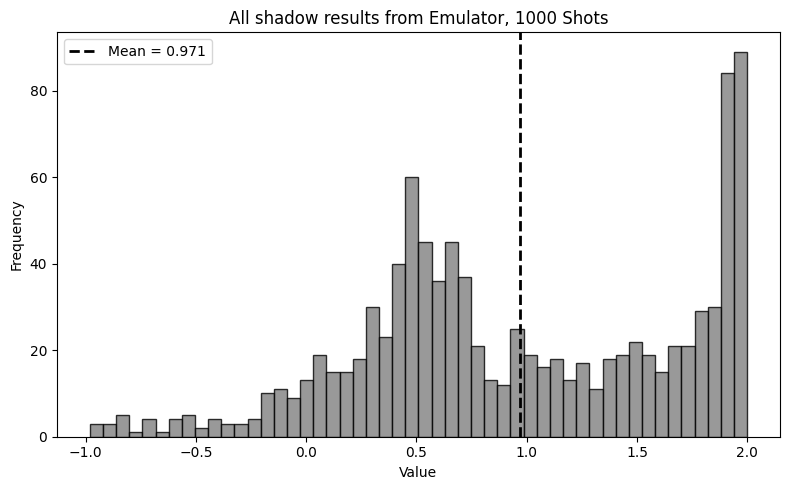

In [91]:
all_shadow_results_emulated=shadow_results_all_2 +shadow_results_0_0 + shadow_results_0_1 +shadow_results_1_0 + shadow_results_1_1 +shadow_results_2_0 + shadow_results_2_1 +shadow_results_3_0 + shadow_results_3_1 +shadow_results_4_0 + shadow_results_4_1 +shadow_results_5_0 + shadow_results_5_1 +shadow_results_6_0 + shadow_results_6_1 +shadow_results_7_0 + shadow_results_7_1 +shadow_results_8_0 + shadow_results_8_1 +shadow_results_9_0 + shadow_results_9_1 +shadow_results_10_0 + shadow_results_10_1 +shadow_results_11_0 + shadow_results_11_1 +shadow_results_12_0 + shadow_results_12_1
# ---- Histogram Plot ----
mean= np.mean(all_shadow_results_emulated)

# ---- plotting ----
plt.figure(figsize=(8,5))

# histogram (grey bars with black edges)
plt.hist(
    all_shadow_results_emulated,
    bins=50,
    color='grey',
    edgecolor='black',
    alpha=0.8
)

# mean line (black dashed)
plt.axvline(
    mean,
    color='black',
    linestyle='--',
    linewidth=2,
    label=f"Mean = {mean:.3f}"
)
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title(
    "All shadow results from Emulator, 1000 Shots"
)
plt.legend()
plt.tight_layout()
plt.show()

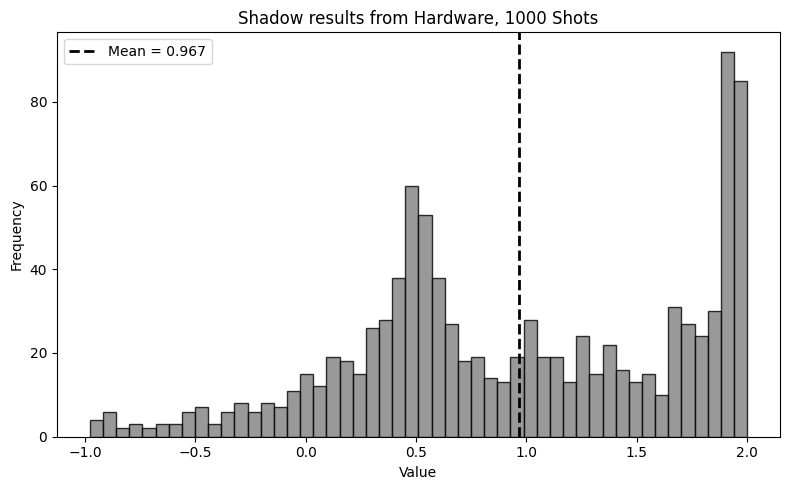

In [92]:
all_shadow_results_hardware = (shadow_results_all_2_h+
    shadow_results_0_0_h
    + shadow_results_0_1_h
    + shadow_results_1_0_h
    + shadow_results_1_1_h
    + shadow_results_2_0_h
    + shadow_results_2_1_h
    + shadow_results_3_0_h
    + shadow_results_3_1_h
    + shadow_results_4_0_h
    + shadow_results_4_1_h
    + shadow_results_5_0_h
    + shadow_results_5_1_h
    + shadow_results_6_0_h
    + shadow_results_6_1_h
    + shadow_results_7_0_h
    + shadow_results_7_1_h
    + shadow_results_8_0_h
    + shadow_results_8_1_h
    + shadow_results_9_0_h
    + shadow_results_9_1_h
    + shadow_results_10_0_h
    + shadow_results_10_1_h
    + shadow_results_11_0_h
    + shadow_results_11_1_h
    + shadow_results_12_0_h
    + shadow_results_12_1_h
)
# ---- Histogram Plot ----
mean= np.mean(all_shadow_results_hardware)

# ---- plotting ----
plt.figure(figsize=(8,5))

# histogram (grey bars with black edges)
plt.hist(
    all_shadow_results_hardware,
    bins=50,
    color='grey',
    edgecolor='black',
    alpha=0.8
)

# mean line (black dashed)
plt.axvline(
    mean,
    color='black',
    linestyle='--',
    linewidth=2,
    label=f"Mean = {mean:.3f}"
)
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title(
    "Shadow results from Hardware, 1000 Shots"
)
plt.legend()
plt.tight_layout()
plt.show()

What is interesting about this is that you can see all the different contributions from the different basis. The lump in the middle is from the all comp basis.

# Classically Simulated Workflow Simulaiton + Testing wrong shadow overlap

In [1]:
import numpy as np
import quimb as qu
import quimb.tensor as qtn
import matplotlib.pyplot as plt

def get_classical_shadow(circ, num_qubits):
    """
    Given a Quimb circuit, puts collection of classical shadow snapshots. Tbh idk if circuit is the best input, could be worth changing to a state vector input or something else it will have to run the whole circuit every time!
    
    Args:
        circuit: A circuit that returns a qtn.Circuit
        shadow_size (int): Number of snapshots.
        num_qubits (int): Number of qubits in the circuit.
        
    Returns:
        Tuple:????
            outcomes: array of shape (shadow_size, num_qubits) with measurement outcomes (-1,1)
            unitary_ids: array of shape (shadow_size, num_qubits) with sampled Pauli indices (0=X,1=Y,2=Z)
    """
    # Pauli unitaries in Quimb
    paulis = ['X', 'Y', 'Z']
    
    # Sample random Pauli measurements for each qubit
    unitary_ids = np.random.randint(0, 3, size=(num_qubits))
    for q in range(num_qubits):
        P = paulis[unitary_ids[q]]
        if P == 'X':
            circ.apply_gate('H', q)            # H maps X->Z
        elif P == 'Y':
            circ.apply_gate('Sdg', q)          # Sdg (S dagger) then H maps Y->Z
            circ.apply_gate('H', q)
        # P == 'Z' → do nothing
            
    # Measure each qubit in Z basis (simulate)
    state = circ.psi.to_dense()
    probs = np.abs(state)**2  # probabilities of each computational basis bitstring
    # Pick one bitstring at random according to these probabilities
    idx = np.random.choice(len(probs.flatten()), p=probs.flatten())
    # Convert the index to a bitstring, then to ±1
    bitstring = np.binary_repr(idx, width=num_qubits)
    bitlist = np.array([int(b) for b in bitstring])
    outcome = 1 - 2*bitlist  # 0 → +1, 1 → -1
    
    #Dont know if actually need a circuit here!
    return circ, outcome, unitary_ids

#We can undo per qubit as we did one qubit gates for random unitary ensemble, so this one qubit at at time thing works.
def projector_from_outcome(outcome):
    #seems to match the numbering system of 1=0, -1=1
    if outcome == 1:
        return np.array([[1, 0],
                         [0, 0]], dtype=complex)
    else:
        return np.array([[0, 0],
                         [0, 1]], dtype=complex)
def rotation_unitary(pauli):
    if pauli == 0:   # X
        return qu.hadamard()
    elif pauli == 1: # Y
        return qu.hadamard() @ qu.phase_gate( np.pi/2)
    elif pauli == 2: # Z
        return np.eye(2)

def single_qubit_shadow(outcome, pauli_id):
    Pz = projector_from_outcome(outcome)
    U = rotation_unitary(pauli_id)
    P = U.conj().T @ Pz @ U
    return 3 * P - np.eye(2)

def snapshot_density_matrix(outcomes, unitary_ids):
    rho_hat = single_qubit_shadow(outcomes[0], unitary_ids[0])
    for i in range(1, len(outcomes)):
        rho_i = single_qubit_shadow(outcomes[i], unitary_ids[i])
        rho_hat = np.kron(rho_hat, rho_i)
    return rho_hat

def run_single_shadow(circ,num_qubits,verbose: bool=True):

    #Take a classical shadow of the current circuit
    circ, outcome, unitary_ids=get_classical_shadow(circ,num_qubits)
    if verbose:
        print("SHADOW TAKEN!")
        print("Circuit is:")
        if len(circ.gates) > 0:
            circ.draw()
        else:
            print("Circuit is empty, nothing to draw")
        print("Unitaries are:",unitary_ids)
        print("Outcome is: ",outcome)

    if verbose:
        print("Reconstructing Shadow...")
    shadow_density_matrix=snapshot_density_matrix(outcome,unitary_ids)
    return shadow_density_matrix

def run_multiple_shadows(circ_builder,num_qubits,num_shadows,verbose: bool=True):
    '''The main shadow collecter to get a shadow set.
    Needs a...
    1) circ_builder function that create a circuit from which the final state can be estimated using shadows
    2) num_qubits for the circuit
    3) num_shadows for how many shadows need to be generated
    '''
    shadow_set=[]
    for i in range(num_shadows):
        circ=circ_builder(num_qubits)
        shadow_density_matrix=run_single_shadow(circ,num_qubits,verbose=verbose)
        shadow_set.append(shadow_density_matrix)

    return shadow_set

def identity_circ_builder(num_qubits):
    return qtn.Circuit(num_qubits)

def get_fidelity_estimates(targ_density_matrix,circ_builder,num_qubits,num_shadows,num_chunks,verbose: bool=False):
    '''Will get a list of fidelity estimates. Arguments are
    1) a target density matrix which shadow estimates are compared to
    2) a circ builder function that creates the state prep circuit (eg with the SCS algorithm parameters)
    3) number of qubits of the  circuit
    4) number of classical shadows that need to be taken
    5) num_chunks for median of means method
    
    Returns
    1) fidelity list of all fidelities from estimate
    2) a median of means approx '''
    if verbose:
        print("--------Retriving ",num_shadows, " classical shadows--------------")
    shadow_set=run_multiple_shadows(circ_builder,num_qubits,num_shadows,verbose=verbose)
    if verbose:
        print("--------Retrived ",num_shadows, " classical shadows--------------")

    #Now will make a list of all fidelity estimates
    fidelity_estimates=[]
    for i in range(len(shadow_set)):
        estimated_fid_to_target=np.real(np.trace(targ_density_matrix @ shadow_set[i]))
        fidelity_estimates.append(estimated_fid_to_target)
    
    #Get the median of means of specified number of chunks
    estimated_fideleity=median_of_means(fidelity_estimates, num_chunks)

    return fidelity_estimates,estimated_fideleity
import numpy as np

#ALTERNATE METHOD, I THINK USED IN THE PAPER THAT GETS THE MEDIAN OF MEANS OF THE DENSITY MARTIX RATHER THAN OF THE FIDELITIES
def get_fidelity_estimates_2(targ_density_matrix,circ_builder,num_qubits,num_shadows,num_chunks,verbose: bool=False):
    '''Will get a list of fidelity estimates. 
    THIS ONE DOES THE MEAN MATRICIES IN BATCHES, THEN FINDS FIDELITY FROM THEM, THEN DOES MEAN
    Arguments are
    1) a target density matrix which shadow estimates are compared to
    2) a circ builder function that creates the state prep circuit (eg with the SCS algorithm parameters)
    3) number of qubits of the  circuit
    4) number of classical shadows that need to be taken
    5) num_chunks for median of means method
    
    Returns
    1) fidelity list of all fidelities from estimate
    2) a median of means approx '''
    if verbose:
        print("--------Retriving ",num_shadows, " classical shadows--------------")
    shadow_set=run_multiple_shadows(circ_builder,num_qubits,num_shadows,verbose=verbose)
    if verbose:
        print("--------Retrived ",num_shadows, " classical shadows--------------")
    batched_shadow_set=batch_mean_density_matrices(shadow_set,num_batches=num_chunks)
    #Now will make a list of all fidelity estimates
    fidelity_estimates=[]
    for i in range(len(batched_shadow_set)):
        estimated_fid_to_target=np.real(np.trace(targ_density_matrix @ batched_shadow_set[i]))
        fidelity_estimates.append(estimated_fid_to_target)
    

    return fidelity_estimates, np.median(fidelity_estimates)
import numpy as np

import numpy as np

def batch_mean_density_matrices(shadow_set, num_batches):
    """
    Split density matrices into batches and compute the mean of each batch.
    """
    shadow_set = list(shadow_set)
    N = len(shadow_set)

    if num_batches > N:
        raise ValueError("num_batches cannot exceed number of matrices")

    batches = np.array_split(shadow_set, num_batches)

    batch_means = [
        sum(batch) / len(batch)
        for batch in batches
    ]

    return batch_means


def median_of_means(values, num_chunks=5):
    """
    Robust estimate using median-of-means.
    
    Args:
        values: list of floats (can be np.float64)
        num_chunks: int, how many chunks to split into
        
    Returns:
        float: median of the chunk means
    """
    # convert to numpy array if not already
    values = np.array(values, dtype=float)
    # split into roughly equal chunks
    chunks = np.array_split(values, num_chunks)
    # compute mean of each chunk
    chunk_means = [np.mean(chunk) for chunk in chunks]
    # return median of the means
    return np.median(chunk_means)


In [2]:
#Functions for making target density matricies
def hadamard_first_qubit_density_matrix(n):
    dim = 2**n
    ket = np.zeros(dim, dtype=complex)
    ket[0] = 1 / np.sqrt(2)
    ket[2**(n-1)] = 1 / np.sqrt(2)  # |1 0 ... 0>
    return np.outer(ket, ket.conj())
def ghz_density_matrix(n):
    dim = 2**n
    ket = np.zeros(dim, dtype=complex)
    ket[0] = 1 / np.sqrt(2)
    ket[dim - 1] = 1 / np.sqrt(2)
    return np.outer(ket, ket.conj())

def hadamard_density_matrix(n):
    dim = 2**n
    
    # |+...+>
    ket_plus = np.ones(dim, dtype=complex) / np.sqrt(dim)
    
    # rho = |+...+><+...+|
    rho = np.outer(ket_plus, ket_plus.conj())
    return rho
def zero_state_density_matrix(n):
    dim = 2**n
    
    # |0...0>
    ket0 = np.zeros(dim, dtype=complex)
    ket0[0] = 1.0
    
    # rho = |0><0|
    rho = np.outer(ket0, ket0.conj())
    return rho


In [3]:
import quimb.tensor as qtn
import quimb as qu
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from math import cos, sin, pi
from autoray import do
from scipy.linalg import qr, null_space
from typing import Dict, List, Tuple, Optional
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UnitaryGate
from collections import Counter
import autoray as ar
import jax.numpy as jnp
from skimage import data
from skimage.transform import resize
from scipy.stats import unitary_group
#import geoopt
#import geotorch
import math
import torch
import torch.nn as nn
from torch.nn.utils import parametrize

from functools import partial

'''This is the contraction method for the tensor networks ie For all future tensor contractions, automatically search for a high-quality contraction path (using a slower but smarter optimizer), so that contractions run efficiently on large networks '''
qtn.set_contract_strategy('auto-hq')

import mps_to_circuit as mtc
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator


''' This allows us to get the information from the qiskit circuit '''
def get_qiskit_gate_info(qc: QuantumCircuit):
    """
    Given a QuantumCircuit, returns a list of tuples:
    (gate_name, qubit_indices, gate_matrix)
    """
    gates = []
    for ci in qc.data:                      # ci is a CircuitInstruction
        instr = ci.operation                # was: instr
        qargs = ci.qubits                   # was: qargs
        qubits = [qc.find_bit(q).index for q in qargs]

        try:
            U = Operator(instr).data
            gates.append((instr.name, qubits, U))
        except Exception as e:
            # Skip non-unitary operations (measure, reset, barrier)
            print(f"Skipping {instr.name} on qubits {qubits}: {e}")

    return gates


'''Ensures the indicies of the TN are lrp'''
def ensure_mps_shape_lrp(mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Return a copy of `mps` whose site tensors have a consistent axis order:
      - interior sites: (vL, vR, p)
      - left edge:      (vR, p)
      - right edge:     (vL, p)

    This is the default 'lrp' format used by quimb.
    """
    mps = mps.copy()
    N = mps.L

    for i in range(N):
        T = mps[i]
        p = mps.site_ind(i)
        # all non-physical indices on this site
        virt = [ix for ix in T.inds if ix != p]

        if i == 0:
            # left edge: single virtual = vR
            assert len(virt) == 1, f"Site {i} expected 1 virtual leg, found {len(virt)}."
            vR = virt[0]
            T.transpose(vR, p, inplace=True)

        elif i == N - 1:
            # right edge: single virtual = vL
            assert len(virt) == 1, f"Site {i} expected 1 virtual leg, found {len(virt)}."
            vL = virt[0]
            T.transpose(vL, p, inplace=True)

        else:
            # interior: two virtuals; identify left vs right by neighbor sharing
            assert len(virt) == 2, f"Site {i} expected 2 virtual legs, found {len(virt)}."
            left_neighbor_inds = set(mps[i - 1].inds)
            right_neighbor_inds = set(mps[i + 1].inds)

            # the bond shared with the left/right neighbor
            vL = next(ix for ix in virt if ix in left_neighbor_inds)
            vR = next(ix for ix in virt if ix in right_neighbor_inds)

            T.transpose(vL, vR, p, inplace=True)

    return mps


'''Make the circuit in qiskit then map to quimb'''
def mps_to_circuit_quimb(mps: qtn.MatrixProductState) -> qtn.Circuit:
    """ Functionality thanks to https://github.com/qiskit-community/mps-to-circuit. MPS must have shape (vL,vR, phys) unless shape is specified. """
    
    psi = ensure_mps_shape_lrp(mps.copy())
    psi.left_canonicalize(inplace=True)

    arrays = [np.asarray(A, dtype=np.complex128) for A in psi.arrays]

    qiskit_qc = mtc.mps_to_circuit(arrays, shape='lrp',method='exact')

    gates_info = get_qiskit_gate_info(qiskit_qc)

    qc = qtn.Circuit(mps.L)
   
    for gate in gates_info:
        name, qubits, U = gate
        qubits.reverse()
        qc.apply_gate(U, *qubits)

    return qc

"""def optimise_to_zero(n: int,eps: float = 1e-2):
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    
    to_opt = qc.uni

    targ_qc = qtn.Circuit(n)
    I4 = qu.eye(4)  # two-qubit identity (4×4)
    for i in range(n - 1): targ_qc.apply_gate(I4, i, i + 1, tags=['SU4'])
    targ_uni = targ_qc.uni 

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ_uni},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14)
    #opt_uni = tnopt.optimize_basinhopping(n=600,tol=1e-14,nhop=100)

    params = opt_uni.get_params()

    return params"""


'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_identity(eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(np.eye(4).reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation

    params = opt_uni.get_params()

    return params


'''Gives the paramters of a complete unity circuit not just a gate'''
def optimise_to_zero(n: int,eps: float = 1e-2):
    params = optimise_su4_gate_to_identity(eps=eps)[2]
        
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        qc.apply_gate("SU4",*(params),idx,idx+1,tags=["SU4"],parametrize=True)
    
    circ_uni = qc.uni
    params = circ_uni.get_params()

    return params


'''Gives the parameterised identity circ'''
def near_zero_parametrized_circ_layer(n: int, eps: float = 1e-3):
    """ Create a single-layer SU(4) parametrised quantum circuit, initialised near-identity """

    #params = optimise_to_zero(n)
    params = GLOBAL_IDENTITY_LAYER_PARAMS ###--what is this????
    qc = qtn.Circuit(n)
    #for idx in range(n-1):
    for idx, base in zip(range(n - 1), params.values()):
        base = np.asarray(base, dtype=float).reshape(15)
        qc.apply_gate("SU4",*(base+eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    return qc

'''Using the optimised identity params this becomes an idenity circuit layer'''
def parametrized_circ_layer(n: int, params: np.ndarray, eps: float = 1e-3):
    """ Create a single-layer SU(4) parametrised quantum circuit, initialised with params. """
    qc = qtn.Circuit(n)
    for idx, base in zip(range(n - 1), params.values()):
        base = np.asarray(base, dtype=float).reshape(15)
        qc.apply_gate("SU4",*(base+eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    return qc


'''Computes the Schmidt coefficients (or their squares, i.e. entanglement spectrum) for a bipartition of a quantum state, given the left and right Gram matrices'''
'''def schmidt_from_gram(L,R,square: bool = True, cut_zeros: bool = True) -> torch.Tensor:
    L = (L + L.conj().T) / 2
    R = (R + R.conj().T) / 2

    # 2) eigensqrt of L
    w, U = torch.linalg.eigh(L)
    w = torch.clip(w, 0, None)
    Lh = (U * torch.sqrt(w)[None, :]) @ U.conj().T

    # 3) build A and solve
    A = Lh @ R @ Lh
    A = (A + A.conj().T) / 2
    mu = torch.linalg.eigvalsh(A)
    mu = torch.clip(mu.real, 0, None)

    # Schmidt coefficients
    s = torch.sqrt(mu).flip(0)

    if square:
        s = s**2

    if cut_zeros:
        s = s[s > 1e-14]
        
    return s'''
import torch
from typing import Tuple, Optional

def schmidt_from_gram(
    L: torch.Tensor,
    R: torch.Tensor,
    square: bool = True,
    cut_zeros: bool = True,
    *,
    eps_abs: float = 1e-16,
    eps_rel: float = 1e-12,
    cond_limit: float = 1e10,
    jitter: float = 1e-8,
    return_info: bool = False,
) -> torch.Tensor:
    """
    Compute Schmidt coefficients from Gram matrices L, R in a numerically robust way.

    L, R: (..., N, N) complex or real tensors. Supports batching.
    eps_abs: absolute minimum eigenvalue (very tiny floor).
    eps_rel: relative floor as a fraction of the max eigenvalue per matrix.
    cond_limit: maximum allowed condition number ~ max_eig / min_allowed_eig.
                If cond_limit is finite, min_allowed_eig = max(max_eig/cond_limit, eps_rel*max_eig, eps_abs)
    jitter: extra additive jitter to the diagonal (useful to force PD for cholesky; typically 0).
    return_info: if True returns (s, info_dict) where info_dict contains diagnostics.

    Returns:
      s: Schmidt coefficients (descending), optionally squared if square=True and filtered if cut_zeros=True.
    """
    # 0) basic checks and symmetrize
    if L.shape[-2] != L.shape[-1] or R.shape[-2] != R.shape[-1]:
        raise ValueError("L and R must be square matrices (..., N, N).")
    if L.shape[-2] != R.shape[-2]:
        raise ValueError("L and R must be same size.")
    if not torch.isfinite(L).all() or not torch.isfinite(R).all():
        raise ValueError("L or R contains NaN/Inf.")
    
    # Hermitize (works for complex data too)
    herm = lambda X: (X + X.conj().transpose(-2, -1)) / 2
    L = herm(L)
    R = herm(R)

    # Optionally add tiny jitter first (keeps reconstruction stable)
    if jitter > 0:
        N = L.shape[-1]
        eye = torch.eye(N, device=L.device, dtype=L.dtype)
        L = L + jitter * eye

    # eigendecompose L
    # PREVIOUS 06/11
    '''w, U = torch.linalg.eigh(L)   # w: (..., N) ascending order by torch convention

    # diagnostics
    max_w = w.amax(dim=-1, keepdim=True)   # (..., 1)
    max_w_safe = torch.clamp(max_w, min=1e-30)  # avoid divide-by-zero
    # compute allowed minimum eigenvalue per matrix (batched)
    min_allowed = torch.maximum(
        torch.full_like(max_w_safe, eps_abs),
        torch.maximum(eps_rel * max_w_safe, max_w_safe / cond_limit)
    )  # (..., 1)

    # clamp eigenvalues (relative threshold)
    w_clamped = torch.clamp(w, min=min_allowed.squeeze(-1))

    # optional info
    num_clamped = (w < w_clamped).to(torch.int64).sum(dim=-1)  # count per batch
    frac_clamped = num_clamped.to(torch.get_default_dtype()) / w.shape[-1]

    # build sqrt(L) = U diag(sqrt(w_clamped)) U^†
    sqrt_w = torch.sqrt(w_clamped)
    # broadcasting: (.., N) -> (.., 1, N) for left-multiplication on U
    Lh = (U * sqrt_w.unsqueeze(-2)) @ U.conj().transpose(-2, -1)


    # construct A and symmetrize
    A = Lh @ R @ Lh
    A = herm(A)'''

    # ----- NEW: Cholesky-based "square root" (no eigenvectors; phase-safe) -----
    # We already hermitized L above and added optional jitter.
    # Make sure L is PD enough for Cholesky by adapting jitter if needed.
    def chol_with_adaptive_jitter(M: torch.Tensor, base_jitter: float):
        N = M.shape[-1]
        eye = torch.eye(N, device=M.device, dtype=M.dtype)
        jitter = base_jitter
        for _ in range(6):  # try a few times, up to ~1e-6 if starting at 1e-12
            try:
                return torch.linalg.cholesky(M + (jitter * eye)), jitter
            except RuntimeError:
                jitter = max(jitter * 10.0, 1e-12) if jitter > 0 else 1e-12
        # final attempt with cholesky_ex to get info
        C, info = torch.linalg.cholesky_ex(M + (jitter * eye))
        if (info > 0).any():
            raise RuntimeError("Cholesky failed: L not PD even after jitter.")
        return C, jitter

    C, used_jitter = chol_with_adaptive_jitter(L, jitter)

    # Build A = C^H R C (Hermitian if R is Hermitian); this is
    # unitarily similar to L^{1/2} R L^{1/2} so it has the same eigenvalues.
    A = C.conj().transpose(-2, -1) @ R @ C
    A = (A + A.conj().transpose(-2, -1)) / 2  # re-hermitize numerically

    # eigenvalues of A (real, ascending)
    mu = torch.linalg.eigvalsh(A)
    # numerical safety: clamp small negatives to zero
    mu = torch.clip(mu.real, 0.0, None)

    # Schmidt coefficients: sqrt(mu) in descending order
    s = torch.sqrt(mu).flip(-1)

    if square:
        s = s**2

    if cut_zeros:
        # flatten last dimension and cut tiny entries
        # we'll return per-batch concatenated tensors, so handle batch case by converting to list
        out_list = []
        if s.ndim == 1:
            out_list = [s[s > 1e-14]]
        else:
            # batch handling: return a list of 1D tensors (one per batch)
            # but to keep same return type as before (tensor) we'll concatenate if batch size == 1,
            # otherwise return list if multiple batches (safer).
            batch_shape = s.shape[:-1]
            s_reshaped = s.reshape(-1, s.shape[-1])  # (B, N)
            for row in s_reshaped:
                out_list.append(row[row > 1e-14])
            if s_reshaped.shape[0] == 1:
                s = out_list[0]
            else:
                # when multiple batches present, return a list of tensors (doable) or pad to rectangular array.
                # Here we return a list for explicitness.
                if return_info:
                    info = {
                        "num_clamped": num_clamped,
                        "frac_clamped": frac_clamped,
                        "w_max": max_w.squeeze(-1),
                        "min_allowed": min_allowed.squeeze(-1),
                    }
                    return out_list, info
                return out_list

    if return_info:
        info = {
            "num_clamped": num_clamped,
            "frac_clamped": frac_clamped,
            "w_max": max_w.squeeze(-1),
            "min_allowed": min_allowed.squeeze(-1),
        }
        return s, info

    return s


'''Contruct the left and right contracted tensors so we are only looking at the required bypartition'''
def construct_L_R_Gram_matrices(tn: qtn.TensorNetwork, ind: str, *, device=None, dtype=None) -> qtn.TensorNetwork:
    """ Construct L_a,a' and R_a,a' Gram matrices. """
    ket = tn.copy()
    bra = ket.copy().conj()
    bra.reindex_({i: i + '_bra' for i in bra._inner_inds})

    comb = (bra|ket)

    #Find relevant tags of border tensors
    tidL, tidR = comb.ind_map[ind]
    L_tag = [tag for tag in comb.tensor_map[tidL].tags if tag.startswith('I')]
    R_tag = [tag for tag in comb.tensor_map[tidR].tags if tag.startswith('I')]
    if len(L_tag)!=1 or len(R_tag)!=1:
        print(comb)
        print(L_tag)
        print(R_tag)
    assert len(L_tag)==1 and len(R_tag)==1, "Tensors in combined TN should have unique identifying tag"
    L_tag = L_tag[0]
    R_tag = R_tag[0]

    L_tag_id = int(str(L_tag[1:]))
    R_tag_id = int(str(R_tag[1:]))

    L_tag = f'I{min(L_tag_id,R_tag_id)}'
    R_tag = f'I{max(L_tag_id,R_tag_id)}'
    assert R_tag_id > L_tag_id, "Right border unique tag should be greater than the left border unique tag"

    L_tags = [tag for T in comb
              for tag in T.tags 
              if isinstance(tag,str) and tag.startswith('I') and int(tag[1:])<=L_tag_id]
            
    R_tags = [tag for T in comb
              for tag in T.tags 
              if isinstance(tag,str) and tag.startswith('I') and int(tag[1:])>=R_tag_id]
    
    #Form subnetworks and contract
    L_subnetwork = comb.select(L_tags,which='any')
    R_subnetwork = comb.select(R_tags,which='any')

    output_inds = (ind, ind+'_bra')
    L_contracted = L_subnetwork.contract(all,output_inds=output_inds,backend='torch')
    R_contracted = R_subnetwork.contract(all,output_inds=output_inds,backend='torch')

    L_mat = L_contracted.data
    R_mat = R_contracted.data

    return L_mat, R_mat


'''Cumulated the above two functions as to find the scmidt coeffs'''
'''def schmidt_coeffs_from_ind(tn: qtn.TensorNetwork, ind:str):
    L_mat,R_mat = construct_L_R_Gram_matrices(tn,ind)
    s = schmidt_from_gram(L_mat,R_mat)
    return s'''

def schmidt_coeffs_from_ind(tn: qtn.TensorNetwork, ind:str):
    L_mat,R_mat = construct_L_R_Gram_matrices(tn,ind)
    # 2) Compute Schmidt coefficients using safe numerical parameters
    s = schmidt_from_gram(
        L_mat,
        R_mat,
        square=True,
        cut_zeros=True,
        eps_abs=1e-16,     # absolute floor
        eps_rel=1e-12,     # relative floor
        cond_limit=1e10,   # cap condition number
        jitter=1e-12,      # tiny diagonal regularization
        return_info=False, # only return s
    )
    return s



'''Is the code to apply the circuit to the mps ie does the contractions'''
def apply_single_layer(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState, gauge: bool = False) -> qtn.MatrixProductState:
    """
    Apply a single layer of 2-qubit unitaries to evolve an MPS.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    #print(new)
    #print(new.outer_inds())
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)

    for t in new:
        site_ind_idx = int([ind for ind in t.inds if ind.startswith('b')][0][1:])
        t.modify(tags = (f'I{site_ind_idx}'))

    if gauge:
        new.gauge_all(method='simple',inplace=True)
    
    """to_split = new.tensors[-1]
    num_phys = [i for i in to_split.inds if i.startswith('b')]
    if len(num_phys)>1:
        left_phys_idx = new.L-2
        virt = [i for i in to_split.inds if not i.startswith('b')][0]
        TL,TR = to_split.split(
            left_inds=(f'b{left_phys_idx}',virt),
            right_inds=(f'b{left_phys_idx+1}'),
            method='svd',
            absorb='both'
        )

        TL.add_tag(f"I{left_phys_idx}")
        TR.drop_tags()
        TR.add_tag(f"I{left_phys_idx+1}")
        new = qtn.TensorNetwork([new.tensors[:-1],TL,TR])
        new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)"""

    return new
    #return ensure_mps_shape_lrp(new)

'''This is the same functinality as the above but might do it in a slightly differnt way'''
def apply_single_layer_to_mps(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Apply a single layer of 2-qubit unitaries to evolve an MPS.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    bL = f'b{mps.L-2}'
    bR = f'b{mps.L-1}'
    T = next(T for T in new.tensors if bL in T.inds and bR in T.inds)
    virt, = [ind for ind in T.inds if ind not in (bL,bR)]
    
    kept = []
    for t in new:
        if bL not in t.inds and bR not in t.inds:
            kept.append(t)
    
    TL,TR = T.split(
        left_inds=(bL,virt),
        right_inds=(bR,),
        method='svd',
        absorb='right'
    )
    
    ordered_list = []
    idx = 0
    while idx < mps.L:
        for t in kept+[TL,TR]:
            for ind in t.inds:
                if ind[0]=='b':
                    id = int(ind[1:])
                    if idx == id:
                        ordered_list.append(t)
                        break
        idx+=1

    new = qtn.TensorNetwork(ordered_list)

    new.reindex({f'b{x}': f'k{x}' for x in range(mps.L)},inplace=True)
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
    
    for idx,t in enumerate(new):
        t.modify(tags=(f"I{idx}"))        
        if t.ndim==3:
            if f'k{new.L-2}' in t.inds:
                a,b,c = t.inds
                new_ind_ordering = (b,c,a)
                t.transpose(*new_ind_ordering, inplace=True)
            else:
                a,b,c = t.inds
                new_ind_ordering = (c,b,a)
                t.transpose(*new_ind_ordering, inplace=True)

    return new

def ordered_mps(tn: qtn.MatrixProductState):
    tn = tn.copy()
    tensors = []
    num_added = 0
    while num_added < tn.L:
        for t in tn:
            if f'k{num_added}' in t.inds:
                tensors.append(t)
                num_added+=1
                if f'k{num_added}' in t.inds:
                    num_added+=1
                break
    new = qtn.TensorNetwork(tensors)
    new.view_as(qtn.MatrixProductState, inplace=True, L=tn.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
    return new


'''This applies the adjoint of the circuit we give to the mps'''
def apply_single_layer_to_mps(circ_tn: qtn.Circuit, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """ 
    
    Contract a circuit layer MPO with an MPS, reshaping it into an MPS form.

    Provide the circuit for which the adjoint is applied.
    
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    #circ_tn.reindex({f'b{x}': f't{x}' for x in range(mps.L)},inplace=True)
    #circ_tn.reindex({f'k{x}': f'b{x}' for x in range(mps.L)},inplace=True)
    #circ_tn.reindex({f't{x}': f'k{x}' for x in range(mps.L)},inplace=True)

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)
    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    new.reindex({f'b{x}': f'k{x}' for x in range(mps.L)},inplace=True)
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)

    if new.max_bond()==1:
        return new
    
    new.full_simplify(seq='ADCR',atol=0.0,inplace=True)
    
    new = ordered_mps(new)
    
    current_idx = 0
    last_tensor_inds = ()
    while current_idx < new.L:
        T = new.tensors[current_idx].copy()

        phys_inds = np.array([i for i in T.inds if i[0]=='k'])

        if len(phys_inds) == 1:
            last_tensor_inds = T.inds
            current_idx+=1 
            continue

        current_phys = f'k{current_idx}'
        left_inds = [i for i in T.inds if i in last_tensor_inds]
        left_inds = tuple(left_inds + [current_phys])

        if current_idx == mps.L-2:
            left_inds = tuple([i for i in T.inds if i != f'k{current_idx+1}'])
        
        right_inds = tuple([i for i in T.inds if i not in left_inds])
        
        #print(f'current phys = {current_phys}. left inds = {left_inds}. right inds = {right_inds}. All inds = {T.inds}. Prev inds = {last_tensor_inds}.')
        TL,TR = qtn.tensor_split(T, left_inds=left_inds, method='svd', absorb='left', cutoff=1e-14)

        new = qtn.TensorNetwork(new.tensors[:current_idx] + (TL,TR) + new.tensors[current_idx+1:])
        new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
                
        last_tensor_inds = left_inds
        current_idx+=1

    for t in new:
        for i in t.inds:
            if i[0]=='k':
                idx = i[1:]
        t.modify(tags = {f'I{idx}'})

    new.compress(cutoff=1e-16)
    new.left_canonicalize(inplace=True)

    new_inds = (new.tensors[-1].inds[1],new.tensors[-1].inds[0])
    new.tensors[-1].transpose(*new_inds,inplace=True)
    new = ensure_mps_shape_lrp(new)

    return new


'''THis functions shows the fidelity of a chi = bond approximation of the MPS'''
def test_bond_accuracy(tn,bond):
    tn = tn.copy()
    x = tn.copy()
    x.compress(max_bond=bond)
    x/=x.norm()
    return abs((x.conj() | (tn / tn.norm())).contract(all))**2


'''ALLL BELOW ARE SOME LOSS FUNCTION EXAMPLES******************************************'''

'''This function defines the loss function for the optimisation of layers, op = circuit, intit_tn = intial mps'''
'''def torch_schmidt_loss_fn(op: qtn.TensorNetwork, init_tn: qtn.MatrixProductState, target_bond_dim: int = 1, gamma: float = 4.0, alpha: float = 0.2) -> torch.Tensor:
    """
    C(lambda) = sum(w_i*lambda_i) + alpha (1 - sum(lambda_i^2)) + beta * RELU(m - (lambda_D - lambda_(D+1))) = tail mass + alpha*linear entropy + beta*gap penalty. w_i = (i-D)^gamma. D = target_bond_dim.
    """
    init_tn = init_tn.copy()
    op = op.copy()
    #op.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)#here we contact the mps with the circuit
    
    vals = []
    for ind in new_tn.inner_inds():
        schmidt_coeffs = schmidt_coeffs_from_ind(new_tn,ind)

        tail = schmidt_coeffs[target_bond_dim:] #/ torch.sum(schmidt_coeffs[target_bond_dim:])
        idx = torch.arange(1, tail.numel()+1, device=schmidt_coeffs.device, dtype=schmidt_coeffs.dtype)
        weights = idx**gamma

        C_tail_mass = (weights * tail).sum()
        #C_lin_entropy = 1.0 - (schmidt_coeffs**2).sum()

        loss = C_tail_mass #+ alpha*C_lin_entropy
        vals.append(loss)

    vals = torch.stack(vals)

    return vals.sum()'''

'''This is the entanglement as the loss function'''
'''def torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.0
) -> torch.Tensor:
    """
    Net entanglement loss = sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = (lambda_i)^2 / sum_k (lambda_k)^2
    Optional: + alpha * (1 - sum_i p_i^2) per cut (linear entropy smoothing).
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    eps = torch.finfo(torch.float64).tiny  # ~2e-308
    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)   # λ_i ≥ 0
        p = p / (p.sum() + eps)                                        # normalize
        Sj = -(p * torch.log2(p.clamp_min(1e-12))).sum()               # bits

        if g > 0.0:
            Tj = 1.0 - (p[0] + p[1] + p[2] + p[3]) ###FIND ME HERE #Immediate compressibility proxy
            Cj = (1.0-g)*Sj + g*Tj
        else:
            Cj = Sj

        vals.append(Cj)
    vals = torch.stack(vals)
    return vals.sum() 

import math'''

def torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.0
) -> torch.Tensor:
    """
    Net entanglement loss = sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = (lambda_i)^2 / sum_k (lambda_k)^2
    Optional: + alpha * (1 - sum_i p_i^2) per cut (linear entropy smoothing).
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    eps = 1e-12
    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)   # λ_i ≥ 0, p_i =  λ_i^2
        
        d = p.numel()
        if d== 0:
            continue
        p = torch.clamp(p, min=0.0)

        p = p / p.sum()

        # --- Entropy (use change-of-base to avoid log2 instability under AMP) ---
        Sj = - (p * (p.log() / math.log(2.0))).sum()
        
        #ADDED NORMALISATION
        #if d>1:
        #    S_max = math.log2(d)
        #    Sj = Sj / S_max #normalise in [0,1] 

        #Sj = -(p * torch.log2(p.clamp_min(1e-12))).sum()               # bits

        if g > 0.0: #1-(p_1^2+p_2^2) 
            #print(len(p))
            #print(p.numel())
            topk = min(2, p.numel())
            Tj = 1.0 - p.narrow(0, 0, topk).sum()
            Cj = (1.0 - g) * Sj + g * Tj
        else:
            Cj = Sj

        vals.append(Cj)
    vals = torch.stack(vals)
    return vals.sum()

def new_torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.5,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-parameter loss aligned with final chi=2 fidelity.

    For each internal bond, let p be the normalised Schmidt probabilities
    (lambda^2 / sum lambda^2), sorted in descending order.

      T_j      = 1 - (p_1 + p_2)                   # tail mass (chi=2 infidelity)
      r_i      = p_i / T_j for i >= 3             # tail distribution (if T_j > 0)
      H_tail   = -sum_{i>=3} r_i log2 r_i         # entropy of tail
      H_tail_n = H_tail / log2(d_tail) in [0,1]   # d_tail = len(tail), if >= 2

    Per-cut cost:
      C_j(g) = T_j * (1 + g * H_tail_n)

    - T_j drives you towards high chi=2 fidelity.
    - H_tail_n only cares about *how messy the tail is*.
    - g in [0,1] controls how much you value "cleaning up / structuring the tail"
      vs purely greedy chi=2.

    When T_j -> 0, C_j -> 0 regardless of H_tail_n, so late stages are effectively greedy.
    """
    # clamp g to [0, 1]
    #g = float(max(0.0, min(1.0, g)))

    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        # λ^2 already
        lam2 = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if lam2.numel() == 0:
            continue

        lam2 = torch.clamp(lam2, min=0.0)
        Z = lam2.sum()
        if Z <= eps:
            continue

        p = lam2 / Z  # probabilities

        # sort so top entries are really the largest
        p_sorted, _ = torch.sort(p, descending=True)
        d = p_sorted.numel()

        if d <= 2:
            # no tail -> already rank<=2 across this cut
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue

        # chi=2 tail mass
        topk = 2
        Tj = 1.0 - p_sorted[:topk].sum()

        if Tj <= eps:
            # effectively no tail, cost ~ 0
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue

        tail = p_sorted[topk:]          # shape (d_tail,)
        d_tail = tail.numel()

        if d_tail <= 1:
            # a single tail mode still present: no entropy structure
            H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
        else:
            # tail distribution r_i = p_i / T_j
            r = tail / Tj
            r = torch.clamp(r, min=eps)

            H_tail = - (r * (r.log() / math.log(2.0))).sum()
            H_max = math.log2(d_tail)
            H_tail_norm = H_tail / H_max

        # multiplicative planning: penalise large & messy tails
        Cj = Tj * (1.0 + g * H_tail_norm)
        vals.append(Cj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)
    #if np.random.randint(0,200)==0:
    #   print(f'Tj = {Tj}, H_tail_n = {H_tail_norm}, Cj = {Cj}')
    vals = torch.stack(vals)
    return vals.sum()


def loss_renyi2_sum(op, init_tn):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    total = 0.0
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        total = total - torch.log2((p*p).sum().clamp_min(1e-300))  # Σ_j S2^(j)
    return total

def loss_smoothmax_entropy(op, init_tn, tau=0.1):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    vals = []
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        S = -(p * torch.log2(p.clamp_min(1e-12))).sum()
        vals.append(S)
    vals = torch.stack(vals)
    return tau * torch.logsumexp(vals / tau, dim=0)

def loss_weighted_tail(op, init_tn, D=4, gamma=1.0):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    tot = 0.0
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        tail = p[D:]
        if tail.numel():
            idx = torch.arange(1, tail.numel()+1, dtype=tail.dtype, device=tail.device)
            w = idx**gamma                     # gamma↑ => weight deeper tail more
            tot = tot + (w * tail).sum()
    return tot

def loss_effective_rank(op, init_tn, target_R=None, beta=1.0):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    vals = []
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        R = 1.0 / (p*p).sum().clamp_min(1e-300)
        vals.append(torch.log2(R))  # ≡ S2
        if target_R is not None:    # optional hinge to keep R below target
            vals.append(beta * torch.relu(torch.log2(R) - torch.log2(torch.tensor(target_R))))
    return torch.stack(vals).sum()



def cost_from_s(schmidt_coeffs):
    target_bond_dim = 2
    gamma = 4

    tail = schmidt_coeffs[target_bond_dim:] #/ torch.sum(schmidt_coeffs[target_bond_dim:])
    idx = torch.arange(1, tail.numel()+1, device=schmidt_coeffs.device, dtype=schmidt_coeffs.dtype)
    weights = idx**gamma

    C_tail_mass = (weights * tail).sum()
    #C_lin_entropy = 1.0 - (schmidt_coeffs**2).sum()

    loss = C_tail_mass #+ alpha*C_lin_entropy
    return loss

'''ALLL ABOVE ARE SOME LOSS FUNCTION EXAMPLES******************************************'''

'''Turns Torch backend to numpy backend'''
def to_numpy(a):
    # Works for both torch and numpy inputs
    if isinstance(a, torch.Tensor):
        return a.detach().cpu().numpy()
    return np.asarray(a)


def torch_schmidt_entropy_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
) -> torch.Tensor:
    """
    g = 0 part: sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = λ_i^2 / sum_k λ_k^2
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        d = p.numel()
        if d== 0:
            continue

        p = torch.clamp(p, min=0.0)
        p = p / p.sum()

        # Entropy in bits: S_j
        Sj = - (p * (p.log() / math.log(2.0))).sum()

        #if d>1:
        #    S_max = math.log2(d)
        #    Sj = Sj / S_max
        vals.append(Sj)

    vals = torch.stack(vals)
    print(vals)
    return vals.sum()

def torch_schmidt_entropy_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    g = 0 part: sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = λ_i^2 / sum_k λ_k^2

    Additionally (for diagnostics), prints the *normalised tail entropy* per cut,
    where the tail is everything beyond the top-2 Schmidt probabilities,
    and also prints a single scalar "new tail entropy term" = sum_j H_tail_n^{(j)}.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    entropies = []
    tail_entropies = []

    for ind in new_tn.inner_inds():
        # p are λ^2 already
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)
        d = p.numel()
        if d == 0:
            continue

        p = torch.clamp(p, min=0.0)
        Z = p.sum()
        if Z <= eps:
            continue
        p = p / Z  # probabilities

        # --- Net entropy S_j over full spectrum ---
        Sj = - (p * (p.log() / math.log(2.0))).sum()
        entropies.append(Sj)

        # --- Tail entropy part (for printing only) ---
        # Sort so "top-2" really means largest 2
        p_sorted, _ = torch.sort(p, descending=True)
        d_sorted = p_sorted.numel()

        if d_sorted <= 2:
            # no tail beyond chi=2
            H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
        else:
            topk = 2
            Tj = 1.0 - p_sorted[:topk].sum()  # tail mass
            if Tj <= eps:
                H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
            else:
                tail = p_sorted[topk:]
                d_tail = tail.numel()
                if d_tail <= 1:
                    H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
                else:
                    r = tail / Tj  # tail distribution
                    r = torch.clamp(r, min=eps)
                    H_tail = - (r * (r.log() / math.log(2.0))).sum()
                    H_max = math.log2(d_tail)
                    H_tail_norm = H_tail / H_max

        tail_entropies.append(H_tail_norm)

    if not entropies:
        print("No internal bonds found; tail entropy = []")
        return torch.tensor(0.0, dtype=torch.float64)

    entropies = torch.stack(entropies)
    tail_entropies = torch.stack(tail_entropies)

    # --- print the tail entropy diagnostics ---
    print("Tail entropy (normalised) per cut:",
          tail_entropies.detach().cpu().numpy())

    new_tail_entropy_term = tail_entropies.sum().item()
    print("New tail entropy term =", new_tail_entropy_term)

    return entropies.sum()



def torch_schmidt_tail_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    topk: int = 2,
) -> torch.Tensor:
    """
    g = 1 part: sum_j T^{(j)}, where
      T^{(j)} = 1 - sum_{i=1}^{topk} p_i^{(j)},
    with p_i as in the entropy loss.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if p.numel() == 0:
            continue

        p = torch.clamp(p, min=0.0)
        p = p / p.sum()

        k = min(topk, p.numel())
        Tj = 1.0 - p.narrow(0, 0, k).sum()
        vals.append(Tj)

    vals = torch.stack(vals)
    print(vals)
    return vals.sum()


def torch_schmidt_kl_rank2_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    alpha: float = 1e-3,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-term planning-friendly cost.

    For each internal bond, let p be the normalised Schmidt probabilities.
    Define a smoothed rank-2 target spectrum q:
        q_1 = q_2 = (1 - alpha)/2,
        q_i (i>=3) share total mass = alpha.

    Loss = sum_j D_KL(p^{(j)} || q^{(j)}).

    This consolidates:
      - entropy reduction (concentration of p),
      - tail suppression (penalising mass where q_i is tiny),
    into a single divergence to the 'ideal' chi=2 spectrum.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    # Apply one optimisation layer
    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        # λ_i >= 0  -> convert to probabilities
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if p.numel() == 0:
            continue

        # Numerical hygiene
        p = torch.clamp(p, min=0.0)
        Z = p.sum()
        if Z <= eps:
            continue
        p = p / Z

        d = p.numel()

        # Build target q
        if d <= 2:
            # If there is no tail, just aim for equal split
            q = torch.full_like(p, 0.5)
        else:
            tail_mass = float(alpha)
            tail_mass = max(min(tail_mass, 0.5), 0.0)  # safety clip

            q_top = (1.0 - tail_mass) / 2.0
            q_tail = tail_mass / float(d - 2)

            q = torch.full_like(p, q_tail)
            q[0] = q_top
            q[1] = q_top

        # Clamp for log stability
        p_safe = torch.clamp(p, min=eps)
        q_safe = torch.clamp(q, min=eps)

        # KL(p || q) in nats (constant factor doesn't matter for optimisation)
        Cj = (p_safe * (p_safe.log() - q_safe.log())).sum()
        vals.append(Cj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)

    vals = torch.stack(vals)
    return vals.sum()


'''THIS IS THE OPTIMISATION for a layer%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%'''
def optimise_circ_layer(init_mps: qtn.TensorNetwork, loss = torch_schmidt_loss_fn, verbose: bool = False, get_best_result: bool = True, gauge_iteratively: bool = False) -> qtn.TensorNetwork:
    init_mps = init_mps.copy()
    #init_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    
    
    circ = near_zero_parametrized_circ_layer(init_mps.L,1e-3)#intitialise our ciruit at identity
    layer = circ.uni #turn into tensor network form
    layer.apply_to_arrays(lambda x: torch.as_tensor(x)) #make sure torch backend
    to_opt = layer.copy()

    #new_tn = apply_single_layer(circ_tn=to_opt.copy(), mps=init_mps.copy(), gauge=False)
    #print('new mps outcome:')
    #t1 = new_tn.copy()
    #print(t1.contract(all,output_inds=[f'b{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
    #new_tn.draw(figsize=(15,15))
    #t = new_tn.tensors[-1]
    #t.add_tag("I7")
    """print(new_tn)
    for idx,ind in enumerate(new_tn.inner_inds()):
        print(f'ind: {ind} - {schmidt_coeffs_from_ind(new_tn.copy(),ind)}')
        #if idx < len(new_tn.inner_inds())-3:
        #    print(f'check: {new_tn.copy().schmidt_values(idx+1)}')
        print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(new_tn.copy(),ind))}')"""

    #init_mps.left_canonicalize(inplace=True,normalize=True)

    if verbose:
        with torch.no_grad():
            print(f'initial loss = {loss(to_opt,init_mps)}')

    if get_best_result: #essentially we are looking for the best parameters if this is true
        if verbose:
            print('Ensuring best parameters are retrieved...')

        _best = {"val": None, "params": None}

        with torch.no_grad():
            best_val = loss(to_opt,init_tn=init_mps)
        
        _best["val"] = best_val
        
        '''if this iteration is the best store the parameters and continue returing psi as it was inputted'''
        def get_best(psi):
            #global best_val,best_params
            with torch.no_grad():
                val = loss(psi,init_tn=init_mps)
            if val<_best["val"]:
                tn_np = psi.copy()
                tn_np.apply_to_arrays(to_numpy)
                _best["params"] = tn_np.get_params()
                _best["val"] = val
            return psi
        
        def get_best_fn(psi):
            with torch.no_grad():#Ensures that the operations inside do not track gradients in PyTorch ie does this outside the optimisation
                _ = get_best(psi.copy())#makes a separate copy of the tensor network so the bookkeeping doesn’t alter the main object.

                if gauge_iteratively:#boolean ie renormalsiation for stability
                    psi.gauge_all(method='simple',inplace=True)#a tensor network normalization/gauge-fixing step.“Simple” method ensures numerical stability of MPS contractions.Done inplace, modifying the original
            return psi

        print(f'At init net entropy comp = {torch_schmidt_entropy_loss(to_opt.copy(),init_mps.copy())} // tail loss = {torch_schmidt_tail_loss(to_opt.copy(),init_mps.copy())}')
        #this is the actual optimisation, note using get best we store the params of the best
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            norm_fn=get_best_fn,
            loss_constants={'init_tn': init_mps},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    else:
    #here we dont have norm_fn=get_best_fn, so not storing the best parameters
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            loss_constants={'init_tn': init_mps},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    #this is the optimised tn
    opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
    x = opt_layer_tn
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))#make sure optimised tn is all torch

    if verbose: #essentially is a boolean to switch on and off the print statements
        with torch.no_grad():
            print(f'final loss = {loss(opt_layer_tn,init_mps)}')

    if get_best_result: #gives the best results ie the best tn layer
        with torch.no_grad():
            print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,init_mps)}')
            best_layer_tn = opt_layer_tn.copy()
            best_layer_tn.set_params(_best["params"])
            best_copy = best_layer_tn.copy()
            best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
            print(f'after updating, final loss = {loss(best_copy,init_mps)}')

            print(f'After opt: net entropy comp = {torch_schmidt_entropy_loss(best_copy,init_mps.copy())} // tail loss = {torch_schmidt_tail_loss(best_copy,init_mps.copy())}')

        return best_layer_tn
    else:
        return opt_layer_tn
    
def find_optimal_chi(schmidts, target_error):
    """
    schmidts: list of 1D arrays of Schmidt coeffs (one per bond)
    target_error: desired upper bound on total discarded weight
    """
    # preprocess: squared, normalised, sorted descending
    spectra = []
    for lam in schmidts:
        lam = np.asarray(lam, dtype=float).ravel()
        lam2 = lam**2
        lam2 /= lam2.sum()
        spectra.append(np.sort(lam2)[::-1])

    max_rank = max(len(s) for s in spectra)

    def global_error(chi):
        # sum of tail weights across all bonds
        err = 0.0
        for lam2 in spectra:
            if chi < len(lam2):
                err += lam2[chi:].sum()
        return err

    lo, hi = 1, max_rank
    while lo < hi:
        mid = (lo + hi) // 2
        if global_error(mid) <= target_error:
            hi = mid
        else:
            lo = mid + 1
    return lo  # minimal chi with error <= target_error

def construct_circ_from_params(param_set,n):
        layers = len(param_set)
        qc = qtn.Circuit(n)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc

def reconstruct_circuit(disentangled_mps: qtn.MatrixProductState, param_set: list):
    final_state = disentangled_mps.copy()#need disentangled mps as it doesnt neccessarily train to the zero product state
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    
    circ = construct_circ_from_params(param_set,n=disentangled_mps.L)
    circ_tn = circ.uni.H
    circ_tn.reindex({f'k{x}': f'tmp{x}' for x in range(disentangled_mps.L)},inplace=True)
    circ_tn.reindex({f'b{x}': f'k{x}' for x in range(disentangled_mps.L)},inplace=True)
    circ_tn.reindex({f'tmp{x}': f'b{x}' for x in range(disentangled_mps.L)},inplace=True)
    
    full_circ_tn = circ_tn | final_state.copy()
    
    return full_circ_tn

def test_circuit_fidelity(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list):
    targ_mps = targ_mps.copy()
    targ_mps /= targ_mps.norm()
    disentangled_mps = disentangled_mps.copy()

    targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    disentangled_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    targ_mps.reindex({f'k{x}': f'b{x}' for x in range(targ_mps.L)},inplace=True)

    full_circ_tn = reconstruct_circuit(disentangled_mps, param_set)
    full_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    full_circ_tn /= full_circ_tn.norm()

    fidelity = np.abs((full_circ_tn.conj() | targ_mps).contract(all))**2
    return fidelity

    '''Collects the above but does it automatically for as many alyers as we need'''
def optimise_sequential_layers(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5, adaptive_bond_reduction: bool = False, max_truncation_error: bool = 1e-6) -> tuple:
    targ_mps = targ_mps.copy()
    current_mps = targ_mps.copy()
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    uni_layers = []
    param_set = []
    mps_states = []

    if verbose:
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        ind = targ_mps.inner_inds()[mid_idx]
        
        #print(f'Central schmidt coefficients = {targ_mps.schmidt_values(mid_idx+1)}')
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

    bond2 = [test_bond_accuracy(targ_mps,2)]
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')

        current_mps.gauge_all(method='simple',inplace=True)

        """print(current_mps)
        t1 = current_mps.copy()
        #print(t1.contract(all,output_inds=[f'k{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
        costs = 0
        for ind in current_mps.inner_inds():
            print(f'ind: {ind} - {schmidt_coeffs_from_ind(current_mps.copy(),ind)}')
            print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))}')
            costs+=cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))
        print(f'total cost = {costs}')"""
        if g_vals:
            if use_new_cost:
                loss = partial(new_torch_schmidt_loss_fn, g=g_vals[L])
            else:
                loss = partial(torch_schmidt_loss_fn, g=g_vals[L]) #HERE EDIT
            #loss = partial(torch_schmidt_kl_rank2_loss, alpha=g_vals[L])

        #This is THE optimising step, it gets initialised atidenty the nloss function is minimised.
        opt_layer_tn = optimise_circ_layer(current_mps,loss=loss,verbose=verbose)

        param_set.append(opt_layer_tn.get_params())
        uni_layers.append(opt_layer_tn)

        opt_layer_copy = opt_layer_tn.copy()
        opt_layer_copy.apply_to_arrays(lambda x: torch.as_tensor(x))

        #if verbose: print(f'double checking final loss = {loss(opt_layer_copy,current_mps.copy())}')

        new_mps = apply_single_layer_to_mps(opt_layer_copy,current_mps)
        
        '''if verbose:
            print(f'Testing true fidelity from circuit reconstruction...')
            targ = targ_mps.copy()
            disentangled_state = new_mps.copy()
            targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            disentangled_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            fidelity = test_circuit_fidelity(targ, new_mps, param_set)
            print(f'True fidelity after reconstruction = {fidelity}')'''
            
        """for ind in new_mps.inner_inds():
            print(f'ind: {schmidt_coeffs_from_ind(new_mps.copy(),ind)}')
            print(f'ind: {cost_from_s(schmidt_coeffs_from_ind(new_mps.copy(),ind))}')"""

        #new_mps.gauge_all(method='simple',inplace=True)
        max_bond_before = new_mps.max_bond()
        if adaptive_bond_reduction:
            schmidts = []
            copy = new_mps.copy()
            for ind in copy.inner_inds():
                p = schmidt_coeffs_from_ind(copy, ind)
                p_np = p.detach().cpu().numpy()
                schmidts.append(p_np)
            opt_chi = find_optimal_chi(schmidts, max_truncation_error)
        
            new_mps.compress(max_bond=opt_chi)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff adaptively chosen to give chi={opt_chi}')
        else:
            new_mps.compress(cutoff=sv_cutoff)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff = {sv_cutoff}')
        new_mps/=new_mps.norm()

        print(f' new max bond = {new_mps.max_bond()}')
        
        current_mps = new_mps.copy()
        test = current_mps.copy()
        if verbose:
            print(f'norm = {test.norm()}')
            mid_idx = int(test.L//2)
            ind = test.inner_inds()[mid_idx]
            #print(f'Central schmidt coefficients = {test.schmidt_values(mid_idx+1)}')
            print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(test,ind)}')
            #print(f'Central purity (renyi-2 anti-entropy) = {torch.sum(schmidt_coeffs_from_ind(test,ind))**2}') #np.sum(test.copy().schmidt_values(mid_idx+1)**2)}')
            print(f' bond 2 = {test_bond_accuracy(test,2)}')
            print(f' bond 4 = {test_bond_accuracy(test,4)}')
            print(f' bond 6 = {test_bond_accuracy(test,6)}')

            print(f'optimising for chi=2 approx:')
            current_state = qtn.MPS_computational_state('0'*new_mps.max_bond())
            current_state/=current_state.norm()

            def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
                psi = psi.copy() | current_state.copy()
                #psi.draw()
                ov   = psi.overlap(targ,backend='torch')            
                npsi = psi.norm(squared=True,backend='torch').real       
                ntar = targ.norm(squared=True,backend='torch').real
                #print(ov, npsi, ntar)
                #ov = (targ.copy().conj() | psi | current_state.copy())
                return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

            to_opt = near_zero_parametrized_circ_layer(n=new_mps.L, eps = 1e-2)
            to_opt = to_opt.uni

            to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
            x = test.copy()
            x.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

            x.reindex({f'k{x}': f'b{x}' for x in range(x.L)},inplace=True)

            tnopt = qtn.TNOptimizer(
                to_opt,
                torch_infidelity,
                #norm_fn=get_best_fn,
                loss_constants={'targ': x.copy(), 'current_state': current_state.copy()},
                tags=['SU4'],
                optimizer='l-bfgs-b',
                autodiff_backend='torch',
                progbar=True,
            )

            opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
            opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

            #current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
            #current_state.gauge_all(method='simple',inplace=True)
            #current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)

            #print(f'best chi2 fidelity after opt = {np.abs((current_state.copy().conj()/current_state.norm() | x.copy()/x.norm()).contract(all))**2}')

        bond2.append(test_bond_accuracy(test,2))
        mps_states.append(current_mps)

        if early_kill_fidelity_thresh:# if fidelity is good then we kill process
            if L==early_kill_layer_num:
                if(test_bond_accuracy(test,2)<early_kill_fidelity_thresh):
                    return mps_states,param_set,bond2

    #print(f' bond 2 = {test_bond_accuracy(current_mps.copy(),2)}')
    return mps_states,param_set,bond2

def subsequent_fid_opt(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5):
    ''' layer by layer (identity-initialised) fidelity maximisation -- to replace with MPD warm-start initialisation'''
    targ_mps = targ_mps.copy()
    targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    targ_mps.left_canonicalize(inplace=True,normalize=True)
    current_mps = targ_mps.copy()
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    targ_mps.reindex({f'k{x}': f'b{x}' for x in range(targ_mps.L)},inplace=True)

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    def chi_upper_bound_from_schmidts(mps, chi):
        bounds = []
        for j in range(1, mps.L):  # cuts between sites
            lam = mps.schmidt_values(j)  # assumes mps is normalized
            lam2 = np.sort(np.asarray(lam)**2)[::-1]
            bounds.append(lam2[:chi].sum())
        return min(bounds), np.array(bounds)
    
    print(chi_upper_bound_from_schmidts(targ_mps.copy(),2))
    uni_layers = []
    param_set = []
    mps_states = []

    if verbose:
        print('doing subsequent fidelity maximising')
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        ind = targ_mps.inner_inds()[mid_idx]
        
        #print(f'Central schmidt coefficients = {targ_mps.schmidt_values(mid_idx+1)}')
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

        targ_mps.gauge_all(method='simple',inplace=True)
        t = targ_mps.copy()
        t.compress(max_bond=2)
        t/=t.norm()
        print(f'chi2 fid = {np.abs((t.copy().conj() | targ_mps.copy()).contract(all))**2}')


    bond2 = [test_bond_accuracy(targ_mps,2)]

    current_state = qtn.MPS_computational_state('0'*targ_mps.L)
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
        psi = psi | current_state
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')
        
        current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

        current_state.reindex({f'b{x}': f'k{x}' for x in range(current_state.L)},inplace=True)
        current_state/=current_state.norm()

        to_opt = near_zero_parametrized_circ_layer(n=targ_mps.L, eps = 1e-2)
        to_opt = to_opt.uni

        to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
        #targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.float64))
        #current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.float64))
        #print(to_opt.dtype)
        #print(targ_mps.dtype)
        #print(targ_mps.dtype)
        #test = (to_opt | current_state)
        #test.draw(figsize=(10,10))

        #targ_mps.draw(figsize=(10,10))
        print(f'init = {torch_infidelity(to_opt.copy(),targ_mps.copy(),current_state.copy())}')
        tnopt = qtn.TNOptimizer(
            to_opt,
            torch_infidelity,
            #norm_fn=get_best_fn,
            loss_constants={'targ': targ_mps.copy(), 'current_state': current_state.copy()},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

        opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
        #print(opt_layer_tn.get_params())
        opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

        current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
        #current_state.gauge_all(method='simple',inplace=True)
        current_state.right_canonicalize(inplace=True,normalize=True)
        current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)
        #print(current_state.norm())
        #print(targ_mps.norm())
        if verbose:
            print(f'fidelity after layer {L} = {np.abs((current_state.copy().conj()/current_state.norm() | targ_mps.copy()/targ_mps.norm()).contract(all))**2}')

        t = current_state.copy()
        t.compress(max_bond=2)
        t/=t.norm()
        print(f'chi2 fid = {np.abs((t.copy().conj() | current_state.copy()).contract(all))**2}')

        #t = targ_mps.copy()
        #t.compress(max_bond=2)
        #t/=t.norm()
        #print(f'chi2 fid of targ = {np.abs((t.copy().conj() | targ_mps.copy()).contract(all))**2}')

        print(f'new max bond = {current_state.max_bond()}')
        #print(current_state)
        mid_idx = int(current_state.L//2)
        ind = current_state.inner_inds()[mid_idx]
        print(f'2. Central schmidt coefficients of updated state = {schmidt_coeffs_from_ind(current_state.copy(),ind)}')
        
    return None

'''Convert a Matrix Product State into a sequence of trainable 2-qubit SU(4) gates'''#WHY????
def mps_to_su4_layer_params(mps: qtn.MatrixProductState):
    mps_copy = mps.copy()
    n = mps_copy.L

    param_set = []

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        #psi = uni | zero
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    circ = mps_to_circuit_quimb(mps_copy)

    for gate_idx in range(n-1):
        gate_tensor = circ.uni.select(f"GATE_{gate_idx}").tensors[0].copy()
        ### NEED TO CHECK GATE INDEX ORDERING HERE...
        gate_tensor.modify(inds=('k0','k1','b0','b1'),inplace=True)
        qc = qtn.Circuit(2,gate_contract=False)
        qc.apply_gate("SU4",*(1e-2*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)#makes random gates with parameters

        to_opt = qc.uni
        tnopt = qtn.TNOptimizer(
            to_opt,
            torch_infidelity,
            loss_constants={'targ': gate_tensor},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

        opt_uni = tnopt.optimize(n=600,tol=1e-14)
        params = opt_uni.get_params()
        param_set.append(params)

    return param_set

'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_generalU(U,eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation

    params = opt_uni.get_params()

    ### simple check that we created the right unitary
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    print((opt_uni.conj()|targ1).contract())

    return params

def global_optimise(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list, verbose: bool = False, optimise_final_layer: bool = False):
    targ_copy = targ_mps.copy()
    targ_copy/=targ_copy.norm()

    final_state = disentangled_mps.copy()#need disentangled mps as it doesnt neccessarily train to the zero product state
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    #final_state.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    
    def loss(uni: qtn.TensorNetwork, targ: qtn.TensorNetwork, final_state: qtn.TensorNetwork) -> torch.Tensor:
        psi = uni | final_state.copy()
        ov   = psi.overlap(targ.copy(),backend='torch')                # <targ|psi>
        npsi = psi.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
        ntar = targ.norm(squared=True,backend='torch').to(torch.float64)          # ||targ||^2
        loss = 1 - (torch.abs(ov) ** 2) / (npsi * ntar)        
        return loss.to(torch.float64)

    _best = {"val": None, "params": None}
    _best["val"] = torch.inf
    

    '''These getbest functions are the same as the single layer optimisation'''
    def get_best(psi):
        with torch.no_grad():
            val = loss(psi,targ=targ_copy,final_state=final_state.copy())
        if val<_best["val"]:
            tn_np = psi.copy()
            tn_np.apply_to_arrays(to_numpy)
            _best["params"] = tn_np.get_params()
            _best["val"] = val
        return psi
    
    def get_best_fn(psi):
        with torch.no_grad():
            _ = get_best(psi.copy())
        return psi
    
    """if optimise_final_layer:
        param_dict = mps_to_su4_layer_params(final_state)
        for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                if len(p)==15:
                    p = np.asarray(p, dtype=float).reshape(15)
                    qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)"""

    #make layers
    def construct_circ(param_set):
        layers = len(param_set)
        qc = qtn.Circuit(targ_copy.L)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc
    
    circ = construct_circ(param_set)
    to_opt = circ.uni.H
    to_opt.reindex({f'k{x}': f'tmp{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.reindex({f'b{x}': f'k{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.reindex({f'tmp{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))

    targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    if verbose:
        print('Drawing circuit...')
        circ.draw(figsize=(12,12))

    targ_copy.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    
    for t in to_opt:
        u = t.data.reshape(4,4)
        assert np.allclose(u.conj().T@u,np.eye(4),atol=1e-6), "Initial tensors are not unitary!"

    tnopt = qtn.TNOptimizer(
        to_opt,
        loss,
        norm_fn=get_best_fn,
        loss_constants={'targ': targ_copy,'final_state': final_state.copy()},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    #opt_layer_tn = tnopt.optimize_basinhopping(n=300,tol=1e-14,lr=0.5,nhop=2)
    opt_layer_tn = tnopt.optimize(n=600,tol=1e-14,lr=0.5)
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

    print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,targ_copy,final_state=final_state.copy())}')
    best_layer_tn = opt_layer_tn.copy()
    best_layer_tn.set_params(_best["params"])
    best_copy = best_layer_tn.copy()
    best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
    print(f'after updating, final loss = {loss(best_copy,targ_copy,final_state=final_state.copy())}')

    for t in best_copy:
        u = t.data.reshape(4,4)
        assert np.allclose(u.conj().T@u,np.eye(4),atol=1e-6), "Final tensors are not unitary!"
    
    return best_layer_tn

# save.py
import pickle, gzip, sys, datetime


'''Converts any PyTorch tensor to a CPU tensor detached from autograd.

Why?

Ensures saved tensors don’t carry GPU context or gradient history.

Makes them loadable on any machine, even without GPU.'''
def save_run(path, mps_states, param_set, fids):
    # (optional) move any tensors to CPU so loading works anywhere
    def _to_cpu(x):
        return x.detach().cpu() if isinstance(x, torch.Tensor) else x

    mps_cpu = []
    for m in mps_states:
        try:
            m = m.copy().apply_to_arrays(_to_cpu)  # works for quimb TNs
        except Exception:
            pass
        mps_cpu.append(m)

    bundle = {
        "mps_states": mps_cpu,
        "param_set": param_set,
        "fids": fids,
        "meta": {
            "saved_at": datetime.datetime.now().isoformat(),
            "python": sys.version.split()[0],
            "torch": getattr(torch, "__version__", None),
            "quimb": getattr(qu, "__version__", None),
        },
    }
    with gzip.open(path, "wb") as f:
        pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)


'''Opens a compressed pickle file.

Loads the saved MPS states, parameters, fidelities, and metadata.

Returns them as separate variables ready to use.'''
def load_run(path):
    with gzip.open(path, "rb") as f:
        bundle = pickle.load(f)
    return bundle["mps_states"], bundle["param_set"], bundle["fids"], bundle.get("meta", {})

'''Returns a list of N dictionaries, each mapping gate indices to small random 15-element arrays.

Typical use: initializing tensor network gate parameters before global optimization. ie essentially makes sure the paramtetrs are small for global opt'''
def near_zero_param_dict(n: int, N:int, eps: float = 1e-3, seed: int | None = None, dtype=float) -> dict[int, np.ndarray]:
    """
    Return {i: near-zero np.array(shape=(15,))} for i in 0..n-1.
    Values are sampled uniformly from [-eps, eps].
    To use for the generation of empty params for global opt.
    """
    rng = np.random.default_rng(seed)
    param_set = []
    for j in range(N):
        param_set.append({i: rng.uniform(-eps, eps, 15) for i in range(n-1)})
    return param_set


'''specific state simulation ie common example'''
def generate_haar_random_mps(n: int, num_layers: int, *, seed: int = None):
    """Generate an MPS by stacking `num_layers` of nearest-neighbour Haar-random two-qubit unitaries."""

    if seed is not None:
        qu.gen.rand.seed_rand(seed)

    mps_state = qtn.MPS_computational_state('0' * n)

    for _ in range(num_layers):
        qc = qtn.Circuit(n, gate_contract=False)
        for idx in range(n - 1):
            U = qu.rand_uni(4)  # Haar on U(4); global phase vs SU(4) is irrelevant
            qc.apply_gate(U, idx, idx + 1, tags=["SU4"])
        circ_tn = qc.uni
        mps_state = apply_single_layer_to_mps(circ_tn, mps_state)

    return mps_state

def lrp_to_lpr(final_state):
    for i in range(final_state.L):
        if i == 0:
            inds = final_state.tensors[i].inds
            bond, phys = inds[0], inds[1]
            final_state.tensors[i].transpose(phys,bond,inplace = True)
        if i!=0 and i!=final_state.L-1:
            inds = final_state.tensors[i].inds
            bond1,bond2, phys = inds[0], inds[1], inds[2]
            final_state.tensors[i].transpose(bond1,phys,bond2,inplace = True)
    return final_state

'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_generalU(U,eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14)

    params = opt_uni.get_params()

    ### simple check that we created the right unitary 
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    print((opt_uni.conj()|targ1).contract())

    return params
import numpy as np
import quimb.tensor as qtn


def _complete_to_unitary(M, tol=1e-12):
    """
    Complete a partial 4x4 isometry (some columns possibly zero)
    to a full 4x4 unitary by Gram–Schmidt, keeping existing
    non-zero columns fixed (up to normalization).
    """
    M = np.asarray(M, dtype=complex)
    d, d2 = M.shape
    assert d == 4 and d2 == 4

    cols = []
    filled = []
    # normalize non-zero columns, leave zeros marked
    for j in range(4):
        col = M[:, j]
        n = np.linalg.norm(col)
        if n > tol:
            cols.append(col / n)
            filled.append(True)
        else:
            cols.append(None)
            filled.append(False)

    # existing orthonormal basis (assume input isometry so already orthogonal)
    basis = [c for c in cols if c is not None]

    rng = np.random.default_rng()
    # add extra basis vectors until we span C^4
    while len(basis) < 4:
        v = rng.normal(size=4) + 1j * rng.normal(size=4)
        for b in basis:
            v -= np.vdot(b, v) * b
        n = np.linalg.norm(v)
        if n < tol:
            continue
        basis.append(v / n)

    # rebuild full unitary, preserving existing columns' directions
    U = np.zeros_like(M, dtype=complex)
    k = 0
    # first assign basis vectors to existing filled columns
    for j in range(4):
        if filled[j]:
            U[:, j] = basis[k]
            k += 1
    # then fill the empty columns
    for j in range(4):
        if not filled[j]:
            U[:, j] = basis[k]
            k += 1

    return U


def embed_tensor_in_SU4(U):
    """
    Embed a tensor U into a 2-qubit SU(4) unitary.

    Conventions:
      - If len(U.inds) == 2 and 'k0' in U.inds:
            boundary tensor with inds (r, p), shape (2, 2)
        -> treated as a map from a 1-d input subspace to (r, p) outputs.
      - If len(U.inds) == 2 and 'k0' not in U.inds:
            boundary tensor with inds (l, p), shape (2, 2)
        -> l is input, p is output; r is fixed (unused).
      - If len(U.inds) == 3:
            bulk tensor with inds (l, r, p), shape (2, 2, 2)
        -> l indices are input; r and p indices are output.

    Returns:
      qtn.Tensor with inds ('k0', 'k1', 'b0', 'b1')
      where ('k0','k1') are input indices and ('b0','b1') are output indices.
    """
    data = np.asarray(U.data, dtype=complex)
    inds = tuple(U.inds)
    rank = len(inds)

    # Matrix M has rows labelled by (b0, b1) and columns by (k0, k1)
    # i  = 2 * b0 + b1  in {0,...,3}
    # j  = 2 * k0 + k1  in {0,...,3}
    M = np.zeros((4, 4), dtype=complex)

    if rank == 2:
        # boundary tensors, shape (2, 2)
        assert data.shape == (2, 2)
        if 'k0' in inds:
            # Left boundary: inds = (r, p)
            # Embed as a single column for |k0=0, k1=0> (j = 0)
            j = 0
            for r in range(2):
                for p in range(2):
                    i = 2 * r + p          # b0 = r, b1 = p
                    M[i, j] = data[r, p]
        else:
            # Right boundary: inds = (l, p)
            # l is input qubit (mapped to k0), k1 is fixed to 0
            for l in range(2):
                j = 2 * l + 0             # k0 = l, k1 = 0
                for p in range(2):
                    i = 2 * 0 + p         # b0 = 0 (no r), b1 = p
                    M[i, j] = data[l, p]

    elif rank == 3:
        # bulk tensor, shape (l, r, p)
        assert data.shape == (2, 2, 2)
        for l in range(2):
            # input index l -> k0; k1 fixed to 0
            j = 2 * l + 0                 # k0 = l, k1 = 0
            for r in range(2):
                for p in range(2):
                    # outputs r, p -> b0, b1
                    i = 2 * r + p         # b0 = r, b1 = p
                    M[i, j] = data[l, r, p]
    else:
        raise ValueError("U must have 2 or 3 indices (boundary or bulk tensor).")

    # Complete to a full 4x4 unitary
    M = _complete_to_unitary(M)

    # Enforce det = 1 to make it SU(4) rather than just U(4)
    det = np.linalg.det(M)
    phase = np.angle(det)
    M *= np.exp(-1j * phase / 4.0)

    # Reshape to rank-4 tensor with inds ('k0', 'k1', 'b0', 'b1')
    # M is indexed as M[b0,b1; k0,k1]; we want T[k0,k1,b0,b1]
    data_su4 = np.transpose(M.reshape(2, 2, 2, 2), (2, 3, 0, 1))

    return qtn.Tensor(
        data=data_su4,
        inds=('k0', 'k1', 'b0', 'b1'),
        tags=getattr(U, "tags", None),
    )


def optimise_su4_to_tensor(U_tensor: qtn.Tensor,eps:float = 1e-2):
    qc = qtn.Circuit(2)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)
    to_opt = qc.uni
    targ = embed_tensor_in_SU4(U_tensor.copy())
    targ.apply_to_arrays(lambda x: torch.as_tensor(x))

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    #to_opt.draw(figsize=(10,10))
    #targ.draw(figsize=(10,10))

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    opt_uni = tnopt.optimize(n=600,tol=1e-14)
    params = opt_uni.get_params()
    return params

def extract_su4_params_from_unitary(unitarylist):
    paramlist = []
    for unitary in unitarylist:
        paramlist.append(optimise_su4_gate_to_generalU(unitary))
    return paramlist

'''Gives the paramters of a complete unity circuit not just a gate'''
def combine_layer_params_into_param_dict(paramslst: list, n: int):
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        params = paramslst[idx][2]
        qc.apply_gate("SU4",*(params),idx,idx+1,tags=["SU4"],parametrize=True)
    
    circ_uni = qc.uni
    params = circ_uni.get_params()

    return params

def reindex_su4_tngen(tn):
    """
    Reindex all SU4 tensors in a TensorNetworkGenOperator according to:
        1->3, 2->4, 3->1, 4->2
    Works IN PLACE and preserves circuit structure.
    """
    tn_new = tn.copy()

    for t in tn_new.tensors:
        # Only modify SU4 gates with 4 legs
        if 'SU4' in t.tags and len(t.inds) == 4:
            i0, i1, i2, i3 = t.inds
            new_order = {
                i0: i2,
                i1: i3,
                i2: i0,
                i3: i1
            }
            t.reindex_(new_order)   # <--- in-place reindex

    return tn_new

def dense_to_exact_mps(full_sv, n):
    full_sv = full_sv / np.linalg.norm(full_sv) 
    exact_mps = qtn.MatrixProductState.from_dense(
        full_sv, 
        dims=[2] * n, 
        cutoff=0.0,
        max_bond=None  # <-- ensures no truncation
    )
    return exact_mps
def exact_to_approx_mps(exact_mps,bond):
    approx_mps = exact_mps.copy()
    approx_mps.compress(max_bond=bond)
    approx_mps.right_canonicalize(normalize=True,inplace=True)
    return approx_mps
def makezeromps(n):
    #try from dense in mps form
    zerovect = np.zeros(2**n)
    zerovect[0] = 1
    zerovect_mps = qtn.MatrixProductState.from_dense(zerovect, dims=[2]*n)
    return zerovect_mps

from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator
'''get gate info from qiskit'''
def extract_gates_with_qubits(qc: QuantumCircuit):
    """
    Given a QuantumCircuit, returns a list of tuples:
    (gate_name, qubit_indices, gate_matrix)
    """
    gates = []
    for instr, qargs, _ in qc.data:
        # Get the qubits this instruction acts on
        qubits = [qc.find_bit(q).index for q in qargs]
        
        try:
            # Get the unitary matrix of the gate itself
            U = Operator(instr).data
            gates.append((instr.name, qubits, U))
        except Exception as e:
            # Skip non-unitary operations (measure, reset, barrier)
            print(f"Skipping {instr.name} on qubits {qubits}: {e}")
    
    return gates


import quimb.tensor as qtn
'''Make our quimb circuit using gate info'''
def makequimbcirc(n, gates_info):
    """
    Rebuild a Quimb Circuit from gates_info
    gates_info = list of (name, qubits, U)
    n = number of qubits
    """
    qc = qtn.Circuit(n)
    
    for gate in gates_info:
        name, qubits, U = gate
        temp = []
        qubits.reverse()
        qc.apply_gate(U, *qubits)
    
    return qc

def param_dict_from_mps(mps: qtn.MatrixProductState):
    psi = ensure_mps_shape_lrp(mps.copy())
    print(psi)
    param_list = []
    for T in psi.tensors:
        params = optimise_su4_to_tensor(T)
        param_list.append(params)
    
    param_dict = combine_layer_params_into_param_dict(param_list,mps.L)
    return param_dict

def optimise_su4_gate_to_generalU(U,eps: float = 1e-2,verbose:bool = False):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=verbose,
    )

    #print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation
    opt_uni /= opt_uni.norm()
    params = opt_uni.get_params()

    ### simple check that we created the right unitary
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    targ1 /= targ1.norm()
    #print(f' direct from opt circuit fidel: {np.abs((opt_uni.conj()|targ1).contract())**2}')

    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*params[2],0,1,tags=["SU4"],parametrize=True)
    newqc = qc.uni
    newqc /= qc.uni.norm()
    #print(f' direct from params fidel: {np.abs((newqc.conj()|targ1).contract())**2}')

    #check with unitary in the circuit::
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate(U,0,1)
    newqc1 = qc.uni
    newqc1 /= qc.uni.norm()
    

    #checking indicie ordering
    '''opt_gate = opt_uni[("SU4",)]
    newqc_gate = newqc[("SU4",)]
    print(opt_gate.inds)
    print(newqc1.inds)
    print(newqc_gate.inds)
    print(targ1.inds)'''

    # okay we have found the indicy mapping is not correct for U:
    # after opt_uni created
    best_perm = ('k0','k1','b0','b1')

    mapping = {
        'b0': 'k0',
        'b1': 'k1',
        'k0': 'b0',
        'k1': 'b1',
    }
    #could it be that this remapping mean it has to act backwards to give tthe identity??
    G_fixed = opt_uni['SU4'].reindex(mapping)

    opt_uni['SU4'] = G_fixed

    #print("Fixed fidelity:", abs((opt_uni.conj() | newqc1).contract())**2)


    return params

def extract_su4_params_from_unitary(unitarylist,verbose:bool=False):
    paramlist = []
    for unitary in unitarylist:
        paramlist.append(optimise_su4_gate_to_generalU(unitary,verbose=verbose))
    return paramlist

def project_params_real(tn):
    """Force all parameter tensors to be real float64 (drop imaginary part)."""
    # Grab *all* parameters (in your case they’re the SU4 ones)
    params = tn.get_params()   # <- no 'tags=' kwarg

    new_params = []
    for p in params:
        # ensure torch tensor
        if not torch.is_tensor(p):
            p = torch.as_tensor(p)

        # detach, take real part, cast to float64, and re-enable grad
        pr = p.detach().real.to(torch.float64).requires_grad_()
        new_params.append(pr)

    # Write them back in the same order
    tn.set_params(new_params)  # <- no 'tags=' kwarg
    return tn

def SCS_all(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list, verbose: bool = False):
    #Preliminaries: load final disentangled state (disentangled_mps // psi^(L))
    targ_copy = targ_mps.copy()
    targ_copy/=targ_copy.norm()

    final_state = disentangled_mps.copy()
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: x.detach().cpu().numpy())

    zero_mps = qtn.MPS_computational_state('0'*targ_copy.L)

    #Map the disentangled state into a QC // psi^(L) = U_L|0>
    reindexed_final_state = lrp_to_lpr(final_state.copy())
    mps_arrays = reindexed_final_state.arrays
    qc = mtc.mps_to_circuit(mps_arrays, shape='lpr',method='exact')
    gates_info = extract_gates_with_qubits(qc)
    qc = makequimbcirc(targ_copy.L,gates_info)
    qctocheck = qc 

    #Absorb extra single qubit-gate into neighbours
    unitaries = []
    for g in qc.gates:
        unitaries.append(g.array)
    U_2q = unitaries[-2]
    U_1q = unitaries[-1]
    I2 = np.eye(2)
    U_new2 = np.kron(U_1q, I2) @ U_2q
    unitaries = unitaries[:-2] + [U_new2]

    #Check that U_L|0> has fidelity 1.0 with psi^(L)
    final_layer_b_ind_in = reindexed_final_state.copy()   
    final_layer_b_ind_in.reindex_({f'k{x}': f'b{x}' for x in range(len(final_layer_b_ind_in.outer_inds()))},inplace=True)
    qc_out = qc.uni | zero_mps
    fidelity_check = np.abs((qc_out.conj() | final_layer_b_ind_in).contract(all))**2
    if verbose:
        print(f'fidelity of the non-parametrised circuit vs chi2 state = {fidelity_check}')

    #Convert QC into parametrised SU4 layer
    paramlist = extract_su4_params_from_unitary(unitaries,verbose=verbose) #General U4 -> SU4 parameterisation
    layer_params = combine_layer_params_into_param_dict(paramlist,targ_copy.L) #Combine into a single dictionary

    def construct_circ_desc(layerparams,n):
        qc = qtn.Circuit(n)  # optionally gate_contract=False
        count = n

        for idx in range(n-1):
            p = layerparams[count]
            p = np.asarray(p, dtype=float).reshape(15)
            # Apply the SU4 gate
            qc.apply_gate("SU4", *(p), n-2-idx, n-1-idx, tags=["SU4"], parametrize=True)
            count += 1
        return qc

    def construct_circ_asc(param_set):
        layers = len(param_set)
        qc = qtn.Circuit(targ_copy.L)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc

    #Check: reconstruct the circuit from parameters
    circ = construct_circ_desc(layer_params,n=targ_mps.L)
    circ_tn = circ.uni

    #Reindex circ_tn
    final_circ_tn = reindex_su4_tngen(circ_tn.copy()) 

    #Check fidelity of output state
    final_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x))
    zero_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    parametrized_final_layer_applied = final_circ_tn.copy() | zero_mps.copy()
    parametrized_final_layer_applied/=parametrized_final_layer_applied.norm()

    parametrized_final_layer_applied.apply_to_arrays(lambda x: torch.as_tensor(x))
    qc_out.apply_to_arrays(lambda x: torch.as_tensor(x))
    final_layer_b_ind_in.apply_to_arrays(lambda x: torch.as_tensor(x))

    if verbose:
        print(f'Fidelity of param circ with pre-param = {np.abs((parametrized_final_layer_applied.copy().conj() | qc_out.copy()).contract(all)**2)}')
        print(f'Fidelity of param circ with final_layer = {np.abs((parametrized_final_layer_applied.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')

    #At this stage, output indices of output_mps are b{x}

    #Set up optimisation requirements
    def loss(applied_uni: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = applied_uni.overlap(targ.copy(),backend='torch')                # <targ|psi>
        npsi = applied_uni.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
        ntar = targ.norm(squared=True,backend='torch').to(torch.float64)          # ||targ||^2
        loss = 1 - (torch.abs(ov) ** 2) / (npsi * ntar)        
        return loss.to(torch.float64)

    _best = {"val": None, "params": None}
    _best["val"] = torch.inf
    
    def get_best(psi):
        with torch.no_grad():
            val = loss(psi,targ=targ_copy)
        if val<_best["val"]:
            tn_np = psi.copy()
            tn_np.apply_to_arrays(to_numpy)
            _best["params"] = tn_np.get_params()
            _best["val"] = val
        return psi
    
    def get_best_fn(psi):
        with torch.no_grad():
            _ = get_best(psi.copy())
            #project_params_real(psi)
        return psi

    #Convert parameter set into quantum circuit
    core_circ = construct_circ_asc(param_set)

    #We've prepared the backward circuit --> reverse + take its adjoint for state preparation
    core_circ_tn = core_circ.uni.conj() 
    core_circ_tn.reindex({f'k{x}': f'tmp{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'b{x}': f'k{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'tmp{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x))
    #Now outputs are b{x} and inputs are k{x}

    #We must invert b->k in target MPS indices to append it to the output end of the circuit TN
    targ_copy.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)

    #Test that core circ is constructed properly
    if verbose:
        print(final_state.outer_inds())
        combined_core = core_circ_tn.copy() | final_state.copy()
        combined_core.apply_to_arrays(lambda x: torch.as_tensor(x))
        combined_core.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Loss using final state = {loss(combined_core.copy(),targ_copy.copy())}')

    #Reindex final layer to append it to the start (via z-index connection)
    #targ_copy.reindex({f'b{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'k{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    parametrized_final_layer_applied.reindex({f'b{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)

    #print('drawing param final layer')
    #parametrized_final_layer_applied.draw(figsize=(15,15))

    #Append final layer MPS
    parametrized_final_layer_applied.apply_to_arrays(lambda x: torch.as_tensor(x))
    to_opt = core_circ_tn.copy() | parametrized_final_layer_applied.copy() #output indices are k{x}
    #to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
    targ_copy.reindex({f'k{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    #targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    if verbose:
        test_tn = parametrized_final_layer_applied.copy()
        test_tn.reindex({f'z{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
        test_tn.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        final_layer_b_ind_in.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Fidelity of param final circ with final layer = {np.abs((test_tn.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')

    '''print(f'param final layer:')
    parametrized_final_layer_applied.draw(figsize=(20,20))
    print(f'core circ tn:')
    core_circ_tn.draw(figsize=(20,20))
    print(f'combined:')
    to_opt.draw(figsize=(20,20))
    print(to_opt)
    print(to_opt.outer_inds())'''
    #print(loss(to_opt, targ_copy))

    #Another test
    """if verbose:
        print('combined core:')
        combined_core.draw(figsize=(20,20))
        print(combined_core)
        print(f'combined with param:')
        to_opt.draw(figsize=(20,20))
        print(to_opt)

        test = to_opt.copy()
        test/=test.norm()
        test.reindex({f'b{x}': f'int{x}' for x in range(targ_copy.L)},inplace=True)
        test.reindex({f'z{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)

        ip = (test.conj() | combined_core.copy()/combined_core.norm())
        ip.draw(figsize=(20,20))
        
        print(f'Fidelity of constructed states = {np.abs(ip.contract(all)**2)}')"""


    #Test that core circ is combined with parametrized version of final layer correctly
    if verbose:
        comb = to_opt.copy() | targ_copy.copy()
        #comb.draw(figsize=(20,20))
        to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
        targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Loss using final state = {loss(to_opt.copy(),targ_copy.copy())}')

    to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))#,dtype=torch.complex128))
    targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))#,dtype=torch.complex128))

    #to_opt.draw(figsize=(20,20))
    tnopt = qtn.TNOptimizer(
        to_opt,
        loss,
        norm_fn=get_best_fn,
        loss_constants={'targ': targ_copy.copy()},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    opt_layer_tn = tnopt.optimize(n=500,tol=1e-14,lr=0.5)
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

    if verbose:
        opt_layer_tn.draw(figsize=(20,20))
        print(f'params = {opt_layer_tn.get_params()}')
    print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,targ_copy)}')
    best_layer_tn = opt_layer_tn.copy()
    best_layer_tn.set_params(_best["params"])
    best_copy = best_layer_tn.copy()
    best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
    print(f'after updating, final loss = {loss(best_copy,targ_copy)}')

    return best_layer_tn


In [4]:
# Load in Accoustic Circuit
from pytket.circuit import Circuit, Unitary1qBox, Unitary2qBox
import numpy as np
def make_unitary(U):
    U = np.array(U)
    V, _, W = np.linalg.svd(U)
    return V @ W
def arch_apply_layer_tket(sorted_gates,qc,num_qubits):
    gate_count=0
    for idx in range(num_qubits-2,-1,-1):
        #qc.apply_gate_raw(sorted_gates[gate_count], (idx, idx+1), tags=['SU4'])
        u2 = sorted_gates[gate_count]
        u2=make_unitary(u2)
        u2box = Unitary2qBox(u2)
        qc.add_unitary2qbox(u2box, idx, idx+1)
        gate_count=gate_count+1
def arch_apply_tau_layer(sorted_gates,qc,num_qubits):
    gate_count=0
    #make quimb
    for idx in range(num_qubits):
        qc.apply_gate_raw(sorted_gates[gate_count], (idx,), tags=['SU2'])
        gate_count=gate_count+1

def arch_apply_layer(sorted_gates,qc,num_qubits):
    gate_count=0
    for idx in range(num_qubits-2,-1,-1):
        qc.apply_gate_raw(sorted_gates[gate_count], (idx, idx+1), tags=['SU4'])
        gate_count=gate_count+1

def arch_build_circuit_from_kzb_quimb(sorted_k_gates,sorted_z_gates,sorted_b_gates,num_qubits,taued=True):
    '''Basis choice is (target_qubit,pauli), where tar starts from 0 and then the pauli is 0=X, 1=Y and 2=Z'''
    qc=qtn.Circuit(num_qubits)
    
    sorted_k_gates=[U.conj().T for U in sorted_k_gates]
    sorted_z_gates=[U.conj().T for U in sorted_z_gates]
    sorted_b_gates=[U.conj().T for U in sorted_b_gates]

    arch_apply_layer(sorted_k_gates,qc,num_qubits)
    arch_apply_layer(sorted_z_gates,qc,num_qubits)
    arch_apply_layer(sorted_b_gates,qc,num_qubits)
    if taued:
      arch_apply_tau_layer(tau_layer,qc,num_qubits)
    return qc
tau_layer=[np.array([[ 0.70756656+0.j        ,  0.70510361-0.04667407j],
        [-0.66757702+0.23171208j,  0.65166181-0.27565797j]]),
 np.array([[ 0.70646004+0.j        , -0.6039059 -0.36906893j],
        [ 0.2372931 +0.66678797j, -0.1449662 +0.69142649j]]),
 np.array([[ 0.76389571+0.j        , -0.63134767-0.13365428j],
        [ 0.64295216+0.05546051j,  0.73097187+0.22184855j]]),
 np.array([[ 0.74559257+0.j        ,  0.03857026-0.66528495j],
        [ 0.11278586+0.65678845j, -0.74090827+0.08344586j]]),
 np.array([[ 0.99917109+0.j        ,  0.01011472+0.03943119j],
        [-0.02436882+0.03260809j,  0.92388205+0.38050603j]]),
 np.array([[ 0.99961458+0.j        ,  0.02682634-0.00714454j],
        [-0.02579163+0.01027075j,  0.80223109-0.59636783j]]),
 np.array([[ 0.99981649+0.j        , -0.00387036+0.01876176j],
        [ 0.00883066+0.01700009j,  0.96207236-0.27212092j]]),
 np.array([[ 0.71461712+0.j        , -0.00869148+0.69946181j],
        [ 0.53887603+0.44602129j,  0.46245501-0.54480546j]]),
 np.array([[ 0.9999664 +0.j        ,  0.00811918-0.00113379j],
        [-0.00811019-0.00119639j,  0.99993664+0.00771393j]]),
 np.array([[ 0.99980298+0.j        , -0.01792838+0.0085195j ],
        [ 0.01134536-0.01628777j,  0.16402578-0.98625632j]]),
 np.array([[ 0.99991509+0.j        , -0.00534618-0.01188413j],
        [ 0.00643287+0.01133281j, -0.59053236+0.80690874j]]),
 np.array([[ 0.99999797+0.j        , -0.00169669-0.00108734j],
        [-0.00146146+0.00138752j, -0.9820911 +0.18839587j]]),
 np.array([[ 0.99994849+0.00000000e+00j, -0.01013957+4.48082824e-04j],
        [-0.00252882+9.82937960e-03j, -0.20614825+9.78468134e-01j]])]
sorted_k_gates=[np.array([[ 0.58202826+0.03064421j,  0.2211523 +0.66589927j,
         0.31456239+0.01467208j, -0.08062462-0.24961722j],
       [ 0.21442015-0.15826631j, -0.38193016-0.07747488j,
        -0.01207216-0.77562583j,  0.34533318-0.2368683j ],
       [ 0.08815743+0.32977098j,  0.09571298+0.29393884j,
        -0.29172782-0.37350674j, -0.06823435+0.74742894j],
       [-0.60646143+0.32398103j,  0.4414201 +0.25570314j,
         0.12592156-0.24212686j,  0.34689456-0.26867738j]]), np.array([[ 0.44552844+0.15794513j,  0.66797301+0.5592994j ,
        -0.11283244-0.02905615j,  0.03183672+0.05445167j],
       [-0.09733357+0.855663j  ,  0.23246245-0.40912809j,
         0.07423724-0.03686386j, -0.09281805-0.14648249j],
       [ 0.12614157-0.04675024j, -0.08832296+0.07383197j,
        -0.14336369+0.10399472j,  0.22148849-0.94245711j],
       [ 0.04027883-0.12330888j,  0.0781551 +0.01453717j,
         0.6354779 -0.73780368j,  0.019408  -0.16819601j]]), np.array([[ 0.64828808+0.5747724j , -0.12442896-0.41081484j,
        -0.06888901-0.10599752j,  0.00205952-0.22163585j],
       [ 0.0997587 +0.07837263j,  0.07700988+0.20810604j,
         0.64933299+0.57312201j, -0.12503056-0.41101397j],
       [-0.07949422-0.06547905j, -0.4600854 -0.42522884j,
         0.45789497+0.12939045j,  0.41654416+0.4438201j ],
       [ 0.45274918-0.13295315j,  0.56972027+0.22232999j,
         0.08476216-0.01795405j,  0.58351822+0.2352219j ]]), np.array([[ 0.52407372+0.461487j  , -0.40031671+0.38672605j,
        -0.20296601+0.21451742j,  0.2229162 +0.25624484j],
       [ 0.2432249 +0.16987124j,  0.21224962-0.2653005j ,
         0.35801352-0.5997838j ,  0.45552873+0.31801012j],
       [-0.03384098+0.35613347j, -0.14360225-0.30104796j,
         0.42340664+0.3572732j ,  0.32604748-0.58953199j],
       [-0.15906532-0.52065713j, -0.67983397-0.0364627j ,
         0.33589182+0.07163898j,  0.20981771+0.27952047j]]), np.array([[ 0.3195201 +0.28623376j, -0.39021268+0.67612951j,
         0.29130818+0.25674555j,  0.11327077-0.20724645j],
       [ 0.35619821-0.1541608j , -0.1448835 -0.18206131j,
        -0.13391825+0.40844378j, -0.77596986-0.09126936j],
       [-0.59401613+0.12715196j,  0.00234348-0.11431195j,
         0.6021543 +0.03509899j, -0.31027391-0.39725667j],
       [-0.45769029+0.29467142j,  0.35182842+0.44675435j,
        -0.43332058+0.33596486j, -0.20974368+0.18890249j]]), np.array([[ 0.50748849-0.38992088j,  0.26423653-0.37016937j,
        -0.27974655+0.22028492j,  0.29301619-0.41343532j],
       [ 0.21295812+0.2976991j , -0.40519303-0.29927838j,
         0.09443477-0.62699161j, -0.06438628-0.45397483j],
       [-0.52754712+0.32413781j, -0.00941132-0.37106295j,
        -0.67810661+0.08969459j,  0.08652006-0.05910172j],
       [ 0.253007  +0.09517038j,  0.26500474-0.57567434j,
         0.04397303-0.03704988j, -0.55460073+0.46304785j]]), np.array([[ 0.8465369 +0.1490747j ,  0.11381032+0.4065244j ,
         0.1188296 +0.03126009j, -0.06330886-0.25264888j],
       [ 0.12141814-0.0432531j , -0.19565552-0.17316475j,
         0.8616023 -0.00372001j,  0.18176981+0.37377409j],
       [-0.010625  +0.32042399j,  0.72045441+0.10184213j,
        -0.07680818-0.17377331j,  0.23720832+0.52480926j],
       [-0.02840682-0.37542968j, -0.14094034+0.45191532j,
        -0.15965058+0.42537632j,  0.63258819+0.16599045j]]), np.array([[ 0.6879807 -0.15085243j, -0.37283286-0.26820696j,
         0.33201212-0.07792622j,  0.38242064+0.17446116j],
       [ 0.22139692+0.47721791j, -0.23807596+0.7458153j ,
         0.12477684+0.20328617j,  0.10738893-0.2046923j ],
       [-0.02372256-0.38704301j,  0.04009478-0.0397363j ,
         0.08806785+0.90358429j,  0.06914538-0.13208626j],
       [-0.18861644+0.20305504j,  0.39338576-0.13491159j,
         0.01759658-0.04765265j,  0.81504929-0.28870959j]]), np.array([[ 0.20146529-0.40427636j,  0.57271501+0.66513107j,
        -0.09169325+0.12521773j, -0.0271526 -0.02731558j],
       [ 0.22493316+0.1184158j , -0.00507774+0.05414656j,
         0.80426111+0.39957849j, -0.09271839+0.342534j  ],
       [-0.82288616+0.19381148j, -0.06260719+0.46273796j,
         0.1224518 -0.08029448j,  0.02590225+0.21245428j],
       [-0.11617348-0.05616341j, -0.08175297+0.04371399j,
         0.21382396+0.3197681j ,  0.68024952-0.60335992j]]), np.array([[ 0.87066998+0.1150999j , -0.27420068-0.37600907j,
         0.09424396+0.02108211j, -0.03612314-0.03854494j],
       [ 0.372813  +0.19573726j,  0.21562763+0.7651584j ,
        -0.173029  -0.11540316j, -0.1221138 -0.36409618j],
       [ 0.19144084-0.0476141j ,  0.34638822+0.15401582j,
         0.38760483-0.29324391j,  0.65628003+0.38787196j],
       [-0.08856471-0.06799111j,  0.0876067 -0.00937547j,
         0.82228486+0.18717588j, -0.12840687-0.50209077j]]), np.array([[ 0.09265075-0.09016941j,  0.50203184+0.85223331j,
        -0.04579392-0.04069792j, -0.03215189-0.01267246j],
       [ 0.07778813+0.54951414j,  0.10262224+0.03513331j,
         0.20297511+0.08275016j,  0.7909637 +0.08091651j],
       [-0.41503278-0.58944628j, -0.04123336+0.03158399j,
         0.49248551-0.30923895j,  0.36718933-0.06785595j],
       [-0.1517764 +0.36405129j,  0.07315172+0.04298646j,
         0.75285865+0.20792608j, -0.44757153-0.16395699j]]), np.array([[ 0.94288573-0.27707098j, -0.07145321-0.02650028j,
        -0.15852259-0.05485833j,  0.00544126+0.01489628j],
       [-0.03329412-0.07890731j,  0.30523914-0.93573229j,
        -0.01239679-0.05010488j, -0.0441048 +0.138888j  ],
       [-0.04695647-0.08672901j,  0.0741091 -0.02479653j,
         0.04555413-0.6330607j ,  0.64230814-0.41081063j],
       [ 0.12257869+0.04594511j,  0.03183247-0.13529964j,
         0.38746771+0.6451548j ,  0.2426427 -0.58164661j]])]
sorted_z_gates=[np.array([[ 7.03134478e-01+0.64204651j,  1.32967243e-01-0.17099836j,
         1.35690170e-01+0.02980882j, -8.90878621e-02-0.13863772j],
       [ 1.54638248e-01-0.18665489j,  7.95244426e-01+0.5456483j ,
         9.06082570e-04+0.05827191j,  8.24846307e-02-0.03001751j],
       [-8.03907783e-02-0.11601588j, -8.88605746e-02+0.06222374j,
         9.07885923e-01+0.34394578j,  2.24949069e-02-0.15889641j],
       [ 1.18723479e-01-0.02464785j, -5.83552520e-02-0.08809188j,
         3.86060998e-02-0.18236555j,  9.65796737e-01-0.08136794j]]), np.array([[ 0.64571428+0.49596465j, -0.45380149-0.33907793j,
        -0.06694162-0.08015101j,  0.04724597+0.0549996j ],
       [ 0.4955781 +0.27439294j,  0.71747993+0.38491003j,
        -0.05431832-0.0482405j , -0.07904742-0.06820239j],
       [ 0.10117342+0.02561433j, -0.07058747-0.01696308j,
         0.72663724+0.36736893j, -0.50884918-0.24889436j],
       [ 0.07238447+0.00716485j,  0.10395368+0.00897127j,
         0.53788306+0.17758718j,  0.77647313+0.24506405j]]), np.array([[ 0.64636693+0.63721595j,  0.03666502+0.18464219j,
         0.15823873-0.3293842j ,  0.07512451-0.03938812j],
       [-0.19001252-0.03081503j,  0.64599194+0.63867178j,
         0.00114168+0.07497111j,  0.16872555-0.32194436j],
       [-0.08004571+0.3581736j , -0.06430601+0.04382427j,
        -0.90366332+0.09417753j, -0.15828807-0.0933628j ],
       [-0.0257416 -0.061262j  , -0.07977603+0.35628033j,
         0.14020559-0.12534022j, -0.90711751+0.063675j  ]]), np.array([[ 0.65471375+0.65571412j, -0.05704243-0.06013354j,
         0.05952997-0.33061483j,  0.14617432+0.01738101j],
       [ 0.00359358+0.04573564j, -0.15514195+0.95233419j,
         0.15024435+0.05351004j,  0.18091655-0.09337244j],
       [ 0.33468649-0.11782398j,  0.03022321-0.10588509j,
         0.75758999+0.51223815j, -0.15635953+0.03462008j],
       [ 0.1146089 -0.01585878j,  0.12341588+0.18645136j,
        -0.15557113+0.03435739j, -0.28460644+0.91117182j]]), np.array([[ 0.48765382+0.80428082j, -0.02004694+0.18623798j,
        -0.03871273+0.0552293j , -0.25148666+0.1115579j ],
       [-0.06720493-0.14190248j, -0.43673553+0.8552704j ,
         0.06123371-0.11849076j,  0.11466872+0.14894048j],
       [-0.15239092+0.10160871j,  0.12887923+0.00218074j,
         0.82542422+0.41149955j,  0.11428394+0.29346247j],
       [-0.19945933-0.13168887j,  0.15957604-0.02467874j,
         0.00596335-0.35632686j, -0.64857446+0.60757489j]]), np.array([[-0.20310121+0.72763244j, -0.46759073+0.24399318j,
         0.03902037+0.11005302j, -0.1356478 +0.34509794j],
       [-0.16104273+0.00789092j,  0.31571895+0.2222955j ,
         0.28464787-0.72117529j, -0.43495194+0.18603181j],
       [-0.12050757+0.51657895j,  0.68663345-0.21409732j,
         0.10194473+0.32851939j, -0.14218333-0.25057363j],
       [ 0.24528904+0.24851823j, -0.21644769+0.09262687j,
        -0.41749531-0.30434763j, -0.26301599-0.69752091j]]), np.array([[ 0.59960737+0.58699756j,  0.52863945-0.12070687j,
         0.01438597-0.00941078j, -0.01492176+0.03683578j],
       [-0.53496912-0.08351615j,  0.55447857-0.62927262j,
         0.04676391-0.00283672j, -0.03238546-0.01260359j],
       [-0.00557339+0.03069273j, -0.01801741-0.02413408j,
         0.31915752+0.77555265j,  0.53806246+0.07256144j],
       [-0.02189967+0.03585054j,  0.03675377-0.01678535j,
        -0.45849335-0.28974123j,  0.74068471-0.39220222j]]), np.array([[ 0.77662637+6.11188819e-01j,  0.0218406 -2.16353155e-02j,
        -0.14257091+3.71626137e-02j,  0.00501998+2.49375782e-02j],
       [-0.0162492 -2.11654570e-02j,  0.86502625-4.82211327e-01j,
         0.04885749-8.62237496e-04j,  0.02443493+1.24518837e-01j],
       [ 0.02361563+1.47090131e-01j, -0.04319908+1.77398753e-03j,
         0.87237333+4.63234941e-01j,  0.01623505-7.21592420e-03j],
       [ 0.00559072+1.90586560e-02j,  0.12775119+8.18806839e-03j,
        -0.01529697+6.98846046e-03j,  0.37240375-9.18831164e-01j]]), np.array([[-0.09681078+0.83362289j, -0.0966908 +0.06137852j,
        -0.11812443+0.40895191j, -0.31612943-0.03809521j],
       [-0.10657436-0.17385175j,  0.78609145-0.12908755j,
        -0.20798033+0.30186568j, -0.26471895+0.34548415j],
       [ 0.30293512-0.31677137j, -0.40939011-0.12625996j,
        -0.62107907+0.48588119j,  0.02822391+0.04156967j],
       [ 0.19994696-0.14840973j,  0.13676433-0.38734208j,
         0.20579641+0.14231776j, -0.37154238-0.75406045j]]), np.array([[ 0.41154583+0.30545641j, -0.57722946+0.14494536j,
        -0.61270542+0.05550446j, -0.02528286+0.06320997j],
       [-0.24068861+0.49135409j,  0.32555458+0.31687055j,
        -0.18830948+0.02954589j,  0.66026907-0.14818492j],
       [-0.12810287+0.12477796j, -0.64350872-0.05277341j,
         0.55380291+0.2822562j ,  0.28309016-0.29090436j],
       [ 0.52090793-0.36693543j, -0.02700549-0.14760238j,
         0.09897426-0.43475944j,  0.60774319+0.05774166j]]), np.array([[ 0.06857136+0.26545743j,  0.4617385 +0.74884729j,
         0.29742017+0.15911151j, -0.19018004+0.03019813j],
       [-0.42767494-0.824323j  ,  0.22178229+0.26306455j,
        -0.08670321-0.06482756j,  0.08332348+0.02307675j],
       [-0.00076721-0.09914634j, -0.03850987-0.13550184j,
         0.62820086+0.46576225j,  0.59005693-0.10289649j],
       [-0.17079222-0.15302122j, -0.2067164 -0.21227227j,
         0.4909668 +0.14793756j, -0.65673252+0.40668393j]]), np.array([[ 0.93679913+0.02594862j,  0.13991495-0.28770167j,
         0.10117862+0.0920605j , -0.01879686+0.01788962j],
       [ 0.30961345-0.04226362j, -0.28174109+0.8950109j ,
         0.04800702+0.06610847j,  0.05148477-0.11227224j],
       [-0.10830616+0.09081878j, -0.06490451+0.01058552j,
         0.90338618+0.10824496j, -0.31561365+0.2196851j ],
       [-0.04060171+0.04960425j,  0.02598153-0.11058619j,
         0.35881805-0.1343086j ,  0.44351932-0.79967993j]])]
sorted_b_gates=[np.array([[ 0.79470034+0.46651016j, -0.06183633-0.02563694j,
         0.0405321 +0.03077763j,  0.35519194-0.13261686j],
       [ 0.04163815+0.02565811j,  0.9876019 +0.07080013j,
        -0.01868977+0.10151397j,  0.01365924-0.07997988j],
       [-0.01215399+0.00795198j, -0.05136915+0.09569919j,
         0.77172121+0.6149146j , -0.11660769+0.02685125j],
       [-0.38320895-0.03697997j, -0.03971645-0.04212265j,
         0.11435339+0.00228377j,  0.63863364-0.65383242j]]), np.array([[ 0.73014302+0.67053803j,  0.06824339+0.09991291j,
        -0.00315423-0.03241934j, -0.02737492-0.02863255j],
       [-0.06832139-0.10241291j,  0.33838657+0.92840835j,
        -0.05289589-0.07098943j,  0.01243432-0.02010401j],
       [ 0.02130573+0.01828214j, -0.02244896+0.0892792j ,
        -0.01508716+0.98722821j, -0.01262397+0.12542161j],
       [-0.01502122+0.03316467j,  0.01569681+0.01384212j,
         0.03143621-0.12355636j, -0.33237175+0.93354758j]]), np.array([[ 0.73591107+0.55126318j,  0.16441159+0.31931058j,
        -0.0224752 -0.14543077j,  0.01021258-0.06159422j],
       [ 0.24565266-0.26200369j, -0.84558714+0.34376809j,
        -0.05742093+0.0471137j ,  0.17163718+0.05327793j],
       [ 0.019668  +0.14221932j,  0.01602544+0.0780073j ,
        -0.45545565+0.78281084j, -0.32364484+0.21924013j],
       [ 0.06944699-0.01079778j, -0.16376764-0.06821787j,
         0.33146163+0.20670853j, -0.49926612-0.74948323j]]), np.array([[ 7.17991637e-01+0.67342796j, -5.34383911e-03-0.05433924j,
         2.69559704e-02-0.16432942j, -1.35804577e-02+0.00928795j],
       [ 5.30820938e-02-0.01328688j,  8.67896360e-01+0.46394857j,
        -8.94403912e-03-0.01354531j, -1.84544123e-02-0.16706091j],
       [ 9.26703685e-02-0.13926986j, -3.23254858e-03-0.00330969j,
         9.84563062e-01-0.00185388j, -3.85591669e-02-0.03376444j],
       [ 6.17368744e-04-0.00206549j,  5.46872610e-02-0.15973173j,
         2.73890182e-02-0.04344799j,  9.48825067e-01-0.26188459j]]), np.array([[ 0.56507372+0.30746262j, -0.11876625-0.12696098j,
        -0.38800081+0.20779634j,  0.40301607+0.44697653j],
       [ 0.17050499-0.21191571j,  0.19827398+0.80737897j,
        -0.20270783-0.40095894j,  0.05497155+0.17310693j],
       [-0.53087812+0.34505451j, -0.03796253+0.20040768j,
         0.24217185-0.02061659j,  0.70283543+0.06671974j],
       [-0.07711519-0.32455703j, -0.25601526-0.41406994j,
        -0.3206664 -0.66522051j,  0.30681165-0.11063275j]]), np.array([[ 0.22004077+0.01409825j, -0.2863934 +0.24745917j,
        -0.0682152 -0.17868422j, -0.75287943+0.45245693j],
       [-0.12101337-0.00697645j, -0.10178502+0.91398206j,
         0.1196823 +0.08706739j,  0.07034555-0.33575381j],
       [ 0.24391325-0.13520864j, -0.04595563+0.00539721j,
         0.66366276-0.65539256j,  0.21681634+0.05556001j],
       [ 0.57950374-0.72325014j,  0.09281615-0.01623243j,
        -0.04747952+0.26319591j, -0.08247475-0.23211602j]]), np.array([[ 0.5544758 +0.56143093j,  0.47486683+0.36179487j,
         0.08106661+0.04452605j,  0.08334508+0.07387222j],
       [-0.58944759+0.13023794j,  0.7443091 -0.27420421j,
         0.03809042-0.06380702j, -0.0243691 +0.01701644j],
       [-0.04494578-0.08505727j, -0.01611423-0.10867334j,
         0.30125342+0.72871738j,  0.29054326+0.52199382j],
       [-0.05799434-0.01798102j,  0.01990613+0.04422852j,
        -0.59452457-0.10335045j,  0.79213566+0.04838633j]]), np.array([[ 0.36087993-0.01080293j,  0.91557851-0.03273781j,
         0.07859434+0.05716312j, -0.12966675+0.06352207j],
       [ 0.87235786+0.28739604j, -0.32927208-0.09928422j,
        -0.08720405-0.17208417j, -0.01103217+0.02790335j],
       [-0.02057557+0.08272297j, -0.09191175+0.04741377j,
        -0.08672642+0.38223717j, -0.17125989+0.89391333j],
       [-0.07868024-0.1121928j ,  0.01114537+0.17761397j,
         0.35322866-0.82154768j, -0.14878834+0.35735446j]]), np.array([[ 0.14617241+0.49153034j, -0.43146663-0.40556759j,
        -0.21456778-0.13877135j,  0.47072835+0.31543785j],
       [ 0.07798231-0.15998614j,  0.45634742+0.42076338j,
        -0.19969481-0.45344271j,  0.49354915+0.30651154j],
       [ 0.74266325-0.26688234j,  0.24376679-0.31700554j,
        -0.09025163+0.21777477j, -0.20886591+0.34367742j],
       [-0.25358341+0.13518623j,  0.05692467+0.31764998j,
        -0.26052666+0.75217652j,  0.08870556+0.41444647j]]), np.array([[ 0.51030462+5.61704849e-01j,  0.16617521-1.72770756e-01j,
        -0.11466276+3.50835031e-01j, -0.46919987+1.01151586e-01j],
       [ 0.06206008-4.92001405e-04j,  0.11666512+8.83591936e-01j,
         0.35285731+2.74771730e-02j, -0.26809279+6.83068673e-02j],
       [-0.17214592-1.90664016e-01j,  0.32007603+9.58411087e-02j,
        -0.13546116+8.38196024e-01j,  0.31779335-2.15387760e-02j],
       [-0.55769994-2.07867653e-01j, -0.0759138 -1.75480827e-01j,
        -0.00643185+1.32439756e-01j, -0.61850013+4.57254109e-01j]]), np.array([[ 0.36154847+0.51179882j, -0.50070492-0.09801636j,
         0.22954133+0.47852417j,  0.24568187+0.07069554j],
       [-0.26625981+0.35218558j,  0.08618814+0.72588701j,
        -0.25017231+0.26089812j, -0.04406011-0.37166568j],
       [ 0.19863699-0.47962333j, -0.04338617-0.2596613j ,
        -0.30682601+0.53710677j, -0.09528713-0.5191271j ],
       [ 0.36943096+0.08025755j, -0.34575688+0.12842452j,
        -0.41491508-0.18135872j, -0.68531738+0.21525194j]]), np.array([[ 8.76599706e-01+0.24382701j, -3.78902308e-01+0.16072861j,
        -1.28022078e-02+0.03250201j,  3.18294542e-02+0.02207508j],
       [-4.11956822e-01-0.0070284j , -7.18755732e-01+0.55739191j,
        -4.59355870e-02-0.01661756j,  2.29264857e-02+0.00589798j],
       [-2.86962958e-02-0.02468589j, -2.02857661e-02-0.04027613j,
        -3.01108954e-01+0.94357038j, -7.34377502e-02-0.10074071j],
       [ 7.03164803e-04-0.03049853j,  2.35426873e-02+0.02675575j,
        -1.19636329e-01+0.03299989j, -3.62256667e-01+0.92258738j]])]

In [5]:
#My various functions needed to run when starting up
def schmidt_analysis(targ_mps):
        targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
        print("MPS ENTANGLEMENT ANALYSIS: ")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        schmidt=schmidt_coeffs_from_ind(targ_mps,ind)
        print(f'Central schmidt coefficients (first 128)')
        # Convert to numpy for matplotlib
        s = schmidt.numpy()[:128]

        plt.figure(figsize=(6,4))
        plt.semilogy(s, marker='o')
        plt.title("Schmidt Coefficients (log scale)")
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.grid(True, which='both')  # grid on major + minor ticks
        plt.tight_layout()
        plt.show()
        
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

def approx_state_to_image(approx_state,height,width):
    """
    Takes an approx state tensor network, and reshapes and shows image.
    """
    extracted_vector=approx_state.contract(all).data.detach().numpy().reshape(-1)
    img_size=height*width
    #unpads and puts the norm in to swap from complex to real
    extracted_vector_unpadded=np.abs(extracted_vector[:img_size])
    plt.imshow(extracted_vector_unpadded.reshape(height,width), cmap='gray')   # `cmap='gray'` for black/white images
    plt.axis('off')                # Optional: hide axis ticks
    plt.show()
    
def get_image_results(approx_states,fids,height,width):
    #create target state from an image file
    for i in range(len(approx_states)):
        print("LAYER ",i)
        print("Fidelity is: ",fids[i])
        approx_state_to_image(approx_states[i],height,width)
def pad_to_next_power_of_two(vec, pad_value=0):
    """
    Pads a 1D NumPy array to the next power of 2 in length.

    Parameters
    ----------
    vec : np.ndarray
        1D input array to pad
    pad_value : number, optional
        Value to pad with (default 0)

    Returns
    -------
    np.ndarray
        Padded array with length equal to next power of 2
    """
    if vec.ndim != 1:
        raise ValueError("Input vector must be 1D")

    L = len(vec)
    # Compute next power of 2 >= L
    next_pow2 = 1 << (L - 1).bit_length()  # equivalent to 2**ceil(log2(L))
    pad_amount = next_pow2 - L

    if pad_amount == 0:
        return vec.copy()  # already power of 2

    # np.pad requires an integer pad width
    padded_vec = np.pad(vec, (0, pad_amount), mode='constant', constant_values=pad_value)
    return padded_vec
def image_to_mps(img):
    img_padded = pad_to_next_power_of_two(img.reshape(-1), pad_value=0).astype(float)
    imagempstarget = qtn.MatrixProductState.from_dense(img_padded)/qtn.MatrixProductState.from_dense(img_padded).norm()
    return imagempstarget
def optimise_sequential_layers_withstates(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5, adaptive_bond_reduction: bool = False, max_truncation_error: bool = 1e-6) -> tuple:
    targ_mps = targ_mps.copy()
    current_mps = targ_mps.copy()
    #Puts the current MPS into a torch compatible object
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    uni_layers = []
    param_set = []
    mps_states = []
    approx_states = []

    if verbose:
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

    bond2 = [test_bond_accuracy(targ_mps,2)]
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')

        current_mps.gauge_all(method='simple',inplace=True)

        """print(current_mps)
        t1 = current_mps.copy()
        #print(t1.contract(all,output_inds=[f'k{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
        costs = 0
        for ind in current_mps.inner_inds():
            print(f'ind: {ind} - {schmidt_coeffs_from_ind(current_mps.copy(),ind)}')
            print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))}')
            costs+=cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))
        print(f'total cost = {costs}')"""
        if g_vals:
            if use_new_cost:
                loss = partial(new_torch_schmidt_loss_fn, g=g_vals[L])
            else:
                loss = partial(torch_schmidt_loss_fn, g=g_vals[L]) #HERE EDIT
            #loss = partial(torch_schmidt_kl_rank2_loss, alpha=g_vals[L])

        opt_layer_tn = optimise_circ_layer(current_mps,loss=loss,verbose=verbose)

        param_set.append(opt_layer_tn.get_params())
        uni_layers.append(opt_layer_tn)

        opt_layer_copy = opt_layer_tn.copy()
        opt_layer_copy.apply_to_arrays(lambda x: torch.as_tensor(x))

        #if verbose: print(f'double checking final loss = {loss(opt_layer_copy,current_mps.copy())}')

        new_mps = apply_single_layer_to_mps(opt_layer_copy,current_mps)
        
        #OMGGGGG THIS IS THE ONE!!! THIS IS WHAT I NEED TO GET THE IMAGE!!
        print(f'Returning current approx state...')
        targ = targ_mps.copy()
        disentangled_state = new_mps.copy()            
        targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        disentangled_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        fidelity = test_circuit_fidelity(targ, new_mps, param_set)
        print(f'True fidelity after reconstruction (should match bond 2) = {fidelity}')
        current_approx_state=reconstruct_circuit(disentangled_state,param_set)
        current_approx_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        current_approx_state.contract(all)
        current_approx_state/=current_approx_state.norm()
        approx_states.append(current_approx_state)
            
        """for ind in new_mps.inner_inds():
            print(f'ind: {schmidt_coeffs_from_ind(new_mps.copy(),ind)}')
            print(f'ind: {cost_from_s(schmidt_coeffs_from_ind(new_mps.copy(),ind))}')"""

        #new_mps.gauge_all(method='simple',inplace=True)
        max_bond_before = new_mps.max_bond()
        if adaptive_bond_reduction:
            schmidts = []
            copy = new_mps.copy()
            for ind in copy.inner_inds():
                p = schmidt_coeffs_from_ind(copy, ind)
                p_np = p.detach().cpu().numpy()
                schmidts.append(p_np)
            opt_chi = find_optimal_chi(schmidts, max_truncation_error)
        
            new_mps.compress(max_bond=opt_chi)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff adaptively chosen to give chi={opt_chi}')
        else:
            new_mps.compress(cutoff=sv_cutoff)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff = {sv_cutoff}')
        new_mps/=new_mps.norm()

        print(f' new max bond = {new_mps.max_bond()}')
        
        current_mps = new_mps.copy()
        test = current_mps.copy()
        if verbose:
            print(f'norm = {test.norm()}')
            mid_idx = int(test.L//2)
            ind = test.inner_inds()[mid_idx]
            #print(f'Central schmidt coefficients = {test.schmidt_values(mid_idx+1)}')
            print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(test,ind)}')
            #print(f'Central purity (renyi-2 anti-entropy) = {torch.sum(schmidt_coeffs_from_ind(test,ind))**2}') #np.sum(test.copy().schmidt_values(mid_idx+1)**2)}')
            print(f' bond 2 = {test_bond_accuracy(test,2)}')
            print(f' bond 4 = {test_bond_accuracy(test,4)}')
            print(f' bond 6 = {test_bond_accuracy(test,6)}')

            print(f'optimising for chi=2 approx:')
            #BELOW JUST MAKES A MPS STATE THAT IS THE ZERO STATE, WITH THE SAME NUMBER OF TENSORS AS THE MAX BOND OF THE NEW MPS!!
            #THIS IS CURRENT STATE NOT CURRENT MPS SO CHILL
            current_state = qtn.MPS_computational_state('0'*new_mps.max_bond())
            current_state/=current_state.norm()

            def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
                psi = psi.copy() | current_state.copy()
                #psi.draw()
                ov   = psi.overlap(targ,backend='torch')            
                npsi = psi.norm(squared=True,backend='torch').real       
                ntar = targ.norm(squared=True,backend='torch').real
                #print(ov, npsi, ntar)
                #ov = (targ.copy().conj() | psi | current_state.copy())
                return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

            to_opt = near_zero_parametrized_circ_layer(n=new_mps.L, eps = 1e-2)
            to_opt = to_opt.uni

            to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
            x = test.copy()
            x.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

            x.reindex({f'k{x}': f'b{x}' for x in range(x.L)},inplace=True)

            tnopt = qtn.TNOptimizer(
                to_opt,
                torch_infidelity,
                #norm_fn=get_best_fn,
                loss_constants={'targ': x.copy(), 'current_state': current_state.copy()},
                tags=['SU4'],
                optimizer='l-bfgs-b',
                autodiff_backend='torch',
                progbar=True,
            )

            opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
            opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

            #current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
            #current_state.gauge_all(method='simple',inplace=True)
            #current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)

            #print(f'best chi2 fidelity after opt = {np.abs((current_state.copy().conj()/current_state.norm() | x.copy()/x.norm()).contract(all))**2}')

        bond2.append(test_bond_accuracy(test,2))
        #swapped this to adding a new_mps.copy() 
        mps_states.append(new_mps.copy())

        if early_kill_fidelity_thresh:# if fidelity is good then we kill process
            if L==early_kill_layer_num:
                if(test_bond_accuracy(test,2)<early_kill_fidelity_thresh):
                    return mps_states,param_set,bond2

    #print(f' bond 2 = {test_bond_accuracy(current_mps.copy(),2)}')
    return mps_states,param_set,bond2,approx_states

In [6]:
#The classical snapshot (2025) method
def get_snapshot(circuit,num_qubits,verbose: bool=False,basis_select=False):
    circ=circuit.copy()
    '''This will take a circuit and randomly pick a qubit as the target, take a measurement in the pauli basis'''

    #First choose a qubit as the target
    target_qubit=np.random.randint(0, num_qubits)
    if basis_select:
        target_qubit=basis_select[0]
    if verbose:
        print("Target Qubit is: ", target_qubit)
    
    #Apply random pauli gate to qubit (nothing if Z)
    paulis = ['X', 'Y', 'Z']
    # Sample random Pauli measurements for each qubit. I have pen and paper checked that this indeed does rotate the eigenstates as claimed.
    unitary_id = np.random.randint(0, 3)

    #if only comp basis selected then make sure we measure in Z.
    if basis_select:
        unitary_id =basis_select[1]
        
    P = paulis[unitary_id]
    if verbose:
        print("Measuring ",P, " at target qubit")
    if P == 'X':
        circ.apply_gate('H', target_qubit)            # H maps X->Z
    elif P == 'Y':
        circ.apply_gate('Sdg', target_qubit)          # Sdg (S dagger) then H maps Y->Z
        circ.apply_gate('H', target_qubit)
    # P == 'Z' → do nothing
    if verbose:
        print("Measuring qubits from state:")
        print(circ.psi.to_dense())
        circ.draw()

    # Measure each qubit in Z basis (simulate)
    state = circ.psi.to_dense()
    if verbose:
        print("Ensuring state is normlaised. BEFORE: ", np.linalg.norm(state))
    state=state/np.linalg.norm(state)
    if verbose:
        print("Ensuring state is normlaised. AFTER: ", np.linalg.norm(state))
    probs = np.abs(state)**2  # probabilities of each computational basis bitstring
    
    # Pick one bitstring at random according to these probabilities
    idx = np.random.choice(len(probs.flatten()), p=probs.flatten())
    # Convert the index to a bitstring, then to ±1
    bitstring = np.binary_repr(idx, width=num_qubits)
    if verbose:
        print("Result: ",bitstring)
    return bitstring,target_qubit,P

def build_conditional_postmeasurement_single_qubit(target_state,measurement,target_qubit,verbose: bool = False):
    """Takes a target state from which a conditional post measuremnt state is built, a single qubit state of the target qubit specific to the measurement given.
    worth putting something here about returning zero if all are zero?"""
    zero_component,one_component=split_bitstring(measurement,target_qubit)
    
    # build the single qubit state
    conditional_single_qubit_state = np.array([
        target_state[int(zero_component, 2)],
        target_state[int(one_component, 2)]
    ], dtype=complex)
    
    # normalize
    norm = np.linalg.norm(conditional_single_qubit_state)

    if norm == 0:
        if verbose:
            print("Conditional single target state does not exists so returning zero vector so that w=0 as paper says to do!")
            #This is returns just as a zero vector so it blends in better with the rest of the funcitons, anything i like dot with this after
        return np.array([0,0], dtype=complex)
    return conditional_single_qubit_state / norm

def split_bitstring(bitstring, target_qubit):
    """
    Given a bitstring and a target qubit index, return two bitstrings:
    - one with target qubit = 0
    - one with target qubit = 1
    """
    if target_qubit < 0 or target_qubit >= len(bitstring):
        raise ValueError("Target qubit index out of range")
    
    # Convert to list for mutability
    bits = list(bitstring)
    
    # Create two copies
    bits0 = bits.copy()
    bits1 = bits.copy()
    
    # Set target qubit
    bits0[target_qubit] = '0'
    bits1[target_qubit] = '1'
    
    # Join back to strings
    return ''.join(bits0), ''.join(bits1)

def compute_local_overlap(conditional_target_qubit_state, measurement_outcome,P,verbose: bool=False):
    """
    Computes the omega overlap for a single-qubit conditional state.

    Parameters
    ----------
    conditional_target_qubit_state : array-like of shape (2,)
        Normalized 2-vector of the target qubit conditional state |Psi_{k,z}>.
    measurement_outcome : int
        Measurement result of the target qubit in the chosen Pauli basis (0 or 1),
        after rotating to Z basis.

    Returns
    -------
    omega : float
        Local overlap value for this measurement.
    """
    conditional_target_qubit_state = np.array(conditional_target_qubit_state, dtype=complex)
        
    # Build |s><s|
    s_ket=rotated_outcome_to_zket(measurement_outcome,P)
    
    projector = np.outer(s_ket, s_ket.conj())  # |s><s|
    
    # Build O3 = 3|s><s| - I
    O3 = 3*projector - np.eye(2, dtype=complex)
    if verbose:
        print("Measurement outcome was: ", measurement_outcome)
        print("3|s><s| - I is: ",O3)
    
    # Compute omega
    omega = np.vdot(conditional_target_qubit_state, O3 @ conditional_target_qubit_state).real  # <Psi|O3|Psi>
    
    return omega

def run_multiple_shadow_overlaps(target_state,circuit,num_qubits,num_snapshots,verbose: bool=False,basis_select=False):
    '''runs shadow overlaps on qubits. 
    basis_select is for choosing a specific basis to test (qubit_num,pauli). qubit num starts from 0 and pauli is 0=X,1=Y,2=Z'''
    estimated_fideleities=[]
    for i in range(num_snapshots):
        #Get a snapshot from the circuit
        if verbose:
            print("Getting snapshot...")
        measurement,target_qubit,Pauli=get_snapshot(circuit,num_qubits,verbose=verbose,basis_select=basis_select)

        #Build a snapshot of the conditional qubit
        if verbose:
            print("Building conditional target qubit state...")
        conditional_target_qubit_state=build_conditional_postmeasurement_single_qubit(target_state,measurement,target_qubit,verbose=verbose)
        if verbose:
            print("Getting Single Estimate")
        single_estimate=compute_local_overlap(conditional_target_qubit_state, int(measurement[target_qubit]),Pauli,verbose=verbose)
        estimated_fideleities.append(single_estimate)
    return estimated_fideleities
import numpy as np


def rotated_outcome_to_zket(measurement_outcome, pauli):
    """
    Map a measurement outcome in a Pauli basis back to the Z basis for the
    classical shadows omega calculation.

    Parameters
    ----------
    measurement_outcome : int
        0 or 1 in the measured Pauli basis.
    pauli : str
        'X', 'Y', or 'Z' indicating the Pauli basis measured.

    Returns
    -------
    s_ket : np.array of shape (2,)
        The 2-component state in Z basis corresponding to this outcome.
    """
    if pauli == 'Z':
        # Nothing to do
        s_ket = np.array([1,0], dtype=complex) if measurement_outcome == 0 else np.array([0,1], dtype=complex)
    
    elif pauli == 'X':
        # X eigenstates: |+> = (|0> + |1>)/√2, |-> = (|0> - |1>)/√2
        s_ket = np.array([1, 1], dtype=complex)/np.sqrt(2) if measurement_outcome == 0 else np.array([1, -1], dtype=complex)/np.sqrt(2)
    
    elif pauli == 'Y':
        # Y eigenstates: |+i> = (|0> + i|1>)/√2, |-i> = (|0> - i|1>)/√2
        s_ket = np.array([1, 1j], dtype=complex)/np.sqrt(2) if measurement_outcome == 0 else np.array([1, -1j], dtype=complex)/np.sqrt(2)
    
    else:
        raise ValueError("Pauli must be 'X', 'Y', or 'Z'")
    
    return s_ket


In [7]:
#ALL FUNCIONS ME AND JOSH MADE FOR TAU MINIMISER
def compute_tau_sparse(state_vector, verbose=False):
    """
    Compute τ (relaxation time) for the single-qubit-flip Markov chain
    using a sparse representation for efficiency.

    Parameters
    ----------
    state_vector : np.array of shape (2**n,)
        Full state vector of |ψ⟩
    verbose : bool
        If True, prints intermediate details

    Returns
    -------
    tau : float
        Relaxation time
    lambda2 : float
        Second largest eigenvalue
    P_reduced : scipy.sparse.csr_matrix
        Sparse transition matrix with zero-amplitude rows removed
    """
    
    state_vector = np.array(state_vector, dtype=complex).flatten()
    norm = np.linalg.norm(state_vector)
    if norm == 0:
        raise ValueError("State vector cannot be zero")
    state_vector /= norm

    n_qubits = int(np.log2(len(state_vector)))
    dim = 2**n_qubits
    pi = np.abs(state_vector)**2
    N = n_qubits

    rows, cols, data = [], [], []

    for x in range(dim):
        row_sum = 0.0
        for bit in range(n_qubits):
            y = x ^ (1 << bit)
            denom = pi[x] + pi[y]
            if denom > 0:
                Pxy = (1/N) * pi[y] / denom
                rows.append(x)
                cols.append(y)
                data.append(Pxy)
                row_sum += Pxy
        # Diagonal entry
        rows.append(x)
        cols.append(x)
        data.append(1.0 - row_sum)
        if verbose and x < 3:
            print(f"Row {x} sum ~ {row_sum + (1-row_sum):.6f}")

    P = sp.csr_matrix((data, (rows, cols)), shape=(dim, dim))

    # Remove zero-amplitude rows (and columns)
    zero_rows = np.where(pi == 0)[0]
    if len(zero_rows) > 0:
        mask = np.ones(dim, dtype=bool)
        mask[zero_rows] = False
        P_reduced = P[mask, :][:, mask]
    else:
        P_reduced = P

    if verbose:
        print(f"Sparse P shape: {P_reduced.shape}, nnz = {P_reduced.nnz}")

    # Compute the two largest eigenvalues (in magnitude)
    # Use eigs for sparse matrices
    vals, _ = spla.eigs(P_reduced.T, k=2, which='LM')
    vals = np.real(vals)
    vals.sort()
    lambda1, lambda2 = vals[-1], vals[-2]
    tau = 1.0 / (1.0 - lambda2)

    if verbose:
        print(f"Largest eigenvalues: λ1 = {lambda1:.6f}, λ2 = {lambda2:.6f}")
        print(f"Computed relaxation time τ = {tau:.6f}")

    return tau
def ipr_loss_function(
    tau_layer: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,  # matches TNOptimizer loss_constants
    eps: float = 1e-12
) -> torch.Tensor:
    """
    Computes the Inverse Participation Ratio (IPR) of a tau_layer
    applied to a prepared MPS state.

    Args:
        tau_layer: SU(2) tensor network layer to apply (trainable).
        init_tn: Prepared MPS state (fixed, passed via TNOptimizer).
        eps: Small number for numerical stability during normalization.

    Returns:
        ipr_loss: Scalar torch.Tensor representing the IPR.
                  Lower values -> amplitudes more uniform.
    """

    # --- Copy inputs to avoid modifying originals ---
    tau_layer = tau_layer.copy()
    init_tn = init_tn.copy()

    # --- Ensure tensors are torch complex and differentiable ---
    #init_tn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    #tau_layer.apply_to_arrays(lambda x: torch.tensor(x, dtype=torch.complex128, requires_grad=True))
    #Removed: tensors are guaranteed to be complex and differentiable when passed from ipr_layer_optimise.

    # --- Apply tau_layer to the state ---
    new_state = apply_single_tau_layer(circ_tn=tau_layer, mps=init_tn)
    #Seems fine -- concatenates single-qubit gate layer to MPS. Concatenated state will inherit torch backend.

    # --- Contract full TN to get state vector ---
    vec = new_state.contract(all).data.to_dense().flatten()
    #Not sure about this one -- computing to dense SV?

    # --- Compute probabilities and normalize ---
    probs = torch.abs(vec)**2
    probs = probs / (probs.sum() + eps)  # ensure normalization

    # --- Compute IPR: sum_i p_i^2 ---
    ipr_loss = (probs**2).sum()

    return ipr_loss

def su2_circ_layer(n: int, eps: float = 1e-3):
    """ Create a single-layer SU(2) parametrised tn, initialised with zero for all parameters and indexed to match mps. This is normlaised (at least when hitting zer ostate it gives same sate) """

    qc = qtn.Circuit(n)
    for idx in range(n):
        theta = np.random.uniform(-eps, eps)
        phi   = np.random.uniform(-eps, eps)
        lam   = np.random.uniform(-eps, eps)
        #for some reason it breaks if you have it on only idx? so werid idk what happens here
        qc.apply_gate("u3", *(theta, phi, lam), idx, idx+1,tags=["SU2"], parametrize=True)
    layer = qc.uni #turn into tensor network form
    layer.apply_to_arrays(lambda x: torch.as_tensor(x)) #make sure torch backend
    to_opt = layer.copy()
    mapping = {}

    for i in range(13):
        mapping[f'k{i+1}'] = f'k{i}'
        mapping[f'b{i+1}'] = f'b{i}'

    to_opt.reindex_(mapping)
    
    return to_opt

def ipr_layer_optimise(
    init_mps: qtn.TensorNetwork,
    loss=ipr_loss_function,  # default: ipr_loss_function
    verbose: bool = False,
    gauge_iteratively: bool = False
) -> qtn.TensorNetwork:
    """
    Optimises a single SU(2) layer to minimise Inverse Participation Ratio (IPR) 
    when applied to init_mps.

    Args:
        init_mps: Current MPS object representing the state to act on (fixed).
        loss: Loss function. Default is ipr_loss_function.
        verbose: If True, prints optimisation progress.
        gauge_iteratively: If True, applies TN gauging for numerical stability.

    Returns:
        best_layer_tn: The optimised SU(2) layer as a TensorNetwork.
    """

    # --- 1. Copy the input MPS to avoid modifying the original ---
    init_mps = init_mps.copy()

    # --- 2. Build a SU(2) circuit layer (identity initialisation) ---
    to_opt = su2_circ_layer(init_mps.L, 1e-2)  
    #Check -- looks good!
    
    # Convert MPS to complex128
    init_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    #to_opt.apply_to_arrays(lambda x: torch.tensor(x, dtype=torch.complex128, requires_grad=True))
    #Removed: applying compelx128 to torch parameterised tensors (PTensors) makes parameters complex. to_opt already has a torch backend from su2_circ_layer func.

    #print(f'Initial IPR loss = {loss(to_opt, init_tn=init_mps)}')
    #Removed: only compute loss using torch.no_grad() for verbose prints (see below)

    if verbose:
        with torch.no_grad():
            print(f'Initial IPR loss = {loss(to_opt, init_tn=init_mps)}')

    # --- 4. Setup bookkeeping to store the best parameters ---
    _best = {
        "val": loss(to_opt, init_tn=init_mps),      # initial loss
        "params": to_opt.get_params(),              # store initial parameters as default
    }

    # --- 5. Function to update best TN seen so far ---
    def get_best(psi):
        """Store parameters of psi if it improves loss."""
        with torch.no_grad():
            val = loss(psi, init_tn=init_mps)
        if val < _best["val"]:
            tn_copy = psi.copy()
            tn_copy.apply_to_arrays(to_numpy)
            _best["params"] = tn_copy.get_params()
            _best["val"] = val
        return psi

    # --- 6. Norm function for TNOptimizer ---
    def get_best_fn(psi):
        """Called during optimization to store best params and optionally gauge."""
        with torch.no_grad():
            _ = get_best(psi.copy())  # bookkeeping on a separate copy
            if gauge_iteratively:
                psi.gauge_all(method='simple', inplace=True)  # stabilise TN contractions
        return psi

    if verbose:
        print('Starting optimisation...')

    # --- 7. Initialise TNOptimizer for the SU(2) layer ---
    tnopt = qtn.TNOptimizer(
        to_opt,
        loss, #Most likely cause of error.
        norm_fn=get_best_fn,
        loss_constants={'init_tn': init_mps},  # pass the fixed state
        tags=['SU2'],  # changed from SU4
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    # --- 8. Run optimisation using basinhopping ---
    opt_layer_tn = tnopt.optimize_basinhopping(
        n=400, tol=1e-16, lr=2, nhop=20
    )
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    # --- 9. Verbose outputs for tracking ---
    if verbose:
        with torch.no_grad():
            print(f'Final IPR loss = {loss(opt_layer_tn, init_tn=init_mps)}')

    # --- 10. Restore best parameters seen during optimization ---
    with torch.no_grad():
        best_layer_tn = opt_layer_tn.copy()
        # safe: _best["params"] is guaranteed not None
        best_layer_tn.set_params(_best["params"])
        best_copy = best_layer_tn.copy()
        best_copy.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

        if verbose:
            print(f'Best IPR loss recorded = {_best["val"]}')
            print(f'After updating, final IPR loss = {loss(best_copy, init_tn=init_mps)}')

    return best_layer_tn
def apply_single_tau_layer(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Apply a single layer of 1-qubit unitaries to evolve an MPS. mps is the mps that represents the state prep final circuit (ausiostate mps, and constant through this whole process). circ_tn is the tau layer.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    #does this conjugate the circuit? NO! | just connects indiices
    new = circ_tn | mps

    #Maybe we dont need all of this, Ill try and go without because my tau function needs dense state vector.
    '''shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    #print(new)
    #print(new.outer_inds())
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)

    for t in new:
        site_ind_idx = int([ind for ind in t.inds if ind.startswith('b')][0][1:])
        t.modify(tags = (f'I{site_ind_idx}'))'''


    return new
    #return ensure_mps_shape_lrp(new)
def tau_tn_to_circ(best_tau_layer,circuit,num_qubits,verbose:bool= False,calc_first_tau:bool=True):
    '''Appends the best tau layer onto the end of the circuit and will print the new tau value'''
    if verbose:
        print("Lowest Possible IPR:",2**(-n))
    if verbose:
        plt.plot(circuit.psi.to_dense())
        plt.xlabel("Index")
        plt.ylabel("Amplitude")
        plt.title("State before flattening layer")
        plt.show()
        if calc_first_tau==False:
            print("not computing tau before")
        else:
            tau=compute_tau_sparse(circuit.psi.to_dense())
            print("Tau before flattening layer is:",tau)
    for idx in range(num_qubits):
        circuit.apply_gate_raw(best_tau_layer.tensors[idx].data,[idx])
    if verbose:
        plt.plot(circuit.psi.to_dense())
        plt.xlabel("Index")
        plt.ylabel("Amplitude")
        plt.title("State after flattening layer")
        plt.show()
    tau=compute_tau_sparse(circuit.psi.to_dense())
    print("Tau after flattening layer is:",tau)
    return circuit

In [8]:
#Confidence interval code
import numpy as np
from scipy.stats import norm

def get_confidence_interval(samples, confidence=0.95, verbose:bool =False):
    """
    Compute a confidence interval for a set of shadow measurement samples.

    Args:
        samples (list or np.array): List of measurement outcomes (e.g., estimated fidelities).
        confidence (float): Confidence level for the interval (default 0.95).
        verbose (bool): If True, print mean, variance, std error, and CI.

    Returns:
        tuple: (lower_bound, upper_bound)
    """
    samples = np.array(samples)
    n = len(samples)
    mean = np.mean(samples)
    var = np.var(samples, ddof=1)  # sample variance
    std_err = np.sqrt(var / n)

    # z-score for two-tailed confidence interval
    z = norm.ppf(0.5 + confidence / 2)
    lower = mean - z * std_err
    upper = mean + z * std_err

    if verbose:
        print(f"Number of samples: {n}")
        print(f"Mean: {mean}")
        print(f"Standard error: {std_err}")
        print(f"{int(confidence*100)}% confidence interval: [{lower}, {upper}]")

    return (lower, upper)
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t

def plot_single_shot_CI(values, tau,bins=20, title="Shot", show_mean=True, ci=0.90,show_fidelity:bool=True):
    """
    Plot a single-shot distribution with optional mean line and a shaded confidence interval for the population mean.

    Args:
        values (list or np.array): Data points for the shot
        bins (int): Number of histogram bins
        title (str): Plot title
        show_mean (bool): Whether to show the sample mean line
        ci (float): Confidence level (e.g., 0.90 for 90% CI)
    """
    values = np.array(values)
    n = len(values)
    mean_val = np.mean(values)
    std_val = np.std(values, ddof=1)  # sample standard deviation

    # t-distribution multiplier for confidence interval
    alpha = 1 - ci
    t_multiplier = t.ppf(1 - alpha/2, df=n-1)
    sem = std_val / np.sqrt(n)  # standard error of the mean
    ci_lower = mean_val - t_multiplier * sem
    ci_upper = mean_val + t_multiplier * sem

    plt.figure(figsize=(6, 4))

    # Histogram
    plt.hist(values, bins=bins, alpha=0.6, color='black', edgecolor='black')

    # Mean line
    if show_mean:
        plt.axvline(mean_val, color='black', linestyle='--', label=f'Mean = {mean_val:.3f}')

    # Confidence interval shaded area
    plt.axvspan(ci_lower, ci_upper, color='red', alpha=0.2, label=f'{int(ci*100)}% CI = [{ci_lower:.3f}, {ci_upper:.3f}]')
    if show_fidelity:
        plt.axvspan(1-tau*(1-ci_lower), 1, color='orange', alpha=0.2, label=f'Fidelity range = [{1-tau*(1-ci_lower):.3f}, {1:.3f}]')

    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.title(title)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()


In [9]:
quimb_accoustic_circuit=arch_build_circuit_from_kzb_quimb(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=True)

c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:36: UserWarning: Couldn't import `kahypar` - skipping from default hyper optimizer and using basic `labels` method instead. `kahypar` is highly recommended for the best quality contraction paths.
  warnings.warn(
c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:75: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality hyper-optimization.
  warnings.warn(
c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(


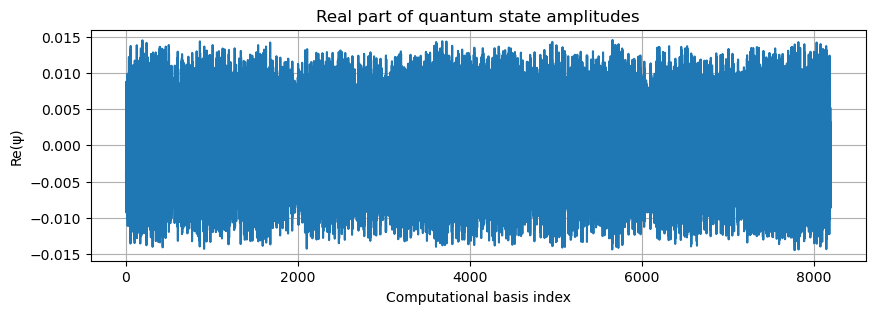

In [10]:
import numpy as np
import matplotlib.pyplot as plt
real_part = np.real(quimb_accoustic_circuit.psi.to_dense().flatten())
plt.figure(figsize=(10, 3))
plt.plot(real_part)
plt.xlabel("Computational basis index")
plt.ylabel("Re(ψ)")
plt.title("Real part of quantum state amplitudes")
plt.grid(True)
plt.show()

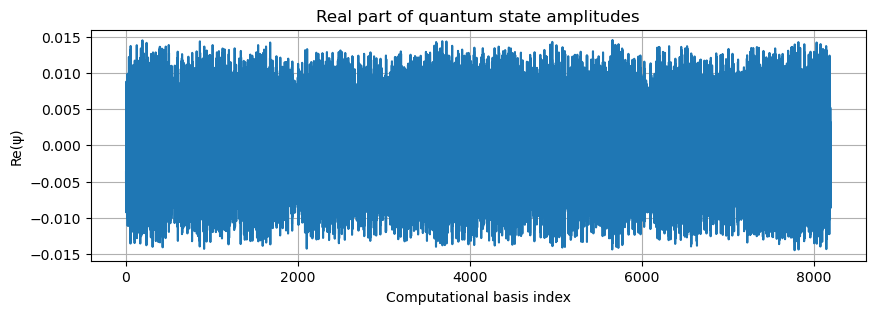

In [11]:
target_state = np.load("taued_target_state.npy")
real_part = np.real(target_state)
plt.figure(figsize=(10, 3))
plt.plot(real_part)
plt.xlabel("Computational basis index")
plt.ylabel("Re(ψ)")
plt.title("Real part of quantum state amplitudes")
plt.grid(True)
plt.show()

This is indeed the right state that I needed. I can now simulate shadow testing on it and see if it matches what I needed

In [13]:
def simple_histogram(data,title):
    mean = np.mean(data)
    plt.figure(figsize=(8,5))

    plt.hist(
        data,
        bins=50,
        color='grey',
        edgecolor='black',
        alpha=0.8
    )

    plt.axvline(
        mean,
        linestyle='--',
        linewidth=2,
        label=f"Mean = {mean:.3f}"
    )

    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [12]:
def generate_state_with_fidelity(target_state, fidelity):
    target_state = target_state.flatten()
    target_state = target_state / np.linalg.norm(target_state)

    dim = len(target_state)

    # Random complex noise vector (1D ONLY)
    noise = np.random.normal(size=dim) + 1j*np.random.normal(size=dim)
    noise = noise / np.linalg.norm(noise)

    # Linear combination (safe elementwise scaling)
    noisy_state = (
        np.sqrt(fidelity) * target_state
        + np.sqrt(1 - fidelity) * noise
    )

    return noisy_state / np.linalg.norm(noisy_state)

In [13]:
num_qubits=13
#This here will generate a whole bunch of data on different wrong states and plot the fidelity and shadow overlap together. Will keep saving to shadow_vs_fidelity.
import numpy as np
import os

filename = "shadows_vs_fidelity.npy"

if os.path.exists(filename):
    shadows_vs_fidelity = list(np.load(filename, allow_pickle=True))
    print(f"Loaded {len(shadows_vs_fidelity)} existing points.")
else:
    print("No file!")
rng = np.random.default_rng()
num_trials=1
shots_per_trial=1000
for trial in range(num_trials):
    fidelity=rng.random()
    target=quimb_accoustic_circuit.psi.to_dense()
    target / np.linalg.norm(target)
    print("generating prepared state with approx fidelity",fidelity)
    psi0=generate_state_with_fidelity(quimb_accoustic_circuit.psi.to_dense(), fidelity)
    psi0 / np.linalg.norm(psi0)
    actual_fidelity=np.abs(np.vdot(psi0, target))**2
    psi0_tn = qtn.MatrixProductState.from_dense(psi0,dims=[2] * 13)
    circuit=qtn.Circuit(13,psi0=psi0_tn)


    #Manuly set the basis chosen if "batching" the random basis measurements.
    basis_select=False

    #Shots is number of times we run the circuit and measure the output
    shots=shots_per_trial
    #{np.round(actual_fidelity,3):.3f}

    estimated_shadow_sample = run_multiple_shadow_overlaps(target,circuit,num_qubits,shots,verbose=False,basis_select=basis_select)
    print(np.mean(estimated_shadow_sample),actual_fidelity)
    shadows_vs_fidelity.append((np.mean(estimated_shadow_sample),actual_fidelity))

np.save("shadows_vs_fidelity.npy", shadows_vs_fidelity)

Loaded 1155 existing points.
generating prepared state with approx fidelity 0.4896899871019543
0.7003724533446132 0.4872803560293647


Loaded 1156 existing points.


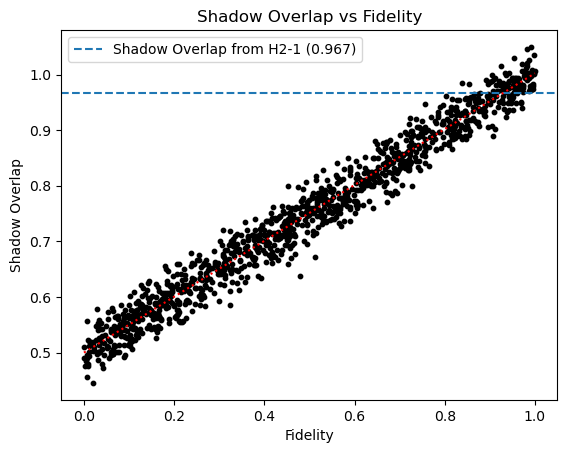

In [14]:
import numpy as np
import os
import matplotlib.pyplot as plt

filename = "shadows_vs_fidelity.npy"

if os.path.exists(filename):
    shadows_vs_fidelity = list(np.load(filename, allow_pickle=True))
    print(f"Loaded {len(shadows_vs_fidelity)} existing points.")
x, y = zip(*shadows_vs_fidelity)   # unzip into two tuples

plt.scatter(y, x, s=10, color='black')
plt.axhline(y=0.967, linestyle='--',label="Shadow Overlap from H2-1 (0.967)")  # '--' is dashed
plt.title("Shadow Overlap vs Fidelity")
plt.ylabel("Shadow Overlap")
plt.xlabel("Fidelity")
m, b = np.polyfit(y, x, 1)
x_fit = np.linspace(min(y), max(y), 100)
y_fit = m * x_fit + b

plt.plot(x_fit, y_fit, 'r:')
plt.legend()
plt.show()

Loaded 1156 existing points.


C:\Users\archi\AppData\Local\Temp\ipykernel_35208\3293632648.py:25: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "b:" (-> linestyle=':'). The keyword argument will take precedence.
  plt.plot(x_fit, y_fit, 'b:', linestyle='--',linewidth=1.5)


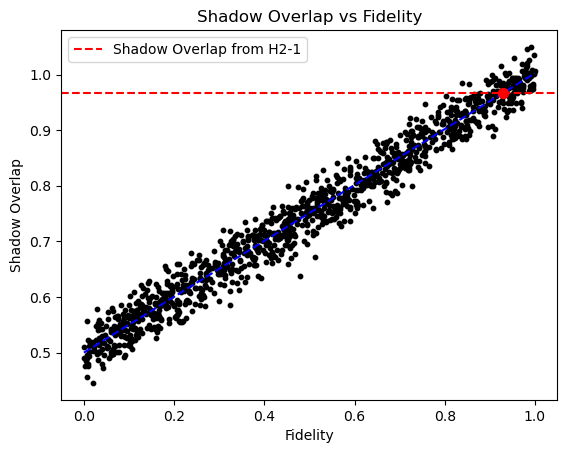

Estimated Fidelity is: 0.929447183173795 from a shadow overlap of 0.967


In [15]:
import numpy as np
import os
import matplotlib.pyplot as plt

filename = "shadows_vs_fidelity.npy"

if os.path.exists(filename):
    shadows_vs_fidelity = list(np.load(filename, allow_pickle=True))
    print(f"Loaded {len(shadows_vs_fidelity)} existing points.")

x, y = zip(*shadows_vs_fidelity)

plt.scatter(y, x, s=10, color='black')

hardware_overlap = 0.967

plt.axhline(y=hardware_overlap,color="red", linestyle='--', label="Shadow Overlap from H2-1")

# best fit
m, b = np.polyfit(y, x, 1)

x_fit = np.linspace(min(y), max(y), 100)
y_fit = m*x_fit + b

plt.plot(x_fit, y_fit, 'b:', linestyle='--',linewidth=1.5)

# intersection
y_intersect = (hardware_overlap - b) / m
x_intersect = hardware_overlap

plt.scatter(y_intersect, x_intersect, color='red', s=50, zorder=5)

plt.title("Shadow Overlap vs Fidelity")
plt.ylabel("Shadow Overlap")
plt.xlabel("Fidelity")
plt.legend()

plt.show()
print("Estimated Fidelity is:", y_intersect, "from a shadow overlap of",x_intersect)

I wonder if the untaued state looks different? dont think it will as its only 1 eigenvalue different. (didnt actually do this)

In [16]:
quimb_accoustic_circuit_untaued=arch_build_circuit_from_kzb_quimb(sorted_k_gates,sorted_z_gates,sorted_b_gates,13,taued=False)

Number of samples: 1000
Mean: 0.9844707165005295
Standard error: 0.02260297290969044
90% confidence interval: [0.9472921345301394, 1.0216492984709198]
BASIS MEASURED IN IS False


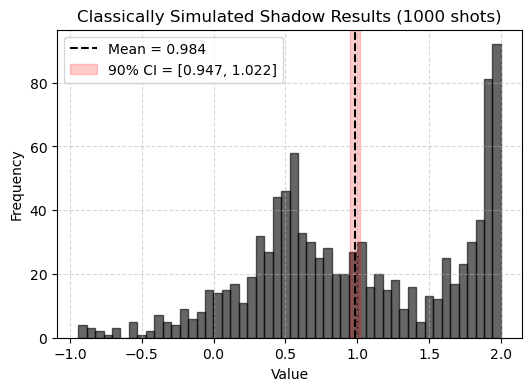

In [17]:
num_qubits=13
circuit=quimb_accoustic_circuit
#check that this is the same as taret state
target=quimb_accoustic_circuit.psi.to_dense()

#Manuly set the basis chosen if "batching" the random basis measurements.
basis_select=False

#Shots is number of times we run the circuit and measure the output
shots=1000

estimated_fideleities_taued = run_multiple_shadow_overlaps(target,circuit,num_qubits,shots,verbose=False,basis_select=basis_select)
confidence_interval_90=get_confidence_interval(estimated_fideleities_taued,confidence=0.90,verbose=True)
'''confidence_interval_95=get_confidence_interval(estimated_fideleities_taued,confidence=0.95,verbose=True)
confidence_interval_99=get_confidence_interval(estimated_fideleities_taued,confidence=0.99,verbose=True)'''
print("BASIS MEASURED IN IS", basis_select)
# {basis_select} basis
plot_single_shot_CI(estimated_fideleities_taued,tau=18,bins=50,title=f"Classically Simulated Shadow Results ({shots} shots)", show_mean=True, ci=0.90,show_fidelity=False)
np.save("shadow_results_noiseless.npy", estimated_fideleities_taued)


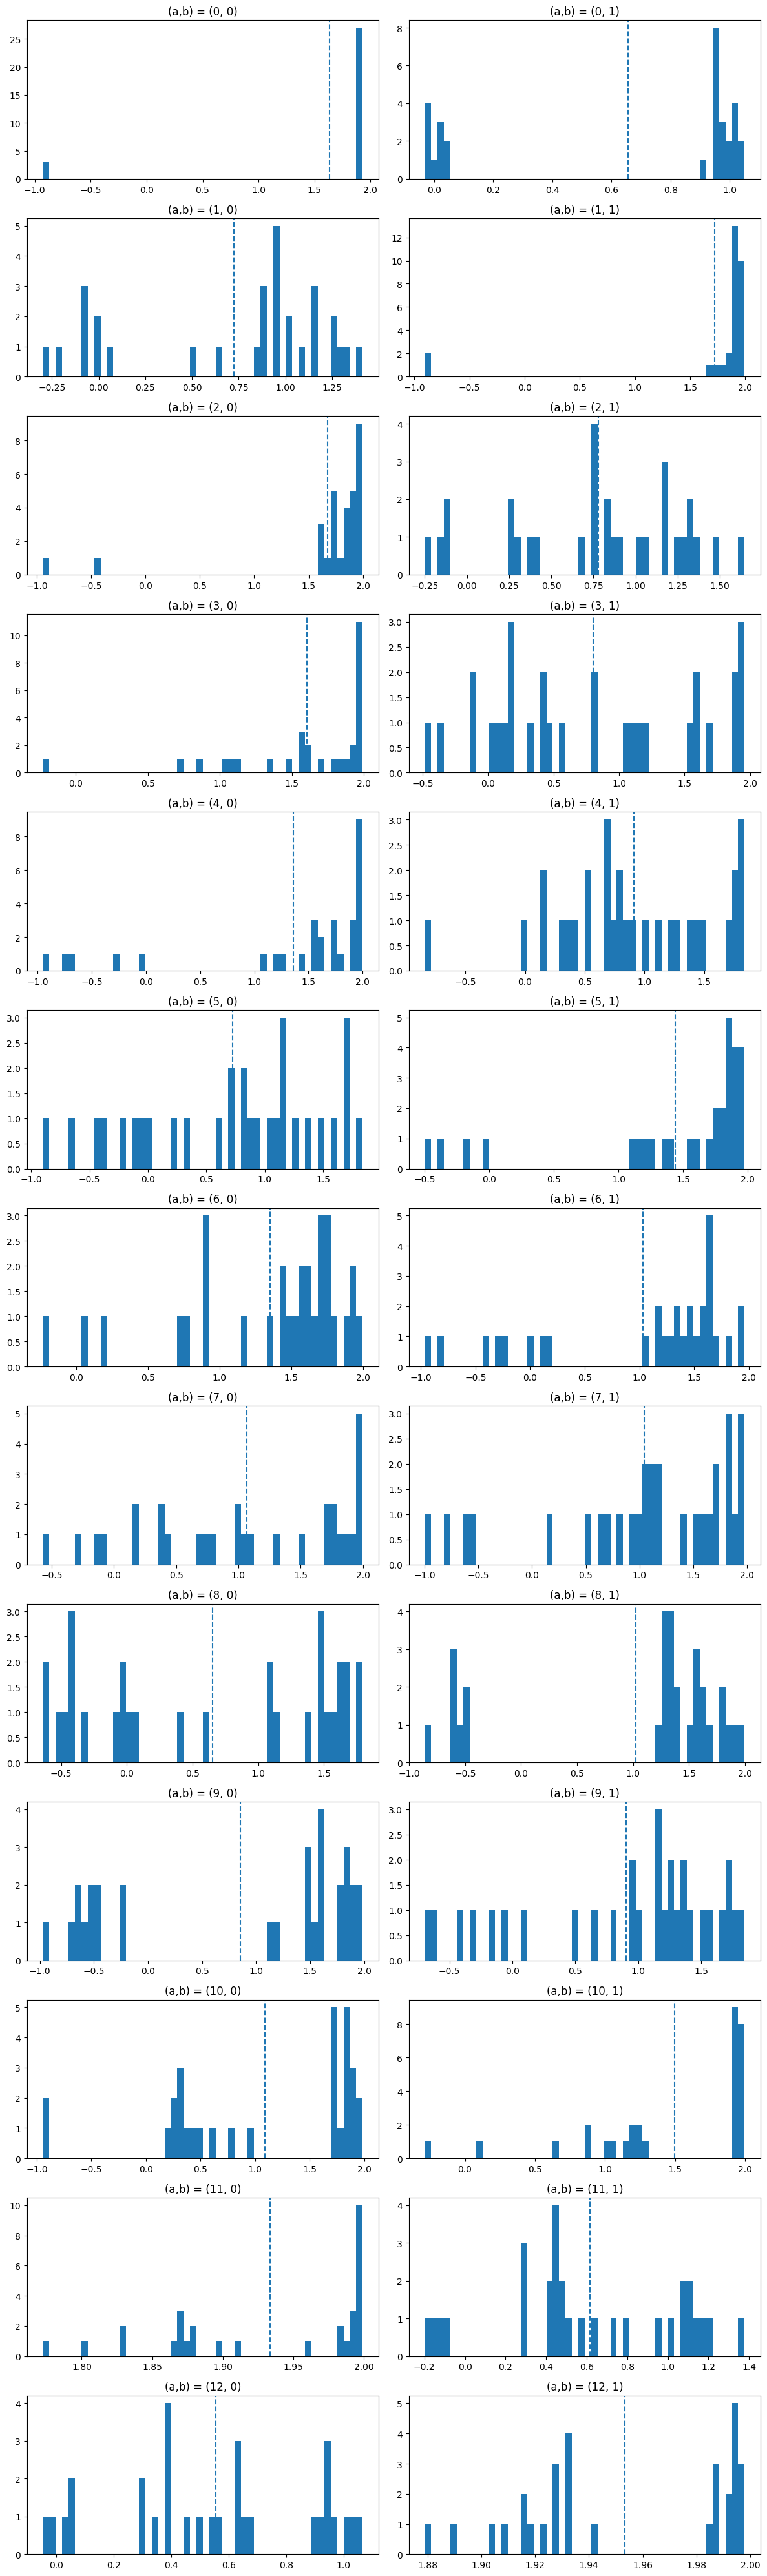

In [125]:
import matplotlib.pyplot as plt

num_qubits = 13
shots = 30

fig, axes = plt.subplots(13, 2, figsize=(12, 40))  # 13 rows, 2 columns

for a in range(13):
    for b in range(2):
        basis_select = (a, b)
        
        estimated_fidelities = run_multiple_shadow_overlaps(
            target,
            circuit,
            num_qubits,
            shots,
            verbose=False,
            basis_select=basis_select
        )

        ax = axes[a, b]

        # plot histogram directly on the axis
        ax.hist(estimated_fidelities, bins=50)
        ax.set_title(f"(a,b) = {basis_select}")
        ax.axvline(sum(estimated_fidelities)/len(estimated_fidelities), linestyle='--')

plt.tight_layout()
plt.show()